# 3-servo: run-up

Start the free servo from rest at 100 % duty on 5 V, hold it for the 52 ms the runway allows, and let it coast to a stop with the bridge open, three cycles each way at the open and the close of two sittings, so the inertia of the rotor and the train reflected to it, the rise, the speed-torque curve through the gears, the dropout rate at full duty and the voltage balance where nothing switches are read on mg90-d inside its own servo.

## Purpose

A motor started from rest at a fixed voltage speeds up along a curve set by its torque, its drag and its inertia. Its rotor obeys

$$J\,a_d = K_t\,i - T_\mathrm{drag}(\omega)$$

under drive and

$$J\,a_c = -T_\mathrm{drag}(\omega)$$

on the coast, with $J$ ("J") the inertia of the rotor plus the train reflected to it, $a_d$ ("a d") the drive's acceleration, $a_c$ ("a c") the coast's acceleration, negative as the rotor slows, $K_t$ ("K t") the torque per amp, $i$ the current, $\omega$ ("omega") the rotor's speed and $T_\mathrm{drag}$ ("T drag") the drag torque of the motor and the train at that speed. Taking the coast's drag at the same speed as the drive's,

$$J\,\bigl(a_d - a_c(\omega)\bigr) = K_t\,i,$$

so the acceleration the current buys over the coast's at the same speed gives $J$ with no drag model. Stage 2's speed-torque notebook read $J$ and the curve on the bare motor of this family. Here the motor turns the servo's train, so the drag is the train's in Super Lube and $J$ is the rotor's plus the reflected train's.

The stage README sets these targets.

- The inertia of the rotor plus the train reflected to it, from 5 V 100 % run-ups from rest.
- The speed-torque curve through the gears.
- The dropout rate at full duty by direction, as the brush state of the sitting.
- The crest less the coast's mean current at 100 %, where nothing switches, as the meterless check of the inductance result's reading term.

At 100 % the bridge holds one leg high and the other low for the whole run, so no edge, brake interval or window enters the volts or the current. The same rows give the voltage balance $X = u - R\,i - L\,di/dt - K_e\,\omega$ along the run-up, with $u$ the terminal volts, $R$ the terminal resistance, $L$ the inductance and $K_e$ ("K e") the back-EMF constant, which this notebook holds against the ladder notebook's two brush-drop tables.

mg90-d is a new motor from a new servo of the same brand, installed in a new, never used MG90 body whose gears were cleaned and regreased by hand with Super Lube. Its motor is not opened, so every number here is read through the servo's two motor leads. The type values come from stage 2, mg90-b the type motor, and are used for comparison only.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, horn free, powered from the DPS-150 bench supply over the board's feed diode, with the board's adapter on its bus at 3 Mbps. The board runs the experiment image, so every drive is open loop with only the raw current trip and the bus dead-man as protections. The sitting runner, `python -m oscnb.sitting servo`, ran the `runup` plan of `stages/3-servo/run-up/plan.py`.

A cycle is one `osc-lab sweep`. It opens with a 500 ms torque-off baseline. Then, in each direction, the servo seeks to the near guard, runs at 100 % toward the far guard, and coasts for 500 ms with the bridge open. The rail is trimmed with torque off before the level, and after every drive the horn goes back to mid travel with the torque off. 5 V at 100 % is the motor's rated 5 V as rail times duty.

`runup` is a bracket, three cycles at the open and the close of a sitting. runup-open-1 and runup-close-1 open and close sitting 1, the servo's first sitting. runup-open-6 and runup-close-6 open and close sitting 6, two days later, after the locked sittings. Twelve cycles in all, 24 run-ups.

The runway. The plan asks for a 200 ms spin. The travel is about 157 motor revolutions, and at full speed the runner cuts the spin so it ends short of the far guard, here to 52 ms. The rotor reaches about 90 % of the first-order fit's asymptote by then, with the current still falling. So a spin holds the rise from stall to 90 % of the settled speed, where $J$, the rise time and the loaded part of the speed-torque curve live, and the coast from about 490 rev/s to rest, which is the drag over the same speeds. It holds no settled speed. The no-load end of the curve, the settled current and the settled dropout rate are extrapolations of a fit past the 52 ms cut, or absent, and every such number below says so.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The four datasets are in `run-up/`, and the two sittings' manifests are `sittings/servo-1.csv` and `sittings/servo-6.csv`.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

from oscnb import boards, coast, cycles, figures, motors, results, ripple
from oscnb import manifest, scales, servos, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

# a quadratic through a short window warns when it is nearly a line, and a
# median over no run-up warns when a time has none; both are expected here
warnings.simplefilter("ignore", np.exceptions.RankWarning)
warnings.simplefilter("ignore", RuntimeWarning)

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS["mg90-d"]         # its motor, with its counted parts
BOARD_KEY = "dev-v006-2A-D"             # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
RUNUP = PAIR_DIR / "run-up"             # the four datasets
# the bracket's four sets: the open and close of sittings 1 and 6
SETS = ["runup-open-1", "runup-close-1", "runup-open-6", "runup-close-6"]
SITTING_OF = {"runup-open-1": 1, "runup-close-1": 1,
              "runup-open-6": 6, "runup-close-6": 6}
MANIFESTS = {s: PAIR_DIR / "sittings" / f"servo-{s}.csv" for s in (1, 6)}
FS = 20_000                             # rows per second, the control tick
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(RUNUP))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes, "
      f"{MOTOR.ripple_per_rev} ripple events per rev, rows at {FS} Hz")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/run-up
the motor of MG90 clone d: 3 slots, 2 brushes, 6 ripple events per rev, rows at 20000 Hz


Every sweep names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry.

In [3]:
def board_of(meta, where=""):
    # the board a sweep's meta names, its sense block checked
    board = boards.from_meta(meta)      # identified from the data itself
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    if board.key != BOARD_KEY:          # the board this notebook expects
        raise ValueError(f"{where}: board {board.key}, not {BOARD_KEY}")
    return board


def load(folder):
    # (frame, meta, board) of one sweep, through the chain
    frame, meta = tel.load(folder)
    return frame, meta, board_of(meta, str(results.rel(folder)))

### Stage 1 values carried in

The current goes through the current-scale result and the terminal and rail volts through the terminal-chain result, both graded on this board in stage 1. Current-scale's grade is DC at 100 % duty, the same bridge state as these run-ups, so its in-drive offset applies here as measured.

In [4]:
SCALES = scales.load(BOARD_KEY)         # stage 1's current and volt lines
# multiplied as the stage 2 files were computed, never divided: a ripple
# count downstream turns a last-bit change into a moved result
A_PER_COUNT = SCALES.a_per_count        # amps per count over the zero
V_PER_COUNT = SCALES.v_per_count        # volts per count of tap difference
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
I_DRIVE_OFFSET = SCALES.drive_offset_counts  # the in-drive current offset
CURRENT = results.read("1-board", "current-scale", pair=BOARD_KEY)
I_CLASS_PCT = CURRENT["counts_per_a_class_pct"]["value"]   # absolute class
SCALES.describe()
print(f"a count over the zero is {A_PER_COUNT * 1e3:.3f} mA, a count of tap "
      f"difference {V_PER_COUNT * 1e3:.3f} mV, in-drive offset "
      f"{I_DRIVE_OFFSET:.2f} counts, the current's absolute class "
      f"{I_CLASS_PCT:.1f} %")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
a count over the zero is 0.881 mA, a count of tap difference 4.026 mV, in-drive offset 5.26 counts, the current's absolute class 2.0 %


### Stage 3 values carried in

The resistance notebook's locked 100 % laps give $R$, the inductance notebook gives $L$ and its crest less window mean at partial duty, the reading term this notebook checks at 100 %. The ladder notebook gives $K_e$ from 108 coasts, the headline $K_e$ here, the awake zero's line on the rail, its two brush-drop tables, A and B, and its 3.7 V 100 % rungs. The sag notebook's $K_e$ is the alternative. $K_t = K_e$ in SI units, untested, as in stage 2.

In [5]:
RES = results.read("3-servo", "resistance", pair=PAIR)
IND = results.read("3-servo", "inductance", pair=PAIR)
SAG = results.read("3-servo", "sag", pair=PAIR)
LADDER = results.read("3-servo", "ladder", pair=PAIR)
R_LOCKED = RES["r_term_ohm"]["value"]   # ohm, the locked 100 % laps
R_LOCKED_LO, R_LOCKED_HI = RES["r_term_ohm"]["lo"], RES["r_term_ohm"]["hi"]
R_LOCKED_AMPS = RES["r_term_amps"]["value"]   # A, the laps' current
L_H = IND["l_mh"]["value"] * 1e-3       # H, the inductance
KE_LADDER_MV = LADDER["ke_mv_per_rev_s"]["value"]   # mV per rev/s
KE_SAG_MV = SAG["ke_mv_per_rev_s"]["value"]         # mV per rev/s
KE = KE_LADDER_MV * 1e-3 / (2 * np.pi)  # V s/rad, the headline Ke
KE_SAG = KE_SAG_MV * 1e-3 / (2 * np.pi)  # V s/rad, the alternative
KT = KE                                 # N m/A, taken equal, untested
AWAKE_PER_V = LADDER["zero_awake_step_per_v_counts"]["value"]
AWAKE_ICPT = LADDER["zero_awake_step_intercept_counts"]["value"]
TABLE_A = LADDER["v_b_mv"]["tables"]["A - g V_on"]         # mV by knot
TABLE_B = LADDER["v_b_mv"]["tables"]["B - g (1-D) V_on"]   # mV by knot
CREST_LESS_MEAN = IND["crest_sample_less_window_mean_ma"]  # mA by duty
print(f"R {R_LOCKED:.4f} ohm ({R_LOCKED_LO:.4f} to {R_LOCKED_HI:.4f}) at "
      f"{R_LOCKED_AMPS:.3f} A; L {L_H * 1e3:.3f} mH")
print(f"Ke ladder {KE_LADDER_MV:.4f} mV per rev/s = {KE * 1e3:.4f} mV "
      f"s/rad; sag {KE_SAG_MV:.4f}")
print(f"ladder awake zero step {AWAKE_PER_V:.3f} counts/V "
      f"{AWAKE_ICPT:+.2f}, {AWAKE_PER_V * 5 + AWAKE_ICPT:.2f} at 5 V")
print("inductance's crest less window mean: " + ", ".join(
    f"{k} % {v['value']:.2f} mA" for k, v in CREST_LESS_MEAN.items()))

R 4.2189 ohm (4.2065 to 4.2300) at 0.767 A; L 0.820 mH
Ke ladder 7.2828 mV per rev/s = 1.1591 mV s/rad; sag 7.3268
ladder awake zero step 1.811 counts/V -3.80, 5.26 at 5 V
inductance's crest less window mean: 25 % 0.56 mA, 40 % 0.46 mA


### Stage 2 type values carried in

mg90-b's speed-torque result gives the type's $J$, rise times, peak power, settled dropout rates and curve, bemf-coast its $K_e$, identification its brush-drop table and no-load-current its bare drag under drive on 5 V with the reading term out. They are comparisons. The type's drag curve enters twice, its value at rest as the seed of the count's first turns, as speed-torque seeded it, and the whole curve as one alternative route to $J$.

In [6]:
TYPE_KEY = SERVO.type_motor             # mg90-b
ST_TYPE = results.read("2-motor", "speed-torque", pair=TYPE_KEY)
BC_TYPE = results.read("2-motor", "bemf-coast", pair=TYPE_KEY)
ID_TYPE = results.read("2-motor", "identification", pair=TYPE_KEY)
NL_TYPE = results.read("2-motor", "no-load-current", pair=TYPE_KEY)
J_TYPE = ST_TYPE["j_kg_m2"]             # kg m^2, the bare rotor's J
RISE_TYPE_MS = ST_TYPE["measured_rise_63_ms"]       # ms, per direction
PEAK_POWER_TYPE = ST_TYPE["peak_power_w"]           # W
DROPOUTS_TYPE = ST_TYPE["dropouts_settled_per_s_by_direction"]
KE_TYPE_MV = BC_TYPE["ke_mv_per_rev_s"]["value"]    # mV per rev/s
VB_TYPE = ID_TYPE["v_b_mv"]["table"]    # the type's brush-drop table, mV
print(f"{TYPE_KEY}: J {J_TYPE['value'] * 1e9:.3f} ({J_TYPE['lo'] * 1e9:.2f}"
      f" to {J_TYPE['hi'] * 1e9:.2f}) x 1e-9 kg m^2, rise to 63 % "
      f"{RISE_TYPE_MS['+1']['value']:.1f} / "
      f"{RISE_TYPE_MS['-1']['value']:.1f} ms, peak power "
      f"{PEAK_POWER_TYPE['value']:.3f} W")
print(f"settled dropouts {DROPOUTS_TYPE['+1']['value']:.0f} / "
      f"{DROPOUTS_TYPE['-1']['value']:.0f} per s, Ke {KE_TYPE_MV:.4f} mV "
      f"per rev/s")

mg90-b: J 6.255 (5.83 to 6.83) x 1e-9 kg m^2, rise to 63 % 19.0 / 19.5 ms, peak power 0.976 W
settled dropouts 958 / 467 per s, Ke 7.3411 mV per rev/s


`type_drag` turns no-load-current's fit of the bare motor's settled current against speed on 5 V, with the reading term out, into a function of rad/s. Under its lowest fitted speed it holds the value there, as speed-torque's `drag_curve` did.

In [7]:
def type_drag_curve(level="5 V"):
    # the type's bare drag current under drive, A, as a function of rad/s
    fit = NL_TYPE["drive_drag_by_level_meter"][level]
    a, b = fit["a_a"]["value"], fit["b_a"]["value"]   # A, A per log
    floor = 2 * np.pi * fit["speed_range_rev_s"]["lo"]   # rad/s, held
    ref = 2 * np.pi * 100.0             # rad/s, the fit's reference

    def drag(w):
        w = np.maximum(np.asarray(w, float), floor)
        return a + b * np.log(w / ref)
    return drag


TYPE_DRAG = type_drag_curve()
print(f"type drag {TYPE_DRAG(0.0) * 1e3:.1f} mA at rest, "
      f"{TYPE_DRAG(2 * np.pi * 460) * 1e3:.1f} mA at 460 rev/s")

type drag 43.5 mA at rest, 86.0 mA at 460 rev/s


The servo's counted parts, and the constants of the method, each with its unit and reason.

In [8]:
N_R = MOTOR.ripple_per_rev              # ripple events per motor rev
GEAR = SERVO.gear_ratio                 # counted teeth, motor revs per out
# the pot's nominal counts per motor revolution, a sizing number pot-table
# grades, so the pot speed is a seed only and never a result
COUNTS_PER_MOTOR_REV = SERVO.counts_per_motor_rev
EDGE_ROWS = 40          # 2 ms, no dropout read inside the rise
TAIL_ROWS = 20          # 1 ms, the running mean's edge at the drive's end
COAST_SETTLE_ROWS = 20  # 1 ms past the cut, the taps settle (oscnb.coast)
COAST_TAIL_ROWS = 2000  # the coast's last 100 ms, the awake zero
POT_SEED_S = (0.015, 0.045)   # s, where the pot slope scales the seed
POT_SLOPE_HALF_ROWS = 40      # +/- 2 ms, the pot slope's local line
print(f"{N_R} ripple events per motor rev, gear {GEAR:.2f}:1, "
      f"{COUNTS_PER_MOTOR_REV:.2f} pot counts per motor rev (nominal)")

6 ripple events per motor rev, gear 308.05:1, 23.14 pot counts per motor rev (nominal)


In [9]:
HALF_S = ripple.FIT_HALF_S   # s, the +/- half width of the acceleration fits
STALL_ROWS = slice(16, 30)    # 0.8 to 1.5 ms, the stall end's rows
SPEED_BIN_REV_S = 25.0  # rev/s, the coast deceleration table's bin
TORQUE_BIN_MNM = 0.05   # mN m, the curve's bin width, as stage 2
BIN_MIN = 10            # fits a pooled curve bin needs
DIR_BIN_MIN = 5         # fits a per-direction curve bin needs
RISE_FRAC = 0.632       # the rise time's share of the speed
# the knots of the ladder's tables, rev/s, where X is compared
KNOTS = [150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0]
KEYS = ["set", "k", "dir"]    # one run-up: its set, cycle and direction
TWO_PI = 2 * np.pi

### cycles.csv

One row per cycle of a dataset. `k` is the cycle number, `volts_set` the rail level, `dps_read` the DPS's readback after the trim, a setpoint echo, `vsys_read` the rail the runner read at the trim, `duty_pct` the duty, `repeat` the cycle within the rung, `t_start` and `t_end` its host times, `folder` its folder, `kick_pct` and `kick_ms` unused here, and `spin_ms` the window the runner allowed after the runway cut.

In [10]:
CYCLES = {name: cycles.load(RUNUP / name) for name in SETS}
show(CYCLES["runup-open-1"], n=None)
for name, cy in CYCLES.items():
    gap = np.diff(cy["t_start"].to_numpy())   # s between cycles
    print(f"{name}: {len(cy)} cycles at {cy['volts_set'].iloc[0]:g} V "
          f"{cy['duty_pct'].iloc[0]} %, spin_ms {sorted(cy['spin_ms'])}, "
          f"vsys_read {cy['vsys_read'].min():.3f} to "
          f"{cy['vsys_read'].max():.3f} V, {gap.mean():.0f} s apart")

,k,volts_set,dps_read,vsys_read,duty_pct,repeat,t_start,t_end,folder,kick_pct,kick_ms,spin_ms
0,0,5.000,5.250,5.010,100,0,1793934986.283,1793935037.504,cycles/0,0,0,52
1,1,5.000,5.250,5.010,100,1,1793935057.511,1793935108.734,cycles/1,0,0,52
2,2,5.000,5.250,5.010,100,2,1793935128.739,1793935179.897,cycles/2,0,0,52


runup-open-1: 3 cycles at 5 V 100 %, spin_ms [52, 52, 52], vsys_read 5.010 to 5.010 V, 71 s apart
runup-close-1: 3 cycles at 5 V 100 %, spin_ms [52, 52, 52], vsys_read 4.986 to 4.986 V, 78 s apart
runup-open-6: 3 cycles at 5 V 100 %, spin_ms [52, 52, 52], vsys_read 4.991 to 4.991 V, 76 s apart
runup-close-6: 3 cycles at 5 V 100 %, spin_ms [52, 52, 52], vsys_read 4.991 to 4.991 V, 78 s apart


The runner allowed 52 ms of the 200 ms the plan asks for in every cycle, the runway's cut at full speed.

### The manifests

Before every sweep the runner reads the board's registers with torque off and logs them in the sitting's manifest, `pos`, `ntc_raw` and `vbus_raw`. The run-up's telemetry rows carry no `vbus_raw` and no `ntc_raw`, so this probe is the only reading of the rail and the board temperature each sweep has. The parser is `oscnb.manifest`'s, keyed by the probe's full path.

In [11]:
# the sweep's folder as the manifest names it -> the probe before it
PROBES = {s: manifest.manifest_probes(p) for s, p in MANIFESTS.items()}
for name in SETS:
    keys = [f"telemetry/{PAIR}/run-up/{name}/{f}"
            for f in CYCLES[name]["folder"]]
    got = [PROBES[SITTING_OF[name]].get(k) for k in keys]
    vbus = [p["vbus_raw"] for p in got if p]
    print(f"{name}: {len(vbus)} of {len(keys)} sweeps carry a probe, "
          f"vbus_raw {min(vbus)} to {max(vbus)}")

runup-open-1: 3 of 3 sweeps carry a probe, vbus_raw 1238 to 1240
runup-close-1: 3 of 3 sweeps carry a probe, vbus_raw 1239 to 1244
runup-open-6: 3 of 3 sweeps carry a probe, vbus_raw 1239 to 1245
runup-close-6: 3 of 3 sweeps carry a probe, vbus_raw 1239 to 1244


### cycles/K/sweep.csv and meta.json

Each cycle is `sweep.csv`, `meta.json` and `segments.csv`, one row per control tick at 20 kHz. Segment 0 is the half second torque-off baseline. Segments 1 and 2 are the spin and the coast in direction +1, and 3 and 4 the same in direction -1. `pos` is the pot in counts, `current_raw`, `vmotor_a` and `vmotor_b` ADC counts of the shunt amplifier and the two terminal taps at the crest sample, the conversion near the middle of each PWM on-window, `duty_counts` the applied window in timer ticks of a 1200 tick half period, signed by the direction, and `window_valid` whether the window met the sampling floors. At 100 % the window is the whole period, so the crest sample is the period's mean. One cycle of runup-open-1.

In [12]:
EXAMPLE = load(CYCLES["runup-open-1"].folder(0))
df, meta, board = EXAMPLE
segs = df["seg"].value_counts().sort_index().to_dict()
print(f"segments {segs}, schedule {meta['schedule']}, dirs {meta['dirs']}, "
      f"rows dropped {meta['rows_dropped']}")
print(f"rows carrying vbus_raw {int(df['vbus_raw'].notna().sum())}, plant "
      f"stamp {meta['plant']['plant_stamp']} "
      f"({meta['plant']['stamp_verdict']}), tick {meta['tick_hz']} Hz")
show(df[["seg", "tick", "pos", "current_raw", "vmotor_a", "vmotor_b",
         "duty_counts", "window_valid"]].iloc[10000:10004], n=None)

segments {0: 10000, 1: 1040, 2: 10000, 3: 1040, 4: 10000}, schedule ['100@52', 'coast:500'], dirs [1, -1], rows dropped 0
rows carrying vbus_raw 0, plant stamp 0x9c45 (match), tick 20000 Hz


,seg,tick,pos,current_raw,vmotor_a,vmotor_b,duty_counts,window_valid
10000,1,0,312,1213,775,776,0,0
10001,1,1,311,1211,774,775,0,0
10002,1,2,311,1210,772,774,0,0
10003,1,3,311,1211,771,772,0,0


## Raw traces

The cycle's channels against its rows, the current, the two taps, the applied window as a percent of the half period and the pot. The thing to see is how short the drive is next to the coast that follows it.

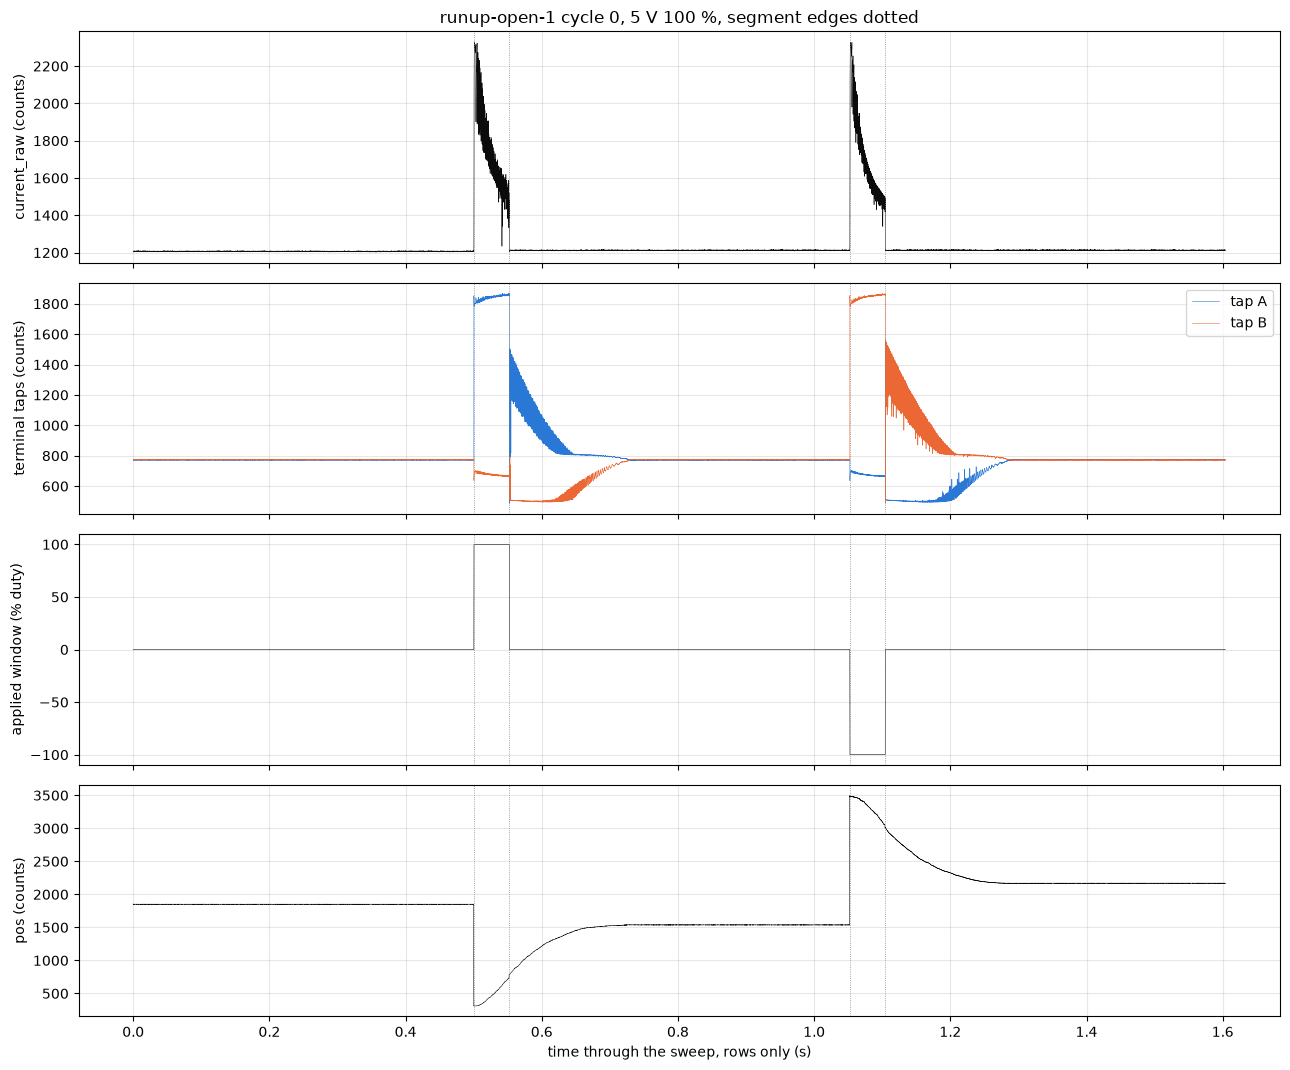

In [13]:
def overview(df, board, title):
    # a cycle's raw channels against its rows, segment edges dotted
    duty_pct = df["duty_counts"] / board.pwm_arr * 100
    channels = [
        ("current_raw (counts)", [(df["current_raw"], INK)]),
        ("terminal taps (counts)", [(df["vmotor_a"], BLUE, "tap A"),
                                    (df["vmotor_b"], ORANGE, "tap B")]),
        ("applied window (% duty)", [(duty_pct, INK)]),
        ("pos (counts)", [(df["pos"], INK)]),
    ]
    fig, ax = figures.sweep_overview(df, FS, channels, title=title)
    figures.finish(fig)


overview(df, board, "runup-open-1 cycle 0, 5 V 100 %, segment edges dotted")

The baseline, the run-up and coast in direction +1, then in direction -1. Each drive is a block of about a thousand rows at the start of its segment, and the coast that follows it is ten times longer. The pot crosses about 440 counts in the drive and another 880 in the coast.

The two drives and the start of the first coast in raw counts, against the ms from the drive's first row. The thing to see is the current's jump to its stall value in the first millisecond and its fall as the rotor gathers speed, the terminal difference rising the other way, and the coast's tap difference carrying the motor's own EMF with its ripple.

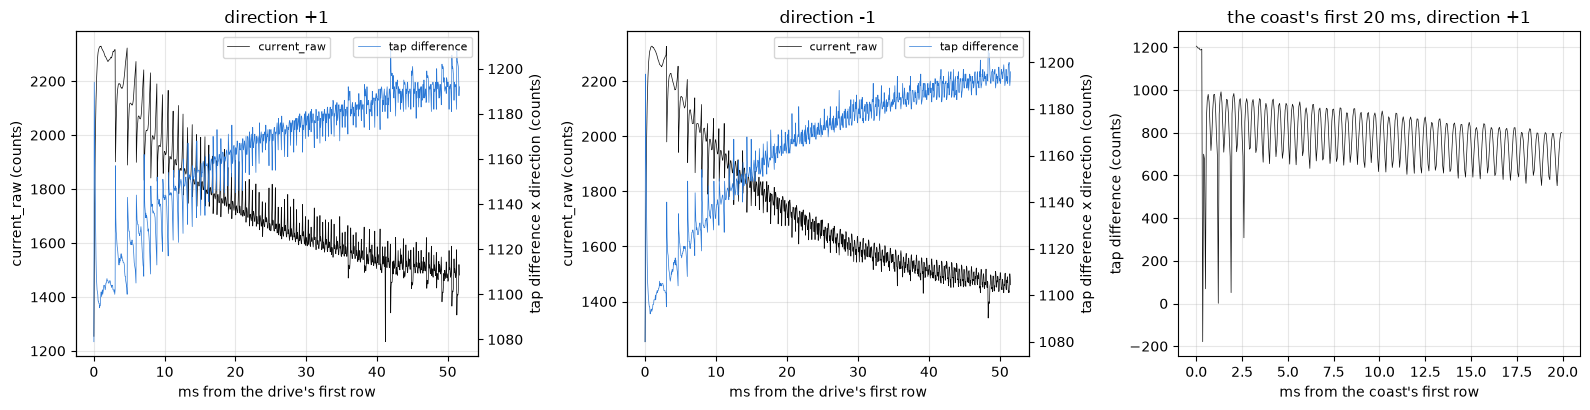

In [14]:
def drive_and_coast(df):
    # per direction the driven rows and the coast, in raw counts
    out = {}
    for d, spin, co in coast.pairs(df):
        g = spin.iloc[tel.drive_start(spin):]   # from the first driven row
        out[d] = (g, co)
    return out


RAW_EX = drive_and_coast(df)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, d in zip(ax, (1, -1)):
    g, _ = RAW_EX[d]
    ms = np.arange(len(g)) / FS * 1e3   # ms from the drive's first row
    a.plot(ms, g["current_raw"], lw=0.5, color=INK, label="current_raw")
    twin = a.twinx()
    taps = (g["vmotor_a"] - g["vmotor_b"]) * d   # drive reads positive
    twin.plot(ms, taps, lw=0.5, color=BLUE, label="tap difference")
    twin.set_ylabel("tap difference x direction (counts)")
    a.legend(loc="upper center", fontsize=8)
    twin.legend(loc="upper right", fontsize=8)
    figures.label(a, x="ms from the drive's first row",
                  y="current_raw (counts)", title=f"direction {d:+d}")
g, co = RAW_EX[1]
ms = np.arange(400) / FS * 1e3          # the coast's first 20 ms
ax[2].plot(ms, (co["vmotor_a"] - co["vmotor_b"]).iloc[:400], lw=0.5,
           color=INK)
figures.label(ax[2], x="ms from the coast's first row",
              y="tap difference (counts)",
              title="the coast's first 20 ms, direction +1")
figures.finish(fig)

The current rises to about 2320 counts within a millisecond, over a torque-off zero of 1207, and drops of a few hundred counts in one row mark the first commutations. By the cut at 52 ms it has fallen to about 1480 counts, a quarter of its rise over the zero. The tap difference rises from about 1100 to 1190 counts as the supply's sag eases. In the coast the tap difference falls from about 1200 counts to about 720 in 20 ms with a six-per-revolution ripple on it, the rotor's EMF with the bridge open, and a few open rows fall to near zero.

## Method

### The chain

Every number goes through the chain the earlier stages built. The board is identified from each sweep's sense block and checked. The current $i$ is the crest sample over the sweep's own torque-off zero with current-scale's in-drive offset taken out. At 100 % the crest sample is the period's mean. The awake-zero current, beside it, takes the coast's last 100 ms as the zero instead, the open bridge with the rotor at rest. The terminal volts $u$ are the tap difference through terminal-chain, signed by the direction so drive reads positive. The rail and the board's NTC are the manifest's probe before the sweep.

Every run-up of the four sets with its coast, read through the chain.

In [15]:
def awake_zero_counts(coast_rows):
    # the current channel's mean over the coast's last 100 ms, the open
    # bridge with the rotor at rest, the awake zero
    return float(coast_rows["current_raw"].iloc[-COAST_TAIL_ROWS:].mean())


def sweep_conditions(name, sw):
    # a sweep's frame, meta and board, its torque-off zeros, and the
    # rail and NTC from the manifest's probe before it
    df, meta, board = load(CYCLES[name].folder(sw["k"]))
    assert meta["tick_hz"] == FS
    zero_i, zero_e = tel.rest_zeros(df)     # the torque-off zeros
    tail = f"telemetry/{PAIR}/run-up/{name}/cycles/{int(sw['k'])}"
    probe = PROBES[SITTING_OF[name]].get(tail)
    rail_v = float(SCALES.rail_v(probe["vbus_raw"])) if probe else np.nan
    ntc_c = float(board.ntc_c_beta(probe["ntc_raw"])) if probe else np.nan
    return {"df": df, "meta": meta, "board": board, "zero_i": zero_i,
            "zero_e": zero_e, "rail_v": rail_v, "ntc_c": ntc_c}

In [16]:
def run_entry(name, sw, d, spin, co, c):
    # one run-up from its first driven row, with its coast and checks
    on = tel.drive_start(spin)          # rows before the drive starts
    g = spin.iloc[on:]
    counts = g["current_raw"].to_numpy(float)
    taps = (g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d
    window = np.abs(g["duty_counts"].to_numpy())
    awake = awake_zero_counts(co)
    return {
        "set": name, "sitting": SITTING_OF[name], "k": int(sw["k"]),
        "dir": d, "rows_before": on, "t_start": float(sw["t_start"]),
        "spin_ms": int(sw["spin_ms"]),
        "held": bool((window == c["board"].pwm_arr).all()),
        "window_valid_all": bool((g["window_valid"] == 1).all()),
        # multiplication forms: a count downstream moves with the last bit
        "i": (counts - c["zero_i"] - I_DRIVE_OFFSET) * A_PER_COUNT,
        "i_awake": (counts - awake) * A_PER_COUNT,
        "u": (taps - TAP_OFFSET) * V_PER_COUNT,
        "pos": g["pos"].to_numpy(float),
        "raw_max": int(g["current_raw"].max()),
        "coast": co, "zero_i": c["zero_i"], "zero_e": c["zero_e"],
        "awake_zero": awake, "awake_step": awake - c["zero_i"],
        "missing": int(tel.gaps(c["df"]).sum()),
        "rows_dropped": int(c["meta"]["rows_dropped"]),
        "rail_v": c["rail_v"], "ntc_c": c["ntc_c"],
        "vsys_read": float(sw["vsys_read"])}


def run_tag(r):
    # a run-up's name: its set, cycle and direction
    return f"{r['set']} k{r['k']} {r['dir']:+d}"

In [17]:
RUN_LIST = []
for name in SETS:
    for _, sw in CYCLES[name].iterrows():
        cond = sweep_conditions(name, sw)
        for d, spin, co in coast.pairs(cond["df"]):
            RUN_LIST.append(run_entry(name, sw, d, spin, co, cond))
print(f"{len(RUN_LIST)} run-ups, {RUN_LIST[0]['spin_ms']} ms each, "
      f"{min(len(r['i']) for r in RUN_LIST)} to "
      f"{max(len(r['i']) for r in RUN_LIST)} driven rows")

24 run-ups, 52 ms each, 1031 to 1040 driven rows


### The dropout rows

A dropout row is a row where the brush path opens for a moment and the crest current falls to near the zero. `tel.dropout_rows` marks a row whose current over the zero is under a quarter of the current around it, here a running mean since the current falls through the run-up. The first 2 ms, the current's rise, and the last millisecond, where the running mean meets the cut, are left out.

In [18]:
def open_mask(current):
    # the dropout rows, the quarter rule against a running mean
    mask = tel.dropout_rows(current, coast.local_mean(current))
    mask[:EDGE_ROWS] = False            # the rise
    mask[-TAIL_ROWS:] = False           # the running mean's edge
    return mask

### The ripple tach, seeded by the pot

A brushed motor with $N_r$ ("N r") commutation events per revolution, 3 slots times 2 brushes here, puts a ripple at $N_r$ times its revolutions per second on its current. Through a run-up that line sweeps from zero to over 2.9 kHz, so a fixed band-pass does not follow it. The tach is stage 2 speed-torque's order tracking. The current is resampled onto a rough angle, the integral of a rough speed, with 16 samples per ripple cycle, so the ripple sits at one fixed frequency on that grid whatever the speed. There it is band-passed at one cycle per sixth of a revolution, plus or minus 25 %, and its upward zero crossings are the commutation events. The order count is `oscnb.ripple`'s.

The repair, one missed or extra crossing at a time. An interval much shorter than the rolling median of its neighbors loses a crossing if merging it with a neighbor lands near the median, and an interval much longer than the median is split evenly.

The rough speed for the first pass is new here. Stage 2 seeded the bare motor's count from its coast's line. On the servo the seed is the EMF the terminal volts leave through $R$ and $L$, $u - R\,i - L\,di/dt$, over $K_e$, smoothed and clipped at zero, then scaled so its mean over 15 to 45 ms lands on the pot's slope there through the gear. The pot sets the band and the count decides. The pot's slope is a line through its counts over plus or minus 2 ms, through the nominal pot counts per motor revolution, and signed by the direction like the taps. The pot never enters a result, and the EMF is never trimmed against it. The EMF-only seed, the same rough speed left unscaled, is counted beside it as a check.

In [19]:
def pot_speed_rev_s(pos, half=POT_SLOPE_HALF_ROWS):
    # the pot's slope as motor rev/s through the nominal pot slope and
    # the gear, a seed only, never a result
    return ripple.local_line_slope(pos, half) * FS / COUNTS_PER_MOTOR_REV

Five passes, each re-reading the crossings on the angle the last pass counted. The first two crossings past the first millisecond sit at the band-pass's edge and are dropped. Before the tenth crossing the speed is the current's integral from rest, less the type's drag at rest, scaled to the count's speed at that crossing, as speed-torque read the first turns.

In [20]:
def count_run(r, seed="pot"):
    # the order count of one run-up, seeded by the EMF the volts leave
    # through R and L over Ke, scaled to the pot's slope over POT_SEED_S
    # (seed "pot") or as the EMF gives it (seed "emf"); the pot runs the
    # servo's way, signed by the direction like the taps
    w_pot = pot_speed_rev_s(r["pos"]) * 2 * np.pi * r["dir"]
    rough, scale = ripple.rough_speed(r["i"], r["u"], w_pot, R_LOCKED, L_H,
                                      KE, POT_SEED_S, seed=seed)
    count = ripple.count_speed(r["i"], rough, I_DRAG0, N_R)
    return {**count, "pot_scale": scale, "w_pot": w_pot}


I_DRAG0 = float(TYPE_DRAG(0.0))        # A, the type's drag at rest, a seed

### The turn windows and the acceleration fits

From the crossings two tables follow. A turn window spans six crossings, one revolution, and its speed is $2\pi$ over its length, with the window's mean current and volts over its rows less the dropout rows. An acceleration fit is a quadratic of the counted angle on time over plus or minus 5 ms, centered every 0.5 ms, whose first coefficient is the speed $\omega$ and twice its second the acceleration $a_d$, with the mean current and volts over the same rows and the angle residual's sd.

Two flags keep a miscounted stretch out. A turn window that holds a crossing too many or too few reads 7/6 or 5/6 of its neighbors, so each window is held against a quadratic in time through the 31 windows around it, refitted three times without the windows off it by more than 5 %. A fit is flagged when its angle residual is over twice its run's median. A third flag follows once every run-up is read, below.

The stall end's commutation drops, a fall of over 0.12 A in one row between 1.5 ms and 4 ms past the first kept crossing, for the figures and the checks.

### The coast and its deceleration

The coast is bemf-coast's reduction through `oscnb.coast`. The cut is the first row with the bridge open. The EMF is the tap difference from the cut, signed by the direction, less the sweep's torque-off tap difference, through terminal-chain. Rows where the brush path opens are bridged with a line. The speed is the EMF over $K_e$, and the deceleration $a_c$ comes from a quadratic of the bridged EMF on time over plus or minus 5 ms, every 0.5 ms from 6 ms past the cut to the stop. $E_0$ ("E naught"), the EMF at the cut, is a line through the bridged EMF over 1 to 6 ms projected back to the cut, the ladder's read.

In [21]:
def coast_emf(r):
    # the coast's EMF from the cut, V, signed positive, over the rest zero
    cut = coast.cut_row(r["coast"])
    emf = coast.emf_from_cut(r["coast"], r["dir"], cut, r["zero_e"],
                             v_per_count=SCALES.v_per_count)
    return emf, cut


def coast_read(r):
    # the coast's deceleration table, and E0 and the coast's checks
    emf, cut = coast_emf(r)
    tab, info = coast.coast_table(emf, KE, N_R)
    return tab, {"cut": cut, **info, "emf_raw": emf}

### J, three forms of one relation

At each acceleration fit the coast's deceleration at the same speed, $a_c(\omega)$, is read from the same run-up's own coast. Speed falls monotonically down a coast, so $a_c$ is interpolated on the speed, as the median per 10 rad/s bin. The coast's table starts 6 ms past the cut, so the drive's last 20 rev/s or so above the coast's top speed take the coast's top value. The points are $y = a_d - a_c(\omega)$ against $x = K_t\,i$, over the fits that pass both flags and accelerate, and the relation $J\,y = x$ is fitted in three forms.

1. Through the origin, $J = \sum x^2 / \sum x\,y$. This is the definition the brief set, the torque less the coast's drag at the same speed, with no free term.
2. A line with an intercept, $y = x / J + b$, stage 2's method. The intercept, as a current $-b\,J / K_t$, is a drag the coast's does not carry, positive when the drive carries more drag than the coast.
3. A torque per amp that falls with the current, $y = (K_t / J)\,i\,(1 - k\,i)$, with $k$ in 1/A, no intercept.

The median of $x / y$ per run-up is the ratio, beside them. Each form is fitted per run-up and over the 24 pooled.

In [22]:
def line_through(x, y):
    # y on x: slope and intercept with their standard errors
    p, cov = np.polyfit(x, y, 1, cov=True)
    return p[0], p[1], np.sqrt(cov[0, 0]), np.sqrt(cov[1, 1])

In [23]:
def j_from_fits(g, kt, drag_fn, i_col="i"):
    # one run's fits: a_d - a_c(w) on Kt i; the line's slope 1/J and its
    # intercept as a current the coast misses; J through the origin; ratio
    a_c = drag_fn(g["w"].to_numpy())
    y = g["alpha"].to_numpy() - a_c
    x = kt * g[i_col].to_numpy()
    use = np.isfinite(y) & np.isfinite(x) & (g[i_col].to_numpy() > 0)
    x, y = x[use], y[use]
    if len(x) < 8:
        return None
    s, b, s_se, b_se = line_through(x, y)
    j = 1 / s
    j_se = s_se / s ** 2
    j0 = (x * x).sum() / (x * y).sum()  # through the origin
    ratio = np.median(x / y)
    return {"j": j, "j_se": j_se, "extra_a": -b * j / kt,
            "extra_a_se": b_se * j / kt, "j_origin": j0, "j_ratio": ratio,
            "n": int(use.sum()), "rms_alpha": float(np.std(y - (s * x + b))),
            "i_min": g[i_col][use].min(), "i_max": g[i_col][use].max(),
            "w_min_rev_s": g["rev_s"][use].min(),
            "w_max_rev_s": g["rev_s"][use].max()}

### The rise

A first-order curve, $\omega(t) = \omega_\infty\,(1 - e^{-(t - t_0)/\tau})$, through each run-up's kept turn windows, with $\omega_\infty$ ("omega infinity") the asymptote, $\tau$ ("tau") the time constant and $t_0$ ("t naught") the start. The rise time to 63 % of the asymptote is $t_0 + \tau$. The asymptote lies past the 52 ms cut, so it is the fit's extrapolation. Beside it, model free, the time to 63 % of the speed at the cut, the last 5 ms of windows, by interpolation.

In [24]:
def exp_rise(t, w_inf, tau, t0):
    # a first-order rise from t0 toward w_inf with time constant tau
    return w_inf * (1 - np.exp(-(t - t0) / tau))


def rise_fit(rev_run):
    # the first-order rise through one run-up's kept turn windows
    h = rev_run[rev_run["ok"]]
    t, w = h["t"].to_numpy(), h["rev_s"].to_numpy()
    p, cov = curve_fit(exp_rise, t, w, p0=[w.max() * 1.1, 0.02, 0.002],
                       maxfev=20000)
    res = w - exp_rise(t, *p)
    w_cut = w[t > t.max() - 0.005].mean()   # the speed at the cut
    t63 = p[2] + p[1]                   # to 63.2 % of w_inf
    at = np.flatnonzero(w >= RISE_FRAC * w_cut)
    t63_cut = (float(np.interp(RISE_FRAC * w_cut, w[:at[0] + 1],
                               t[:at[0] + 1])) if len(at) else np.nan)
    return {"w_inf_rev_s": p[0], "tau_ms": p[1] * 1e3, "t0_ms": p[2] * 1e3,
            "t63_ms": t63 * 1e3, "t63_of_cut_ms": t63_cut * 1e3,
            "w_cut_rev_s": w_cut, "cut_over_inf": w_cut / p[0],
            "rise_rms_rev_s": float(res.std()),
            "w_inf_se_rev_s": float(np.sqrt(cov[0, 0]))}

### The balance at 100 %

At every kept fit, with the fit's mean current and volts, the counted speed and $di/dt$ from the fits' current against their centers,

$$X = u - R\,i - L\,\frac{di}{dt} - K_e\,\omega,$$

with $R$ the locked 4.219 ohm, $L$ 0.820 mH and $K_e$ the ladder's. $X$ is what the line $u = K_e\,\omega + R\,i$ leaves, the ladder's brush drop under its constructions, read here with nothing switching. At the cut $X$ is also read free of $K_e$, $u - R\,i - E_0$ over the drive's last 5 ms with the coast's $E_0$. $X$ is never regressed on speed and current together along a run-up, since along a 100 % run-up the current falls as the speed rises and the fit returns $u$ itself.

### Error bars

A per-run-up number pooled over the 24 carries its sd and its standard error, the sd over the root of the count. A fitted coefficient carries the fit's standard error from its residuals. A dropout count carries a Poisson bar, the root of the count, with one row as the floor of an empty count. The confidence words follow the series' rule. Candidate is one route or under 2 sigma, likely is two routes or 2 to 3 sigma, high is 3 sigma or more with an independent route. Nothing under 2 sigma is a finding.

### Reading every run-up

One run-up through the count, its tables and flags, the EMF seed beside it, and its coast.

In [25]:
def read_count(r):
    # the count, its turn windows and fits with their flags, and the
    # EMF-only seed's count against it
    r["open"] = open_mask(r["i"])
    count = count_run(r)
    means = {k: r[k] for k in ("i", "i_awake", "u")}   # over each window
    rev = ripple.rev_table(count["tc"], N_R, r["i"], means, r["open"])
    rev["ok"] = ripple.flag_windows(rev["t"].to_numpy(),
                                    rev["w"].to_numpy())
    fit = ripple.fit_table(count["tc"], N_R, means, r["open"])
    med = fit["res_deg"].median()
    fit["res_ok"] = fit["res_deg"] <= 2.0 * med
    t = np.arange(len(r["i"])) / FS
    win = (t >= POT_SEED_S[0]) & (t <= POT_SEED_S[1])
    pot_over = (np.nanmean(count["w_pot"][win])
                / np.nanmean(count["speed"][win]))
    alt = count_run(r, seed="emf")      # no pot in this seed
    past = t > 0.01
    same = float(np.nanmax(np.abs(alt["speed"][past]
                                  / count["speed"][past] - 1)) * 100)
    extra = {"res_deg_median": med, "pot_over_count_15_45ms": pot_over,
             "emf_seed_speed_maxdiff_pct": same,
             "emf_seed_crossings": len(alt["tc"])}
    return count, rev, fit, extra

In [26]:
def count_row(count, rev, fit, extra):
    # the count's numbers for the run-up's row
    tc = count["tc"]
    return {"crossings": len(tc), "added": count["added"],
            "removed": count["removed"], "first_crossing_ms": tc[0] * 1e3,
            "first_window_ms": rev["t"].iloc[0] * 1e3,
            "first_window_rev_s": rev["w"].iloc[0] / (2 * np.pi),
            "windows": len(rev),
            "windows_flagged": int((~rev["ok"]).sum()),
            "fits": len(fit), "fits_flagged": int((~fit["res_ok"]).sum()),
            "pot_scale": count["pot_scale"], **extra}


def check_row(r):
    # the capture's checks and conditions for the run-up's row
    keys = ("t_start", "spin_ms", "rows_before", "held", "window_valid_all",
            "raw_max", "missing", "rows_dropped", "rail_v", "ntc_c",
            "vsys_read", "zero_i", "awake_zero")
    return {"rows": len(r["i"]), "awake_step_counts": r["awake_step"],
            **{k: r[k] for k in keys}}

In [27]:
def end_row(r, rev, cinfo, drops):
    # the stall end, the cut and the coast for the run-up's row
    t = np.arange(len(r["i"])) / FS
    late = rev[rev["t"] > t[-1] - 0.005]    # the count's last 5 ms
    w_end = late["w"].mean() / (2 * np.pi) if len(late) else np.nan
    return {"w_end_count_rev_s": w_end,
            "w_cut_emf_rev_s": cinfo["w_cut_emf"], "e0_v": cinfo["e0"],
            "coast_line_rev_s": cinfo["coast_line_rev_s"],
            "coast_stop_ms": cinfo["stop_ms"],
            "coast_open_rows": cinfo["open_rows_coast"],
            "i_peak_a": r["i"][:EDGE_ROWS].max(),
            "i_stall_a": r["i"][STALL_ROWS].mean(),
            "u_stall_v": r["u"][STALL_ROWS].mean(),
            "i_end_a": r["i"][-100:].mean(), "u_end_v": r["u"][-100:].mean(),
            "i_end_awake_a": r["i_awake"][-100:].mean(),
            "pos_start": r["pos"][0], "pos_end": r["pos"][-1],
            "pos_coast_end": float(r["coast"]["pos"].iloc[-1]),
            "drops_first_ms": t[drops[0]] * 1e3 if len(drops) else np.nan,
            "drops_n": len(drops)}


def dropout_row(r):
    # the dropout rows of the drive, whole and by stretch
    drive_s = len(r["i"]) / FS
    op = r["open"]
    return {"dropouts": int(op.sum()), "dropouts_per_s": op.sum() / drive_s,
            "dropouts_last20ms": int(op[-400:].sum()),
            "dropouts_last20ms_per_s": op[-400:].sum() / 0.02,
            "dropouts_10_30ms": int(op[200:600].sum()), "drive_s": drive_s}

In [28]:
def read_run(r):
    # one run-up: its row, fits, turn windows, coast table and arrays
    count, rev, fit, extra = read_count(r)
    ctab, cinfo = coast_read(r)
    drops = ripple.sharp_drops(r["i"], count["tc"][0])
    meta = {k: r[k] for k in ("set", "sitting", "k", "dir")}
    row = {**meta, "tag": run_tag(r), **check_row(r),
           **count_row(count, rev, fit, extra),
           **end_row(r, rev, cinfo, drops), **dropout_row(r)}
    keep = {k: r[k] for k in ("i", "i_awake", "u", "pos", "open")}
    entry = {**keep, "tc": count["tc"], "speed": count["speed"],
             "w_pot": count["w_pot"], "coast_emf": cinfo["emf"],
             "coast_bad": cinfo["bad"], "coast_emf_raw": cinfo["emf_raw"],
             "cut": cinfo["cut"], "drops": drops, "e0": cinfo["e0"], **meta}
    return (row, fit.assign(**meta), rev.assign(**meta),
            ctab.assign(**meta), entry)


rows, fits, revs, coasts, STORE = [], [], [], [], {}
for r in RUN_LIST:
    row, fit, rev, ctab, entry = read_run(r)
    rows.append(row)
    fits.append(fit)
    revs.append(rev)
    coasts.append(ctab)
    STORE[row["tag"]] = entry

In [29]:
RUNS = pd.DataFrame(rows)
FIT = pd.concat(fits, ignore_index=True)
REV = pd.concat(revs, ignore_index=True)
COAST = pd.concat(coasts, ignore_index=True)
print(f"{len(RUNS)} run-ups: {len(REV)} turn windows, {len(FIT)} "
      f"acceleration fits, {len(COAST)} coast fits")

24 run-ups: 2331 turn windows, 1701 acceleration fits, 8272 coast fits


The third flag is stage 2's cross-run check. Each turn window is held against the median speed of the other run-ups of its direction at the same time, and one more than 6 % off it is flagged. A stretch where a run-up gains or loses a crossing every turn fools the local quadratic, and only this check catches it. A fit is kept only when no flagged window is centered inside its plus or minus 5 ms.

In [30]:
GRID = np.arange(0, 0.055, 0.0005)      # s, the cross-run check's times
REV["ok_local"] = REV["ok"]             # the local flag alone, kept
for d in (1, -1):
    curves = []
    for _, h in REV[(REV["dir"] == d) & REV["ok"]].groupby(["set", "k"]):
        curves.append(np.interp(GRID, h["t"], h["w"], left=np.nan,
                                right=np.nan))
    ref = np.nanmedian(np.array(curves), axis=0)   # the direction's median
    h = REV[REV["dir"] == d]
    off = np.abs(h["w"] / np.interp(h["t"], GRID, ref) - 1) > 0.06
    REV.loc[h.index[off.to_numpy()], "ok"] = False
FIT["win_ok"] = True
for (s_, k, d), g in FIT.groupby(KEYS):
    rv = REV[(REV["set"] == s_) & (REV["k"] == k) & (REV["dir"] == d)]
    bad_t = rv.loc[~rv["ok"], "t"].to_numpy()   # the flagged windows
    if len(bad_t):
        tm = g["t"].to_numpy()[:, None]
        FIT.loc[g.index, "win_ok"] = ~(np.abs(tm - bad_t[None, :])
                                       <= HALF_S).any(axis=1)
for tab in (FIT, REV, COAST):
    tab["rev_s"] = tab["w"] / (2 * np.pi)
flagged = REV.groupby(KEYS)["ok"].agg(lambda x: int((~x).sum()))
RUNS = RUNS.merge(flagged.rename("windows_flagged_all").reset_index(),
                  on=KEYS)
fit_flag = FIT.groupby(KEYS)["win_ok"].agg(lambda x: int((~x).sum()))
RUNS = RUNS.merge(fit_flag.rename("fits_win_flagged").reset_index(),
                  on=KEYS)
KEPT = FIT[FIT["res_ok"] & FIT["win_ok"]]   # the fits both flags keep
print(f"{int(RUNS['windows_flagged_all'].sum())} of {len(REV)} windows "
      f"flagged; fits {int(RUNS['fits_flagged'].sum())} by residual, "
      f"{int(RUNS['fits_win_flagged'].sum())} by a window, {len(KEPT)} kept")

41 of 2331 windows flagged; fits 215 by residual, 210 by a window, 1404 kept


## Checking the capture

Every run-up's row checks, the conditions from the manifest, and the zeros. The thing to look for is a run-up that did not hold 100 % on every row, a row missing or dropped, a window flagged invalid, or a current near the converter's top.

In [31]:
cols = ["tag", "rows", "rows_before", "held", "window_valid_all", "raw_max",
        "missing", "rows_dropped", "rail_v", "ntc_c", "zero_i",
        "awake_step_counts", "coast_stop_ms", "coast_open_rows"]
show(RUNS[cols], n=None)
print(f"rows missing {RUNS['missing'].sum()}, dropped "
      f"{RUNS['rows_dropped'].sum()}, held 100 % {RUNS['held'].sum()} of "
      f"{len(RUNS)}, window_valid on every row "
      f"{RUNS['window_valid_all'].sum()}, raw max {RUNS['raw_max'].max()}")
print(f"driven rows {RUNS['rows'].min()} to {RUNS['rows'].max()}, rail "
      f"{RUNS['rail_v'].min():.3f} to {RUNS['rail_v'].max():.3f} V")
for s, g in RUNS.groupby("sitting"):
    print(f"sitting {s}: board NTC {g['ntc_c'].min():.1f} to "
          f"{g['ntc_c'].max():.1f} C")
travel = (RUNS["pos_end"] - RUNS["pos_start"]).abs()
coast_travel = (RUNS["pos_coast_end"] - RUNS["pos_end"]).abs()
print(f"pot travel in the drive {travel.median():.0f} counts, in the coast "
      f"{coast_travel.median():.0f}; coast stops at "
      f"{RUNS['coast_stop_ms'].min():.0f} to "
      f"{RUNS['coast_stop_ms'].max():.0f} ms, median "
      f"{RUNS['coast_stop_ms'].median():.0f}")

,tag,rows,rows_before,held,window_valid_all,raw_max,missing,rows_dropped,rail_v,ntc_c,zero_i,awake_step_counts,coast_stop_ms,coast_open_rows
0,runup-open-1 k0 +1,1034,6,True,True,2330,0,0,4.977,25.793,1207.000,5.304,173.550,1
1,runup-open-1 k0 -1,1031,9,True,True,2328,0,0,4.977,25.793,1207.000,5.199,178.950,0
2,runup-open-1 k1 +1,1031,9,True,True,2349,0,0,4.985,25.882,1206.000,6.359,180.500,0
3,runup-open-1 k1 -1,1038,2,True,True,2419,0,0,4.985,25.882,1206.000,5.621,168.750,0
4,runup-open-1 k2 +1,1038,2,True,True,2347,0,0,4.981,25.992,1206.000,5.277,170.350,1
5,runup-open-1 k2 -1,1036,4,True,True,2327,0,0,4.981,25.992,1206.000,4.755,173.650,0
6,runup-close-1 k0 +1,1036,4,True,True,2344,0,0,4.993,25.044,1207.000,5.398,178.950,5
7,runup-close-1 k0 -1,1035,5,True,True,2482,0,0,4.993,25.044,1207.000,5.572,191.450,0
8,runup-close-1 k1 +1,1039,1,True,True,2339,0,0,4.981,25.022,1207.000,5.753,183.200,1
9,runup-close-1 k1 -1,1035,5,True,True,2420,0,0,4.981,25.022,1207.000,5.561,192.500,0


rows missing 0, dropped 0, held 100 % 24 of 24, window_valid on every row 24, raw max 2597
driven rows 1031 to 1040, rail 4.977 to 5.006 V
sitting 1: board NTC 25.0 to 26.0 C
sitting 6: board NTC 25.9 to 26.7 C
pot travel in the drive 436 counts, in the coast 881; coast stops at 169 to 196 ms, median 183


Every one of the 24 run-ups held 100 % from its first driven row to its last, with `window_valid` set on every row, no row missing and none dropped. The drive starts 1 to 9 rows into each spin's stream and lasts 1031 to 1040 rows. The current channel peaks at 2597 counts of 4095. The rail read 4.977 to 5.006 V before the sweeps, and the board's NTC 25.0 to 26.0 C in sitting 1 and 25.9 to 26.7 C in sitting 6. The drive crosses about 440 pot counts and the coast another 880, and the coast lasts 169 to 196 ms, median 183.

## The count

### The start, the repairs and the flags

Per run-up, where the count starts, its crossings and repairs, and the flags.

In [32]:
cols = ["tag", "crossings", "added", "removed", "first_crossing_ms",
        "first_window_ms", "first_window_rev_s", "windows_flagged_all",
        "fits_flagged", "fits_win_flagged", "res_deg_median", "drops_n",
        "drops_first_ms"]
show(RUNS[cols], n=None)
print(f"crossings {RUNS['crossings'].sum()}, added {RUNS['added'].sum()}, "
      f"removed {RUNS['removed'].sum()}; first window "
      f"{RUNS['first_window_ms'].min():.1f} to "
      f"{RUNS['first_window_ms'].max():.1f} ms at "
      f"{RUNS['first_window_rev_s'].min():.0f} to "
      f"{RUNS['first_window_rev_s'].max():.0f} rev/s")
flag_dir = RUNS.groupby("dir")["windows_flagged_all"].sum()
print(f"windows flagged by direction: +1 {flag_dir[1]}, -1 {flag_dir[-1]}; "
      f"first sharp drop {RUNS['drops_first_ms'].min():.1f} to "
      f"{RUNS['drops_first_ms'].max():.1f} ms")

,tag,crossings,added,removed,first_crossing_ms,first_window_ms,first_window_rev_s,windows_flagged_all,fits_flagged,fits_win_flagged,res_deg_median,drops_n,drops_first_ms
0,runup-open-1 k0 +1,100,0,0,5.373,8.161,179.359,7,20,22,1.443,6,3.050
1,runup-open-1 k0 -1,105,0,0,5.207,7.914,184.693,0,16,0,1.112,6,3.050
2,runup-open-1 k1 +1,101,0,0,6.373,8.964,193.011,0,16,0,1.295,7,2.650
3,runup-open-1 k1 -1,104,0,0,6.067,8.730,187.751,1,4,6,1.757,7,1.950
4,runup-open-1 k2 +1,102,0,1,5.237,8.111,174.020,0,27,0,1.335,6,2.700
5,runup-open-1 k2 -1,106,0,0,6.123,8.644,198.388,0,0,0,1.257,7,2.450
6,runup-close-1 k0 +1,100,0,0,6.462,9.076,191.279,0,0,0,2.566,7,2.700
7,runup-close-1 k0 -1,104,0,0,6.165,8.773,191.656,0,0,0,1.302,7,1.600
8,runup-close-1 k1 +1,102,0,0,5.758,8.488,183.159,5,25,27,1.207,6,3.600
9,runup-close-1 k1 -1,105,0,0,6.109,8.699,193.121,1,16,12,1.578,7,2.050


crossings 2475, added 1, removed 1; first window 7.9 to 9.4 ms at 174 to 220 rev/s
windows flagged by direction: +1 37, -1 4; first sharp drop 1.6 to 4.0 ms


The 24 run-ups hold 2475 crossings, one added and one removed by the repair. The first turn window sits at 7.9 to 9.4 ms and 174 to 220 rev/s, so the count does not read the stall end, from rest to about 200 rev/s. 41 of the 2331 turn windows are flagged, 37 of them in direction +1. Of the 1701 acceleration fits, 215 fail the residual flag and 210 hold a flagged window, and 1404 are kept.

### The two seeds and the pot

The count from the pot-scaled seed against the count from the EMF-only seed, and the pot's nominal slope against the count over 15 to 45 ms.

In [33]:
diff_pct = RUNS["emf_seed_speed_maxdiff_pct"]   # %, worst past 10 ms
same_x = (RUNS["emf_seed_crossings"] == RUNS["crossings"]).sum()
print(f"EMF seed against pot seed: same crossing count in {same_x} of "
      f"{len(RUNS)}; speed past 10 ms within 1.2 % in "
      f"{(diff_pct <= 1.2).sum()}, within 2 % in {(diff_pct <= 2).sum()}, "
      f"median {diff_pct.median():.2f} %, least {diff_pct.min():.2f} %")
off = RUNS[diff_pct > 2]                # the run-ups the EMF seed misses
for r in off.itertuples():
    print(f"  {r.tag}: {r.emf_seed_speed_maxdiff_pct:.1f} %, crossings "
          f"{r.crossings} by the pot seed, {r.emf_seed_crossings} by the "
          f"EMF seed")
pot = RUNS["pot_over_count_15_45ms"]
print(f"pot slope x gear over the count, 15 to 45 ms: {pot.mean():.3f} sd "
      f"{pot.std():.3f}; the pot seed's scale on the EMF "
      f"{RUNS['pot_scale'].mean():.3f} sd {RUNS['pot_scale'].std():.3f}")

EMF seed against pot seed: same crossing count in 19 of 24; speed past 10 ms within 1.2 % in 18, within 2 % in 20, median 0.62 %, least 0.07 %
  runup-close-1 k0 +1: 5.1 %, crossings 100 by the pot seed, 102 by the EMF seed
  runup-close-1 k0 -1: 28.5 %, crossings 104 by the pot seed, 109 by the EMF seed
  runup-close-1 k2 +1: 4.4 %, crossings 99 by the pot seed, 101 by the EMF seed
  runup-close-6 k0 +1: 5.2 %, crossings 102 by the pot seed, 103 by the EMF seed
pot slope x gear over the count, 15 to 45 ms: 1.059 sd 0.039; the pot seed's scale on the EMF 0.963 sd 0.036


The EMF-only seed lands on the same number of crossings as the pot-scaled one in 19 of the 24 run-ups, and its speed past 10 ms stays within 1.2 % of the pot-seeded count in 18 and within 2 % in 20. Three run-ups in direction +1 differ by 4.4 to 5.2 %, with one or two crossings more. It fails once, in runup-close-1 cycle 0 direction -1, 28 % off with five crossings more. The EMF the volts leave over $K_e$ carries the brush drop, which puts that rough speed 10 to 20 % over the true one near the cut, and the band-pass keeps only plus or minus 25 %, so there the band slips. Every number below comes from the pot-scaled seed's count. The pot's nominal slope reads 1.059 sd 0.039 of the count over 15 to 45 ms, the pot's local gain there, which is why it seeds and never measures.

One cycle's two run-ups. Speed from the tach's turn windows, the pot's slope through the gear, the count's speed with the current's integral before the tenth crossing, and the coast's EMF over $K_e$ past the cut. The thing to see is the count following one smooth rise, the pot riding a few percent over it, and the coast's EMF picking up where the count ends.

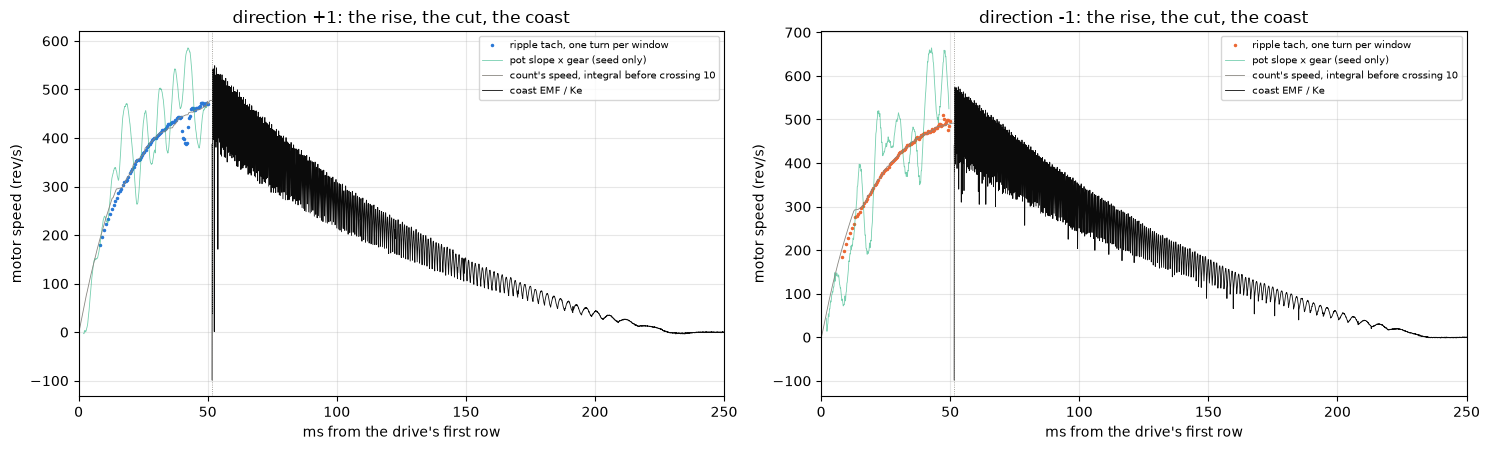

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
DIR_COLOR = {1: BLUE, -1: ORANGE}
for a, d in zip(ax, (1, -1)):
    s = STORE[f"runup-open-1 k0 {d:+d}"]
    t = np.arange(len(s["i"])) * 1e3 / FS
    rv = REV[(REV["set"] == "runup-open-1") & (REV["k"] == 0)
             & (REV["dir"] == d)]
    a.plot(rv["t"] * 1e3, rv["rev_s"], ".", ms=3, color=DIR_COLOR[d],
           label="ripple tach, one turn per window")
    a.plot(t, s["w_pot"] / (2 * np.pi), lw=0.6, color=GREEN, alpha=0.6,
           label="pot slope x gear (seed only)")
    a.plot(t, s["speed"] / (2 * np.pi), lw=0.6, color=MUTED,
           label="count's speed, integral before crossing 10")
    ce = s["coast_emf"]
    tc_ms = (len(s["i"]) + np.arange(len(ce))) * 1e3 / FS
    a.plot(tc_ms[:4000], ce[:4000] / (KE * 2 * np.pi), lw=0.6, color=INK,
           label="coast EMF / Ke")
    a.axvline(t[-1], **figures.EDGE_STYLE)
    a.set_xlim(0, 250)
    a.legend(fontsize=7)
    figures.label(a, x="ms from the drive's first row",
                  y="motor speed (rev/s)",
                  title=f"direction {d:+d}: the rise, the cut, the coast")
figures.finish(fig)

Every run-up's counted speed and current, by set and direction. The thing to see is how closely the twelve run-ups of a direction lie on one another, and that direction -1 runs a little faster.

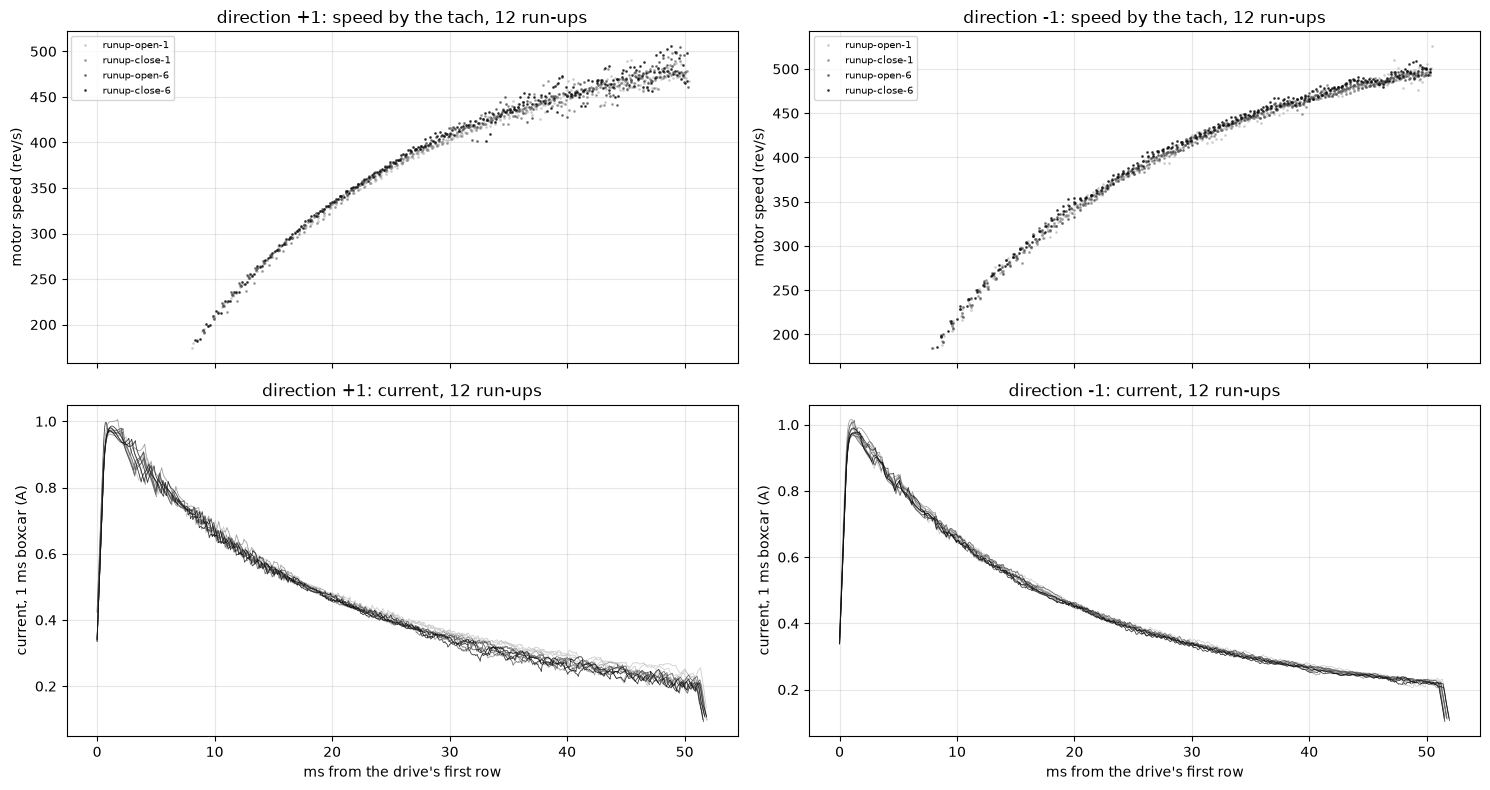

In [35]:
SET_SHADE = dict(zip(SETS, figures.shades("Greys", 4)))
fig, ax = plt.subplots(2, 2, figsize=(15, 8), sharex="col")
for d, col in ((1, 0), (-1, 1)):
    for name in SETS:
        h = REV[(REV["dir"] == d) & (REV["set"] == name) & REV["ok"]]
        for k, g in h.groupby("k"):
            ax[0, col].plot(g["t"] * 1e3, g["rev_s"], ".", ms=2,
                            color=SET_SHADE[name], alpha=0.7,
                            label=name if k == 0 else None)
        for k in range(3):
            s = STORE[f"{name} k{k} {d:+d}"]
            t = np.arange(len(s["i"])) * 1e3 / FS
            ax[1, col].plot(t, coast.local_mean(s["i"], 21), lw=0.6,
                            color=SET_SHADE[name], alpha=0.8,
                            label=name if k == 0 else None)
    ax[0, col].legend(fontsize=7)
    figures.label(ax[0, col], y="motor speed (rev/s)",
                  title=f"direction {d:+d}: speed by the tach, 12 run-ups")
    figures.label(ax[1, col], x="ms from the drive's first row",
                  y="current, 1 ms boxcar (A)",
                  title=f"direction {d:+d}: current, 12 run-ups")
figures.finish(fig)

The current reaches about 0.98 A within a millisecond, as fast as the winding's inductance lets it, and falls to about 0.22 A at the cut as the rotor's EMF grows. The first commutations show as sharp drops 1.6 to 4.0 ms in. The type's bare motor settled at about 0.11 A, so at the cut the current is still falling.

### The two tach implementations, and the cut against the coast

oscnb's own cycle count, `ripple.count_cycles`, on the drive's last 10 ms of current, seeded by the count's last speed, against the order count's crossings over the same 10 ms. Then the count's last 5 ms against the coast's $E_0$ over $K_e$, with $E_0$ from four windows of the coast and a quadratic over 1 to 13 ms.

In [36]:
E0_WINDOWS = (("1-6 ms", (20, 120)), ("1-3 ms", (20, 60)),
              ("2-8 ms", (40, 160)), ("3-13 ms", (60, 260)))


def tach_row(tag, s):
    # oscnb's count and the order count over the last 10 ms, and E0 by
    # window, as rev/s
    i = s["i"]
    n = len(i)
    last = i[n - 200:]                  # the drive's last 10 ms
    f_seed = ripple.line_freq(last, 0.8 * s["speed"][-1] / TWO_PI * N_R,
                              1.2 * s["speed"][-1] / TWO_PI * N_R, fs=FS)
    f, n_cycles = ripple.count_cycles(last, f_seed, fs=FS)
    tc = s["tc"]
    inwin = tc[tc >= (n - 200) / FS]
    order = ((len(inwin) - 1) / (inwin[-1] - inwin[0]) / N_R
             if len(inwin) > 2 else np.nan)
    e = s["coast_emf"]
    t = np.arange(len(e)) / FS
    e0 = {}
    for name, (a, b) in E0_WINDOWS:
        e0[name] = np.polyfit(t[a:b], e[a:b], 1)[1]
    p2 = np.polyfit(t[20:260], e[20:260], 2)   # a quadratic, 1 to 13 ms
    return {"tag": tag, "dir": s["dir"], "oscnb_count_rev_s": f / N_R,
            "cycles": n_cycles, "order_count_rev_s": order,
            "count_end_rev_s": s["speed"][-1] / TWO_PI,
            **{f"e0_{k}_rev_s": v / KE / TWO_PI for k, v in e0.items()},
            "e0_quad_rev_s": p2[2] / KE / TWO_PI,
            "emf_1ms_rev_s": e[20:40].mean() / KE / TWO_PI,
            "emf_5ms_rev_s": e[100:120].mean() / KE / TWO_PI}


TC = pd.DataFrame([tach_row(tag, s) for tag, s in STORE.items()])

In [37]:
RUNS["count_over_e0"] = RUNS["w_end_count_rev_s"] / RUNS["w_cut_emf_rev_s"]
for d in (1, -1):
    h = TC[TC["dir"] == d]
    r1 = h["oscnb_count_rev_s"] / h["order_count_rev_s"]
    by_win = ", ".join(
        f"{k} {(h['count_end_rev_s'] / h[f'e0_{k}_rev_s']).mean():.4f}"
        for k, _ in E0_WINDOWS)
    quad = (h["count_end_rev_s"] / h["e0_quad_rev_s"]).mean()
    last = h["count_end_rev_s"] / h["e0_1-6 ms_rev_s"]   # the last row
    emf1 = (h["emf_1ms_rev_s"] / h["count_end_rev_s"]).mean()
    cut = RUNS[RUNS["dir"] == d]["count_over_e0"]
    print(f"direction {d:+d}: oscnb count over order count {r1.mean():.4f} "
          f"sd {r1.std():.4f}; count's last 5 ms over E0/Ke "
          f"{cut.mean():.4f} sd {cut.std():.4f}")
    print(f"  count's last row over E0 by window: {by_win}, quadratic "
          f"{quad:.4f}; 1-6 ms sd {last.std():.4f}; the EMF at 1 ms over "
          f"the count's last row {emf1:.4f}")
pooled_cut = RUNS["count_over_e0"]
lad = LADDER["e0_over_ke_tach"]       # the ladder's steady spins
print(f"pooled: {pooled_cut.mean():.4f} sd {pooled_cut.std():.4f}; the "
      f"ladder's E0 over Ke x tach {lad['value']:.4f} sd "
      f"{lad['hi'] - lad['value']:.4f}")

direction +1: oscnb count over order count 1.0056 sd 0.0112; count's last 5 ms over E0/Ke 0.9916 sd 0.0210
  count's last row over E0 by window: 1-6 ms 0.9919, 1-3 ms 0.9899, 2-8 ms 0.9954, 3-13 ms 0.9933, quadratic 0.9937; 1-6 ms sd 0.0243; the EMF at 1 ms over the count's last row 0.9951
direction -1: oscnb count over order count 0.9986 sd 0.0113; count's last 5 ms over E0/Ke 0.9773 sd 0.0093
  count's last row over E0 by window: 1-6 ms 0.9756, 1-3 ms 0.9859, 2-8 ms 0.9757, 3-13 ms 0.9767, quadratic 0.9753; 1-6 ms sd 0.0105; the EMF at 1 ms over the count's last row 1.0138
pooled: 0.9845 sd 0.0175; the ladder's E0 over Ke x tach 1.0037 sd 0.0276


The count's last 5 ms over the coast's $E_0 / K_e$ is 0.992 sd 0.021 in direction +1 and 0.977 sd 0.009 in direction -1, and the count's last row over $E_0$ 0.992 and 0.976. So the -1 count ends 2.3 to 2.4 % under the EMF at the cut, and $E_0$'s window does not move it, 0.975 to 0.986 over the four windows and the quadratic. The EMF 1 ms past the cut already reads 1.4 % over the -1 count. oscnb's cycle count agrees with the order count to 1.006 sd 0.011 in +1 and 0.999 sd 0.011 in -1, so the two tach implementations agree and the gap sits between the tach and the coast's EMF, in direction -1 only. The ladder found the coast's $E_0$ over $K_e$ times the tach at 1.004 sd 0.028 on steady spins to 457 rev/s.

Two readings are alive. The -1 tach undercounting at 450 to 500 rev/s is the leading one, moderate, since stage 2 recorded the ripple tach 3 to 12 % low in direction -1 above 450 rev/s on mg90-c. The other, the -1 coast EMF reading 2 % high in its first 13 ms, has no mechanism, since the ladder's $K_e$ by direction agrees to 0.08 %. A 2.3 % tach error in -1 would move the -1 $J$ by about 2 %, see the inertia, and is the 84 mV between the -1 $X$ at the cut by the count and free of $K_e$, see the 100 % check. A -1 spin held at 100 % to a settled speed with the pot and the coast EMF both read over whole turns, or a camera clip of a 100 % run-up, separates them.

## The coast's drag

The coast's first 20 ms of EMF with its open rows, and the coast's deceleration against its speed, all 24 coasts. The thing to see is a clean ripple on the EMF with few open rows, and one deceleration curve for both directions that steepens with speed.

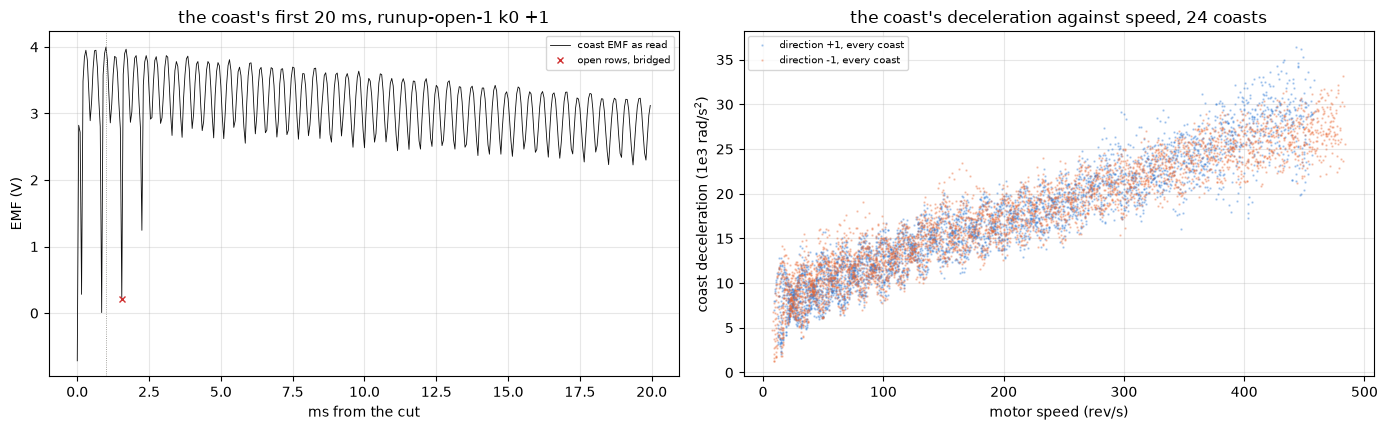

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
s = STORE["runup-open-1 k0 +1"]
ce, bad = s["coast_emf_raw"], s["coast_bad"]
ms = np.arange(len(ce)) * 1e3 / FS      # ms from the cut
ax[0].plot(ms[:400], ce[:400], lw=0.6, color=INK, label="coast EMF as read")
ax[0].plot(ms[:400][bad[:400]], ce[:400][bad[:400]], "x", ms=4, color=RED,
           label="open rows, bridged")
ax[0].axvline(COAST_SETTLE_ROWS / FS * 1e3, **figures.EDGE_STYLE)
ax[0].legend(fontsize=7)
figures.label(ax[0], x="ms from the cut", y="EMF (V)",
              title="the coast's first 20 ms, runup-open-1 k0 +1")
for d in (1, -1):
    h = COAST[COAST["dir"] == d]
    ax[1].plot(h["rev_s"], -h["alpha"] / 1e3, ".", ms=1.5, alpha=0.3,
               color=DIR_COLOR[d], label=f"direction {d:+d}, every coast")
ax[1].legend(fontsize=7)
figures.label(ax[1], x="motor speed (rev/s)",
              y="coast deceleration (1e3 rad/s$^2$)",
              title="the coast's deceleration against speed, 24 coasts")
figures.finish(fig)

The coast's deceleration in 25 rev/s bins per direction, the median and its sd, with the type's bare drag current on 5 V at the bin's speed beside it. The bins become a current through $J$ below.

In [39]:
drag_rows = []
for d in (1, -1):
    h = COAST[COAST["dir"] == d]
    for lo in np.arange(0, 500, SPEED_BIN_REV_S):
        g = h[(h["rev_s"] >= lo) & (h["rev_s"] < lo + SPEED_BIN_REV_S)]
        if len(g) < 20:                 # too few fits for a bin
            continue
        a = g["alpha"].to_numpy()
        drag_rows.append({"dir": d, "rev_s": lo + SPEED_BIN_REV_S / 2,
                          "alpha_c": np.median(a), "alpha_c_sd": a.std(),
                          "n": len(g),
                          "type_bare_drag_ma": TYPE_DRAG(
                              TWO_PI * (lo + 12.5)) * 1e3})
DRAG = pd.DataFrame(drag_rows)
pick = DRAG[DRAG["rev_s"].isin([12.5, 112.5, 237.5, 362.5, 462.5])]
show(pick.pivot(index="rev_s", columns="dir", values="alpha_c"), n=None)
ratio = DRAG.pivot(index="rev_s", columns="dir", values="alpha_c")
ratio = (ratio[-1] / ratio[1]).dropna()  # -1 over +1 per bin
print("-1 over +1 by bin: " + ", ".join(
    f"{w:.0f} {v:.3f}" for w, v in ratio.items()))

dir,-1,1
rev_s,,
12.500,-7731.994,-7783.172
112.500,-13073.387,-13159.163
237.500,-18568.263,-18373.252
362.500,-24458.194,-24251.684
462.500,-27080.818,-28833.203


-1 over +1 by bin: 12 0.993, 38 1.052, 62 1.072, 88 1.016, 112 0.993, 138 1.007, 162 1.013, 188 1.001, 212 1.015, 238 1.011, 262 0.993, 288 0.978, 312 1.004, 338 0.980, 362 1.009, 388 0.959, 412 0.918, 438 0.936, 462 0.939


The coast decelerates at about 7.7e3 to 7.8e3 rad/s$^2$ at 12 rev/s and 2.7e4 to 2.9e4 at 462 rev/s. The two directions agree within 3 % from 90 to 360 rev/s. Under 75 rev/s direction -1 reads up to 7 % over +1, and from 390 to 460 rev/s 4 to 8 % under it.

## The inertia

### Per run-up

$J$ per run-up under the method, the line with its intercept as a current, through the origin and the ratio, with each alternative beside it, the direction's pooled coast in place of the run's own, the awake-zero current, the sag's $K_e$, the fits at 0.3 A and up, and the type's bare drag curve in place of the coast.

In [40]:
POOLED_FN = {d: coast.coast_decel_fn(COAST[COAST["dir"] == d])[0]
             for d in (1, -1)}


def j_row(s_, k, d, g):
    # J of one run-up under the method and its alternatives
    g = g[g["res_ok"] & g["win_ok"] & (g["alpha"] > 0)]
    ct = COAST[(COAST["set"] == s_) & (COAST["k"] == k)
               & (COAST["dir"] == d)]
    own_fn, w_top = coast.coast_decel_fn(ct)  # the run's own coast
    base = j_from_fits(g, KT, own_fn)
    alts = {"pool": j_from_fits(g, KT, POOLED_FN[d]),
            "awake": j_from_fits(g, KT, own_fn, i_col="i_awake"),
            "ke_sag": j_from_fits(g, KE_SAG,
                                  lambda w: own_fn(w) * KE / KE_SAG),
            # the type's bare drag in place of the coast
            "type_drag": j_from_fits(
                g, KT, lambda w: -KT * TYPE_DRAG(w) / J_TYPE["value"]),
            "i_ge_0p3": j_from_fits(g[g["i"] >= 0.3], KT, own_fn)}
    row = {"set": s_, "k": k, "dir": d, "sitting": SITTING_OF[s_],
           "coast_top_rev_s": w_top / TWO_PI, **base}
    for name, alt in alts.items():
        row[f"j_{name}"] = alt["j"] if alt else np.nan
        row[f"extra_a_{name}"] = alt["extra_a"] if alt else np.nan
    return row


J = pd.DataFrame([j_row(s_, k, d, g)
                  for (s_, k, d), g in FIT.groupby(KEYS)])
J["tag"] = [f"{s_} k{int(k)} {int(d):+d}"
            for s_, k, d in zip(J["set"], J["k"], J["dir"])]

In [41]:
view = J[["tag", "n", "j", "j_se", "extra_a", "j_origin", "j_ratio",
          "rms_alpha", "i_min", "i_max", "w_min_rev_s", "w_max_rev_s"]]
view = view.assign(**{c: view[c] * 1e9 for c in ("j", "j_se", "j_origin",
                                                 "j_ratio")},
                   extra_a=view["extra_a"] * 1e3)
print("J in 1e-9 kg m^2, the line's intercept in mA, rms in rad/s^2")
show(view, n=None)
print(f"{int(J['n'].sum())} fits, {J['i_min'].min():.2f} to "
      f"{J['i_max'].max():.2f} A, {J['w_min_rev_s'].min():.0f} to "
      f"{J['w_max_rev_s'].max():.0f} rev/s")

J in 1e-9 kg m^2, the line's intercept in mA, rms in rad/s^2


,tag,n,j,j_se,extra_a,j_origin,j_ratio,rms_alpha,i_min,i_max,w_min_rev_s,w_max_rev_s
0,runup-close-1 k0 -1,71,6.947,0.125,-41.043,6.321,6.239,2804.923,0.240,0.637,230.087,485.846
1,runup-close-1 k0 +1,70,7.892,0.321,-94.047,6.435,6.444,5512.508,0.239,0.631,229.396,468.139
2,runup-close-1 k1 -1,55,6.535,0.173,-16.001,6.244,6.290,2292.396,0.238,0.468,331.830,486.190
3,runup-close-1 k1 +1,44,7.252,0.179,-55.043,6.506,6.514,2398.325,0.328,0.651,218.398,420.754
4,runup-close-1 k2 -1,65,7.134,0.180,-52.550,6.280,6.247,3113.986,0.237,0.571,272.735,484.765
5,runup-close-1 k2 +1,42,7.334,0.347,-55.746,6.479,6.566,3686.425,0.280,0.560,277.482,445.992
6,runup-close-6 k0 -1,71,6.608,0.133,-19.041,6.314,6.271,3226.819,0.238,0.629,239.431,488.894
7,runup-close-6 k0 +1,49,7.452,0.261,-67.812,6.493,6.565,3745.418,0.296,0.640,225.888,438.696
8,runup-close-6 k1 -1,72,6.646,0.137,-23.029,6.297,6.241,3493.724,0.234,0.647,226.829,489.696
9,runup-close-6 k1 +1,46,7.250,0.202,-59.498,6.424,6.463,4116.909,0.229,0.654,219.706,475.043


1404 fits, 0.23 to 0.68 A, 209 to 491 rev/s


### The three forms

Each form over the 24 run-ups pooled and per direction, on $a_d - a_c(\omega)$ against the current, with its rms. The pooled fits also give the concave form with an intercept as well, to see whether the intercept survives a free $k$.

In [42]:
def line_and_origin(i, y):
    # the line with an intercept and the line through the origin on i
    out = {}
    p, cov = np.polyfit(i, y, 1, cov=True)
    out["j_line"] = KT / p[0]
    out["j_line_se"] = KT * np.sqrt(cov[0, 0]) / p[0] ** 2
    out["extra_a_line"] = -p[1] / p[0]  # A, the drag the coast misses
    out["rms_line"] = np.std(y - np.polyval(p, i))
    s0 = (i * y).sum() / (i * i).sum()  # the slope through the origin
    out["j_origin"] = KT / s0
    out["rms_origin"] = np.std(y - s0 * i)
    return out, s0


def concave(i_, a, k):
    # a torque per amp that falls with the current, no intercept
    return a * i_ * (1 - k * i_)


def concave_b(i_, a, k, b):
    # the same with an intercept
    return a * i_ * (1 - k * i_) + b

In [43]:
def fit_group(i, y, name):
    # the three forms, and the concave one with an intercept, on one group
    out, s0 = line_and_origin(i, y)
    out = {"group": name, "n": len(i), **out}
    p2, cov2 = curve_fit(concave, i, y, p0=[s0, 0.1])
    out["j_concave"] = KT / p2[0]
    out["j_concave_se"] = KT * np.sqrt(cov2[0, 0]) / p2[0] ** 2
    out["k_mech_per_a"] = p2[1]
    out["k_mech_se"] = np.sqrt(cov2[1, 1])
    out["rms_concave"] = np.std(y - concave(i, *p2))
    p3, cov3 = curve_fit(concave_b, i, y, p0=[s0, 0.1, 0.0])
    out["j_concave_b"] = KT / p3[0]
    out["k_mech_b_per_a"] = p3[1]
    out["k_mech_b_se"] = np.sqrt(cov3[1, 1])
    out["extra_a_concave_b"] = -p3[2] / p3[0]
    out["extra_a_concave_b_se"] = np.sqrt(cov3[2, 2]) / p3[0]
    out["rms_concave_b"] = np.std(y - concave_b(i, *p3))
    return out

In [44]:
xs, ys, ds, tags = [], [], [], []
for (s_, k, d), g in FIT.groupby(KEYS):
    g = g[g["res_ok"] & g["win_ok"] & (g["alpha"] > 0)]
    ct = COAST[(COAST["set"] == s_) & (COAST["k"] == k)
               & (COAST["dir"] == d)]
    fn, _ = coast.coast_decel_fn(ct)          # the run's own coast
    xs.append(g["i"].to_numpy())
    ys.append(g["alpha"].to_numpy() - fn(g["w"].to_numpy()))
    ds.append(np.full(len(g), d))
    tags.append(f"{s_} k{k} {d:+d}")
I_ALL, Y_ALL, D_ALL = map(np.concatenate, (xs, ys, ds))

In [45]:
TM = pd.DataFrame([fit_group(I_ALL, Y_ALL, "both")]
                  + [fit_group(I_ALL[D_ALL == d], Y_ALL[D_ALL == d],
                               f"direction {d:+d}") for d in (1, -1)])
per, failed = [], []
for i, y, d, tag in zip(xs, ys, ds, tags):   # the forms per run-up
    try:
        r = fit_group(i, y, "run")
    except RuntimeError:                # a fit that does not converge
        failed.append(tag)
        continue
    per.append({"dir": int(d[0]), "k_mech": r["k_mech_per_a"],
                "j_concave": r["j_concave"], "j_line": r["j_line"],
                "j_origin": r["j_origin"]})
TM_RUN = pd.DataFrame(per)

In [46]:
show_tm = TM.copy()
for c in [c for c in show_tm if c.startswith("j_")]:
    show_tm[c] = show_tm[c] * 1e9
for c in [c for c in show_tm if c.startswith("extra_a")]:
    show_tm[c] = show_tm[c] * 1e3
show(show_tm.set_index("group").T, n=None)
print(f"per run-up, {len(TM_RUN)} fitted: concave J "
      f"{TM_RUN['j_concave'].mean() * 1e9:.3f} sd "
      f"{TM_RUN['j_concave'].std() * 1e9:.3f}, k {TM_RUN['k_mech'].mean():.3f}"
      f" sd {TM_RUN['k_mech'].std():.3f} per A; not converged: {failed}")

group,both,direction +1,direction -1
n,1404.000,594.000,810.000
j_line,7.137,7.381,6.821
j_line_se,0.040,0.070,0.044
extra_a_line,-47.522,-57.199,-33.222
rms_line,3814.414,4011.967,3336.042
j_origin,6.427,6.561,6.307
rms_origin,4311.818,4559.195,3656.646
j_concave,5.789,5.858,5.829
j_concave_se,0.030,0.053,0.035
k_mech_per_a,0.216,0.222,0.172


per run-up, 23 fitted: concave J 5.860 sd 0.335, k 0.193 sd 0.099 per A; not converged: ['runup-open-1 k2 +1']


The three forms on one figure, every kept fit's $a_d - a_c(\omega)$ against its current with the three pooled fits, and their residuals in 0.05 A bins. The thing to see is that the three curves agree over the 0.23 to 0.68 A the fits cover and part outside it. Through the origin the residuals tilt by about 3e3 rad/s$^2$ either way across the current, under the 4.3e3 rms of the fits about it, and the line and the concave form leave a smaller tilt.

In [47]:
BOTH = TM[TM["group"] == "both"].iloc[0]   # the pooled fits
FORMS = {   # each form's prediction of a_d - a_c from the current, A
    "line": lambda i: KT / BOTH.j_line * (i - BOTH.extra_a_line),
    "origin": lambda i: KT / BOTH.j_origin * i,
    "concave": lambda i: (KT / BOTH.j_concave * i
                          * (1 - BOTH.k_mech_per_a * i))}
FORM_LABEL = {
    "line": f"line: J {BOTH.j_line * 1e9:.2f}, intercept "
            f"{BOTH.extra_a_line * 1e3:+.0f} mA, rms {BOTH.rms_line:.0f}",
    "origin": f"through the origin: J {BOTH.j_origin * 1e9:.2f}, rms "
              f"{BOTH.rms_origin:.0f}",
    "concave": f"i (1 - k i): J {BOTH.j_concave * 1e9:.2f}, k "
               f"{BOTH.k_mech_per_a:.2f}/A, rms {BOTH.rms_concave:.0f}"}
FORM_STYLE = {"line": ("-", INK), "origin": (":", INK),
              "concave": ("--", RED)}

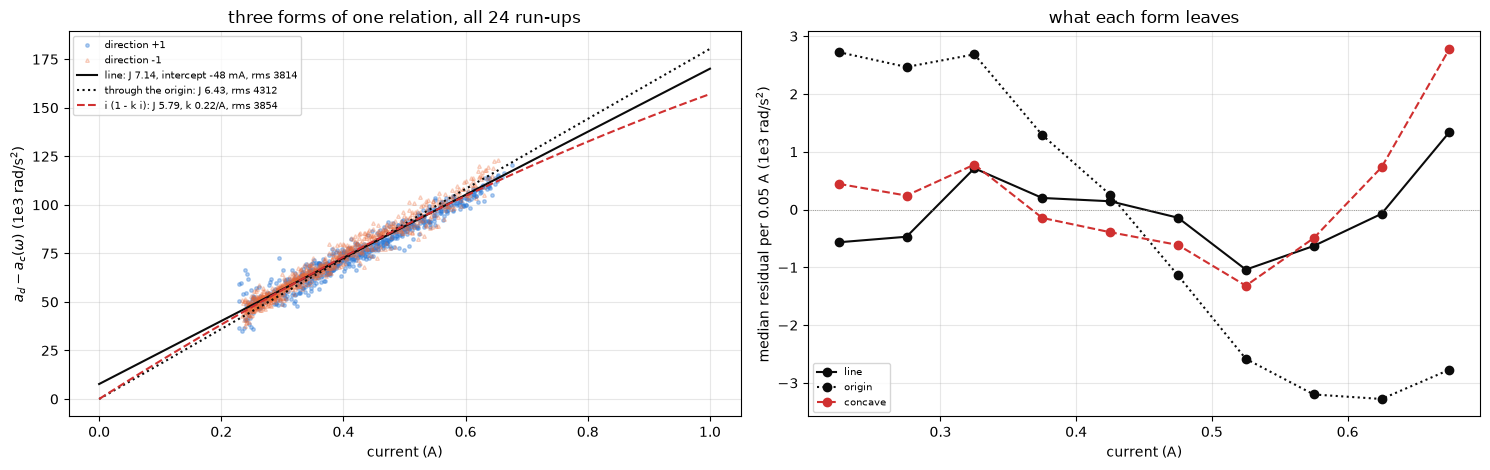

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for d in (1, -1):
    m = D_ALL == d
    ax[0].plot(I_ALL[m], Y_ALL[m] / 1e3, ms=2.5, alpha=0.35,
               **figures.direction_style(d, DIR_COLOR[d]),
               label=f"direction {d:+d}")
amps = np.linspace(0, 1.0, 50)
edges = np.arange(0.2, 0.71, 0.05)      # A, the residuals' bins
mid = (edges[1:] + edges[:-1]) / 2
which = np.digitize(I_ALL, edges)
for name, form in FORMS.items():
    ls, color = FORM_STYLE[name]
    ax[0].plot(amps, form(amps) / 1e3, ls, color=color,
               label=FORM_LABEL[name])
    res = Y_ALL - form(I_ALL)           # rad/s^2, each fit's residual
    med = [np.median(res[which == b]) if (which == b).sum() > 5
           else np.nan for b in range(1, len(edges))]
    ax[1].plot(mid, np.array(med) / 1e3, ls, marker="o", color=color,
               label=name)
ax[0].legend(fontsize=7)
figures.label(ax[0], x="current (A)", y="$a_d - a_c(\\omega)$ (1e3 rad/s$^2$)",
              title="three forms of one relation, all 24 run-ups")
ax[1].axhline(0, **figures.EDGE_STYLE)
ax[1].legend(fontsize=7)
figures.label(ax[1], x="current (A)",
              y="median residual per 0.05 A (1e3 rad/s$^2$)",
              title="what each form leaves")
figures.finish(fig)

$J$ pooled over the 24 run-ups by form and route, the mean, its sd and its standard error.

In [49]:
def pooled(x):
    # mean, sd, standard error and count of one number over run-ups
    x = np.asarray(x, float)
    return x.mean(), x.std(ddof=1), x.std(ddof=1) / np.sqrt(len(x)), len(x)


routes = [("line, own coast (stage 2's method)", *pooled(J["j"]))]
for d in (1, -1):
    routes.append((f"line, direction {d:+d}", *pooled(J[J["dir"] == d]["j"])))
for s_ in SETS:
    routes.append((f"line, {s_}", *pooled(J[J["set"] == s_]["j"])))
for name, col in (("through the origin", "j_origin"),
                  ("ratio, median", "j_ratio"),
                  ("line, the direction's pooled coast", "j_pool"),
                  ("line, awake-zero current", "j_awake"),
                  ("line, Ke from the sag", "j_ke_sag"),
                  ("line, fits at i >= 0.3 A", "j_i_ge_0p3"),
                  ("line, the type's bare drag in place of the coast",
                   "j_type_drag")):
    routes.append((name, *pooled(J[col].dropna())))
for d in (1, -1):
    for name, col in (("through the origin", "j_origin"),
                      ("ratio, median", "j_ratio")):
        routes.append((f"{name}, direction {d:+d}",
                       *pooled(J[J["dir"] == d][col])))
for s_ in SETS:
    routes.append((f"through the origin, {s_}",
                   *pooled(J[J["set"] == s_]["j_origin"])))
ROUTES = pd.DataFrame(routes, columns=["route", "j", "sd", "se", "n"])
show(ROUTES.assign(j=ROUTES.j * 1e9, sd=ROUTES.sd * 1e9,
                   se=ROUTES.se * 1e9), n=None)

,route,j,sd,se,n
0,"line, own coast (stage 2's method)",7.075,0.425,0.087,24
1,"line, direction +1",7.306,0.432,0.125,12
2,"line, direction -1",6.844,0.272,0.078,12
3,"line, runup-open-1",7.100,0.360,0.147,6
4,"line, runup-close-1",7.182,0.449,0.183,6
5,"line, runup-open-6",7.135,0.544,0.222,6
6,"line, runup-close-6",6.882,0.373,0.152,6
7,through the origin,6.433,0.159,0.033,24
8,"ratio, median",6.399,0.194,0.040,24
9,"line, the direction's pooled coast",7.019,0.330,0.067,24


In [50]:
J_LINE, J_LINE_SD, J_LINE_SE, _ = pooled(J["j"])
J_ORIGIN, J_ORIGIN_SD, J_ORIGIN_SE, _ = pooled(J["j_origin"])
EXTRA_A, EXTRA_A_SD, EXTRA_A_SE, _ = pooled(J["extra_a"])


def split(a, b):
    # a over b less one, % of a, and the difference in sigma by the se
    ma, _, sea, _ = pooled(a)
    mb, _, seb, _ = pooled(b)
    return (ma - mb) / ma * 100, (ma - mb) / np.hypot(sea, seb)


for col, name in (("j_origin", "origin"), ("j", "line")):
    pairs = {"+1 over -1": (J[J.dir == 1][col], J[J.dir == -1][col]),
             "sitting 6 over 1": (J[J.sitting == 6][col],
                                  J[J.sitting == 1][col]),
             "close over open, sitting 1": (
                 J[J.set == "runup-close-1"][col],
                 J[J.set == "runup-open-1"][col]),
             "close over open, sitting 6": (
                 J[J.set == "runup-close-6"][col],
                 J[J.set == "runup-open-6"][col])}
    print(f"{name}: " + "; ".join(
        f"{k} {split(*v)[0]:+.2f} % ({split(*v)[1]:.1f} sigma)"
        for k, v in pairs.items()))
print(f"origin {J_ORIGIN * 1e9:.3f} sd {J_ORIGIN_SD * 1e9:.3f} se "
      f"{J_ORIGIN_SE * 1e9:.3f}; line {J_LINE * 1e9:.3f} se "
      f"{J_LINE_SE * 1e9:.3f}, intercept {EXTRA_A * 1e3:+.1f} mA sd "
      f"{EXTRA_A_SD * 1e3:.1f}; pooled line intercept "
      f"{BOTH.extra_a_line * 1e3:+.1f} mA")
print(f"the type's drag curve in place of the coast: intercept "
      f"{J['extra_a_type_drag'].mean() * 1e3:+.0f} mA")
print(f"against the type's {J_TYPE['value'] * 1e9:.3f}: origin "
      f"{J_ORIGIN / J_TYPE['value']:.3f}, line {J_LINE / J_TYPE['value']:.3f}")

origin: +1 over -1 +3.91 % (6.8 sigma); sitting 6 over 1 -0.59 % (-0.6 sigma); close over open, sitting 1 -2.35 % (-1.5 sigma); close over open, sitting 6 -0.86 % (-0.7 sigma)
line: +1 over -1 +6.32 % (3.1 sigma); sitting 6 over 1 -1.90 % (-0.8 sigma); close over open, sitting 1 +1.15 % (0.4 sigma); close over open, sitting 6 -3.67 % (-0.9 sigma)
origin 6.433 sd 0.159 se 0.033; line 7.075 se 0.087, intercept -42.8 mA sd 27.6; pooled line intercept -47.5 mA
the type's drag curve in place of the coast: intercept +62 mA
against the type's 6.255: origin 1.028, line 1.131


The three forms fit the same points to about the same residual, 4312 rad/s$^2$ through the origin, 3814 for the line and 3854 for the concave form, where the line leaves 2000 to 5500 rad/s$^2$ within each run-up. With both an intercept and $k$ free the pooled fit returns $k$ = -0.00 +/- 0.05 per A, and the two directions disagree in its sign, -0.26 in +1 and +0.08 in -1. Along a 100 % run-up the current falls as the speed rises, so a constant drag the coast misses and a torque per amp that falls with the current are the same thing to this data. The span of the three forms is the method's ambiguity, not the data's noise.

Through the origin, the definition the brief set, $J$ = 6.43 +/- 0.03 (se) x $10^{-9}$ kg m$^2$, sd 2.5 % over the 24 run-ups, 1.028 of the type's bare rotor, 6.255 (5.83 to 6.83). By set it reads 6.53, 6.38, 6.44 and 6.39 for open-1, close-1, open-6 and close-6. Sitting 6 sits 0.6 % under sitting 1, 0.6 sigma. Close against open reads -2.4 % in sitting 1, 1.5 sigma, and -0.9 % in sitting 6, 0.7 sigma. None reaches 2 sigma, so $J$ did not drift between or within the sittings, high confidence.

Direction +1 reads 6.56 sd 0.12 and direction -1 6.31 sd 0.05, 3.9 % apart, 6.8 sigma by the per-run spread. The split exists in this read, high confidence. Its cause is open. The +1 count is the noisier one, 37 of the 41 flagged windows, and the +1 brushes drop out, see the dropouts. A tach error of 2 % in one direction moves that direction's $J$ by about 2 %, and the -1 count ends under the coast's EMF, see the count, so the tach is one candidate.

The line gives 7.08 +/- 0.09 (se), 10 % over the origin's and 13 % over the type's, with an intercept of -43 mA sd 28 per run-up, -47.5 mA pooled. That intercept says the drive would carry about 45 mA less drag than the coast at the same speed. It is a property of the fit form, and the data does not separate it from the curvature of the concave form, so it is not a measured drag. Stage 2's bare motor read +22 mA the other way against a partial-duty drag curve. The counted parts of the train reflected to the motor, the pinion on the shaft and the first gear at a fifth to an eighth of motor speed, add a few percent at most to the rotor's inertia, not 13 %, so the line's 7.08 most likely folds the drag ambiguity into its slope, likely. The concave form's 5.86 would put the servo's rotor under the bare type's, which the same prior rejects.

The carried value is $J$ = 6.43 x $10^{-9}$ kg m$^2$, moderate confidence, with 5.86 to 7.08, the concave and the line forms, as its bounds. The alternatives move the line by less than that span. The direction's pooled coast in place of the run's own gives 7.02, the awake-zero current the same 7.08, the sag's $K_e$ 7.11, the fits at 0.3 A and up 7.16, and the type's bare drag curve in place of the coast 6.26 with a +62 mA intercept, the train's drag. Current-scale's absolute class, 2 %, moves every $J$ one for one and is outside every bracket here, as in stage 2.

The acceleration of the drive and the coast's deceleration against speed, and $J$ per run-up by set and direction, the line's with its standard error and the origin's as dashes. The thing to see is the -1 run-ups sitting together under the +1 ones by the origin, and the line scattering over both.

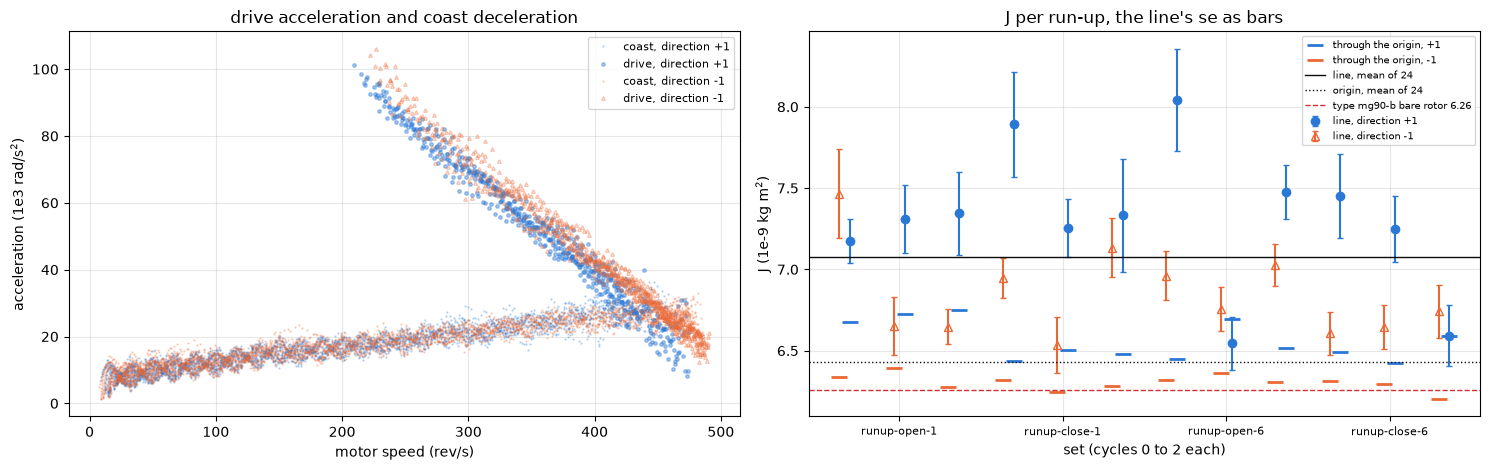

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for d in (1, -1):
    g = FIT[(FIT["dir"] == d) & FIT["res_ok"] & FIT["win_ok"]
            & (FIT["alpha"] > 0)]
    h = COAST[COAST["dir"] == d]
    ax[0].plot(h["rev_s"], -h["alpha"] / 1e3, ".", ms=1.5, alpha=0.25,
               color=DIR_COLOR[d], label=f"coast, direction {d:+d}")
    ax[0].plot(g["rev_s"], g["alpha"] / 1e3, ms=2.5, alpha=0.4,
               **figures.direction_style(d, DIR_COLOR[d]),
               label=f"drive, direction {d:+d}")
    h = J[J["dir"] == d]
    x = [SETS.index(s_) * 3 + k_ + (0.1 if d == 1 else -0.1)
         for s_, k_ in zip(h["set"], h["k"])]
    ax[1].errorbar(x, h["j"] * 1e9, yerr=h["j_se"] * 1e9,
                   fmt=figures.DIRECTION_MARKER[d], color=DIR_COLOR[d],
                   mfc=DIR_COLOR[d] if d == 1 else "none", ms=6, capsize=2,
                   label=f"line, direction {d:+d}")
    ax[1].plot(x, h["j_origin"] * 1e9, "_", ms=12, mew=2,
               color=DIR_COLOR[d], label=f"through the origin, {d:+d}")
ax[1].axhline(J_LINE * 1e9, color=INK, lw=1, label="line, mean of 24")
ax[1].axhline(J_ORIGIN * 1e9, color=INK, lw=1, ls=":",
              label="origin, mean of 24")
ax[1].axhline(J_TYPE["value"] * 1e9, color=RED, lw=1, ls="--",
              label=f"type mg90-b bare rotor {J_TYPE['value'] * 1e9:.2f}")
ax[1].set_xticks([1 + 3 * i for i in range(4)], SETS, fontsize=8)
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=7)
figures.label(ax[0], x="motor speed (rev/s)",
              y="acceleration (1e3 rad/s$^2$)",
              title="drive acceleration and coast deceleration")
figures.label(ax[1], x="set (cycles 0 to 2 each)", y="J (1e-9 kg m$^2$)",
              title="J per run-up, the line's se as bars")
figures.finish(fig)

### The coast's drag as a current

The coast's deceleration bins through the origin's $J$ and $K_t$, as a torque and as the current that torque would draw, against the type's bare drag on 5 V at the same speed.

In [52]:
DRAG["drag_torque_unm"] = -DRAG["alpha_c"] * J_ORIGIN * 1e6
DRAG["drag_current_ma"] = -DRAG["alpha_c"] * J_ORIGIN / KT * 1e3
pick = DRAG[DRAG["rev_s"].isin([12.5, 112.5, 237.5, 362.5, 462.5])]
table = pick.pivot(index="rev_s", columns="dir", values="drag_current_ma")
table["type_bare_ma"] = pick.groupby("rev_s")["type_bare_drag_ma"].first()
table["train_adds_ma"] = table[1] - table["type_bare_ma"]
show(table, n=None)
plus = DRAG[DRAG["dir"] == 1].set_index("rev_s")["drag_current_ma"]
print(f"direction +1 rises {(plus[462.5] - plus[112.5]) / 350:.3f} mA per "
      f"rev/s from 112 to 462 rev/s; -1 over +1 at the same bins "
      f"{(table[-1] / table[1]).min():.3f} to "
      f"{(table[-1] / table[1]).max():.3f}")

dir,-1,1,type_bare_ma,train_adds_ma
rev_s,,,,
12.500,42.913,43.197,43.527,-0.330
112.500,72.559,73.035,55.682,17.352
237.500,103.056,101.973,71.758,30.216
362.500,135.745,134.599,80.855,53.744
462.500,150.301,160.027,86.096,73.931


direction +1 rises 0.249 mA per rev/s from 112 to 462 rev/s; -1 over +1 at the same bins 0.939 to 1.011


Through $J$ = 6.43 the coast's drag is 43 mA at 12 rev/s, 73 at 112, 102 at 237, 135 at 362 and 160 at 462 rev/s in direction +1, against the type's bare drag on 5 V of 44, 56, 72, 81 and 86 mA at the same speeds. So the train in Super Lube adds -0.3 mA at 12 rev/s, within the bin's spread, and 70 to 75 mA at 400 to 460 rev/s, a drag that grows about linearly with speed, 0.25 mA per rev/s above 100 rev/s. High confidence on the shape, 24 coasts with an sd of 7 to 10 % per bin. The scale is tied to $J$. The friction notebook reads these bins for its coast route.

## The rise

A first-order curve through each run-up's kept turn windows, the asymptote, the time constant, the rise time to 63 % of the asymptote and to 63 % of the speed at the cut, and the speed at the cut.

In [53]:
rise_rows = []
for (s_, k, d), g in REV.groupby(KEYS):
    rise_rows.append({"set": s_, "k": k, "dir": d,
                      "sitting": SITTING_OF[s_], **rise_fit(g)})
RISE = pd.DataFrame(rise_rows)
RISE["tag"] = [f"{s_} k{int(k)} {int(d):+d}"
               for s_, k, d in zip(RISE["set"], RISE["k"], RISE["dir"])]
RISE = RISE.merge(RUNS[KEYS + ["w_cut_emf_rev_s", "w_end_count_rev_s"]],
                  on=KEYS)
show(RISE[["tag", "w_inf_rev_s", "tau_ms", "t0_ms", "t63_ms",
           "t63_of_cut_ms", "w_cut_rev_s", "w_cut_emf_rev_s", "cut_over_inf",
           "rise_rms_rev_s"]], n=None)
for col in ("t63_ms", "t63_of_cut_ms", "w_inf_rev_s", "w_cut_rev_s",
            "tau_ms", "cut_over_inf"):
    mean, sd, se, _ = pooled(RISE[col])
    by = ", ".join(f"{d:+d} {RISE[RISE.dir == d][col].mean():.2f}"
                   for d in (1, -1))
    print(f"{col}: {mean:.2f} sd {sd:.2f} se {se:.2f}; by direction {by}")
print(f"cut over asymptote {RISE['cut_over_inf'].min():.3f} to "
      f"{RISE['cut_over_inf'].max():.3f}")
print(f"the fit's rms {RISE['rise_rms_rev_s'].min():.1f} to "
      f"{RISE['rise_rms_rev_s'].max():.1f} rev/s; the type's rise "
      f"{RISE_TYPE_MS['+1']['value']:.1f} / {RISE_TYPE_MS['-1']['value']:.1f}"
      f" ms")

,tag,w_inf_rev_s,tau_ms,t0_ms,t63_ms,t63_of_cut_ms,w_cut_rev_s,w_cut_emf_rev_s,cut_over_inf,rise_rms_rev_s
0,runup-close-1 k0 -1,547.311,21.344,-0.576,20.768,17.432,490.447,499.034,0.896,2.169
1,runup-close-1 k0 +1,521.633,20.288,-0.388,19.900,17.207,474.448,490.281,0.910,6.207
2,runup-close-1 k1 -1,544.748,20.854,-0.590,20.263,17.000,492.067,513.129,0.903,3.133
3,runup-close-1 k1 +1,523.455,19.900,-0.112,19.787,16.869,478.884,469.626,0.915,5.577
4,runup-close-1 k2 -1,543.697,21.008,-0.714,20.294,16.814,488.673,504.112,0.899,2.886
5,runup-close-1 k2 +1,515.082,18.705,1.129,19.834,17.072,468.590,474.950,0.910,4.466
6,runup-close-6 k0 -1,544.134,20.575,-0.856,19.719,16.528,492.260,502.539,0.905,2.789
7,runup-close-6 k0 +1,515.143,18.400,0.610,19.010,16.898,476.627,488.559,0.925,7.625
8,runup-close-6 k1 -1,546.630,20.632,-0.514,20.117,17.240,493.988,505.533,0.904,2.726
9,runup-close-6 k1 +1,531.429,20.719,-0.241,20.478,17.236,480.854,493.956,0.905,7.578


t63_ms: 19.99 sd 0.48 se 0.10; by direction +1 19.78, -1 20.21
t63_of_cut_ms: 16.91 sd 0.29 se 0.06; by direction +1 16.93, -1 16.89
w_inf_rev_s: 533.72 sd 12.96 se 2.64; by direction +1 521.91, -1 545.53
w_cut_rev_s: 483.38 sd 9.07 se 1.85; by direction +1 475.21, -1 491.55
tau_ms: 20.43 sd 0.80 se 0.16; by direction +1 19.91, -1 20.96
cut_over_inf: 0.91 sd 0.01 se 0.00; by direction +1 0.91, -1 0.90
cut over asymptote 0.896 to 0.925
the fit's rms 2.2 to 7.6 rev/s; the type's rise 19.0 / 19.5 ms


The rise time to 63 % of the asymptote is 20.0 sd 0.5 ms, 19.8 in direction +1 and 20.2 in -1, with $\tau$ 20.4 sd 0.8 ms. The asymptote $\omega_\infty$ is 534 sd 13 rev/s, 522 in +1 and 546 in -1, the fit's extrapolation past the 52 ms cut. The speed at the cut is 483 sd 9 rev/s, 475 and 492, 0.90 to 0.93 of $\omega_\infty$ in every run-up, and the fit's rms is 2 to 8 rev/s. Measured against the speed at the cut, model free, the 63 % point is 16.9 sd 0.3 ms.

The type's bare rotor rose to 63 % of its settled speed in 19.0 and 19.5 ms. This servo's 20.0 +/- 0.1 ms (se) is 3 to 5 % longer, 2 sigma by the per-run sd, a candidate difference. The comparison is not like for like, since the type's 63 % was of a measured settled speed and this one is of an extrapolated asymptote. The asymptote extrapolates 10 % past the cut, so 522 and 546 rev/s stand as the servo's no-load speed at 5 V only as a candidate. The type's bare motor settled at 538 and 557 rev/s.

## The speed-torque curve through the gears

With $J$ = 6.43 the shaft torque $J\,a_d$ is the torque left after the train's own no-load drag, at the motor. At the horn it is 308 times that before the gear's loss. The gear's efficiency is not measured here. The load notebook's holds measure it. Each kept fit gives a point, its torque $J\,a_d$, speed, current, terminal volts, output power $J\,a_d\,\omega$ and efficiency at the terminals $J\,a_d\,\omega / (u\,i)$. Beside the torque from the acceleration, the torque from the current is $K_t\,i$ less the coast's drag at that speed, from the direction's pooled coast.

In [54]:
PTS = FIT[FIT["res_ok"] & FIT["win_ok"] & (FIT["alpha"] > 0)].copy()
PTS["torque"] = J_ORIGIN * PTS["alpha"]    # N m at the motor, J alpha
PTS["drag_torque"] = -J_ORIGIN * np.array(
    [POOLED_FN[d](w) for d, w in zip(PTS["dir"], PTS["w"])])
PTS["torque_i"] = KT * PTS["i"] - PTS["drag_torque"]
PTS["p_out"] = PTS["torque"] * PTS["w"]   # W at the motor
PTS["p_in"] = PTS["u"] * PTS["i"]         # W at the terminals
PTS["eff"] = PTS["p_out"] / PTS["p_in"]
PTS["tbin"] = ((PTS["torque"] * 1e3 // TORQUE_BIN_MNM) * TORQUE_BIN_MNM
               + TORQUE_BIN_MNM / 2)     # the bin's center, mN m


def bins(p, least):
    # the medians per torque bin with at least `least` fits
    b = p.groupby("tbin").agg(n=("w", "size"), rev_s=("rev_s", "median"),
                              i=("i", "median"), u=("u", "median"),
                              p_out=("p_out", "median"),
                              eff=("eff", "median"),
                              p_out_sd=("p_out", "std"))
    return b[b["n"] >= least]


BIN = bins(PTS, BIN_MIN)
show(BIN, n=None)
print(f"covered {PTS['rev_s'].min():.0f} to {PTS['rev_s'].max():.0f} rev/s,"
      f" {PTS['torque'].min() * 1e3:.3f} to {PTS['torque'].max() * 1e3:.3f} "
      f"mN m, {len(PTS)} fits")

,n,rev_s,i,u,p_out,eff,p_out_sd
tbin,,,,,,,
0.075,26,473.359,0.242,4.788,0.269,0.230,0.039
0.125,158,472.978,0.256,4.782,0.394,0.319,0.037
0.175,214,451.813,0.289,4.764,0.485,0.359,0.038
0.225,179,421.993,0.332,4.742,0.604,0.387,0.031
0.275,181,396.702,0.371,4.722,0.682,0.390,0.026
0.325,153,367.430,0.415,4.698,0.754,0.389,0.032
0.375,116,341.623,0.456,4.678,0.801,0.378,0.036
0.425,130,317.164,0.495,4.658,0.841,0.365,0.031
0.475,85,290.905,0.539,4.636,0.856,0.343,0.038


covered 209 to 491 rev/s, 0.053 to 0.682 mN m, 1404 fits


Per direction, the torque regressed on the speed, the clean axis, to its zero-speed and zero-torque ends, and the peaks of power and efficiency in bins of at least five fits. The stall end read directly in the first millisecond is $K_t$ times the current at 0.8 to 1.5 ms less the coast's drag under 60 rev/s.

In [55]:
KEY = {}
for d in (1, -1):
    h = PTS[PTS["dir"] == d]
    b = bins(h, DIR_BIN_MIN)
    p = np.polyfit(h["w"], h["torque"], 1)   # torque on speed
    w0 = -p[1] / p[0]                   # rad/s at zero torque
    KEY[d] = {"stall_line_mnm": p[1] * 1e3, "w0_line_rev_s": w0 / TWO_PI,
              "p_max_w": b["p_out"].max(),
              "p_max_torque_mnm": b["p_out"].idxmax(),
              "p_max_rev_s": b.loc[b["p_out"].idxmax(), "rev_s"],
              "p_line_w": p[1] * w0 / 4,
              "eff_max": b["eff"].max(),
              "eff_max_torque_mnm": b["eff"].idxmax(),
              "eff_max_rev_s": b.loc[b["eff"].idxmax(), "rev_s"],
              "w_cut_rev_s": RISE[RISE.dir == d]["w_cut_rev_s"].mean(),
              "w_inf_rev_s": RISE[RISE.dir == d]["w_inf_rev_s"].mean()}
I_STALL = RUNS["i_stall_a"]
DRAG0 = (DRAG[DRAG["rev_s"] < 60].groupby("dir")["drag_current_ma"].mean()
         * 1e-3)                        # A, the coast's drag near the stop
T_STALL_DIRECT = KT * (I_STALL.mean() - DRAG0.mean())
show(pd.DataFrame(KEY), n=None)
print(f"stall end: i {I_STALL.mean():.3f} A sd {I_STALL.std():.3f} at "
      f"{RUNS['u_stall_v'].mean():.3f} V sd {RUNS['u_stall_v'].std():.3f};"
      f" coast drag under 60 rev/s " + ", ".join(
          f"{d:+d} {v * 1e3:.1f} mA" for d, v in DRAG0.items())
      + f"; torque {T_STALL_DIRECT * 1e3:.3f} mN m")

,1,-1
stall_line_mnm,1.042,1.049
w0_line_rev_s,524.758,545.065
p_max_w,0.864,0.931
p_max_torque_mnm,0.625,0.625
p_max_rev_s,222.343,237.883
p_line_w,0.859,0.898
eff_max,0.373,0.400
eff_max_torque_mnm,0.325,0.375
eff_max_rev_s,360.698,352.117
w_cut_rev_s,475.210,491.549


stall end: i 0.981 A sd 0.011 at 4.407 V sd 0.013; coast drag under 60 rev/s -1 47.1 mA, +1 46.0 mA; torque 1.083 mN m


In [56]:
per_run_peak = []
for (s_, k, d), g in PTS.groupby(KEYS):     # each run-up's own bins
    b = bins(g, 3)
    best = b["p_out"].idxmax()
    per_run_peak.append({"set": s_, "k": k, "dir": d,
                         "p_max_w": b["p_out"].max(),
                         "p_max_torque_mnm": best,
                         "p_max_rev_s": b.loc[best, "rev_s"],
                         "p_max_i": b.loc[best, "i"]})
PEAK = pd.DataFrame(per_run_peak)
mean, sd, se, _ = pooled(PEAK["p_max_w"])
P_LINE_J = BIN["p_out"].max() * J_LINE / J_ORIGIN   # under the line's J
print(f"peak power: pooled bins {BIN['p_out'].max():.3f} W at "
      f"{BIN['p_out'].idxmax():.3f} mN m and "
      f"{BIN.loc[BIN['p_out'].idxmax(), 'rev_s']:.0f} rev/s; per run "
      f"{mean:.3f} sd {sd:.3f} se {se:.3f}; by direction " + ", ".join(
          f"{d:+d} {KEY[d]['p_max_w']:.3f}" for d in (1, -1)))
print(f"under the line's J, x {J_LINE / J_ORIGIN:.3f}: {P_LINE_J:.3f} W; "
      f"the type's {PEAK_POWER_TYPE['value']:.3f} W")
print(f"peak efficiency {BIN['eff'].max():.3f} at {BIN['eff'].idxmax():.3f}"
      f" mN m; by direction " + ", ".join(
          f"{d:+d} {KEY[d]['eff_max']:.3f}" for d in (1, -1)))

peak power: pooled bins 0.906 W at 0.625 mN m and 230 rev/s; per run 0.885 sd 0.041 se 0.008; by direction +1 0.864, -1 0.931
under the line's J, x 1.100: 0.996 W; the type's 0.976 W
peak efficiency 0.390 at 0.275 mN m; by direction +1 0.373, -1 0.400


The curve, speed, current, output power at the motor and efficiency at the terminals against the shaft torque $J\,a_d$, every kept fit by direction with the median per 0.05 mN m, the torque from the current on the speed panel, the stall end read directly, and the type's bare curve dashed. The thing to see is the speed falling along a line with the torque, the power peaking near 0.6 mN m, and the servo's curve sitting under the bare motor's.

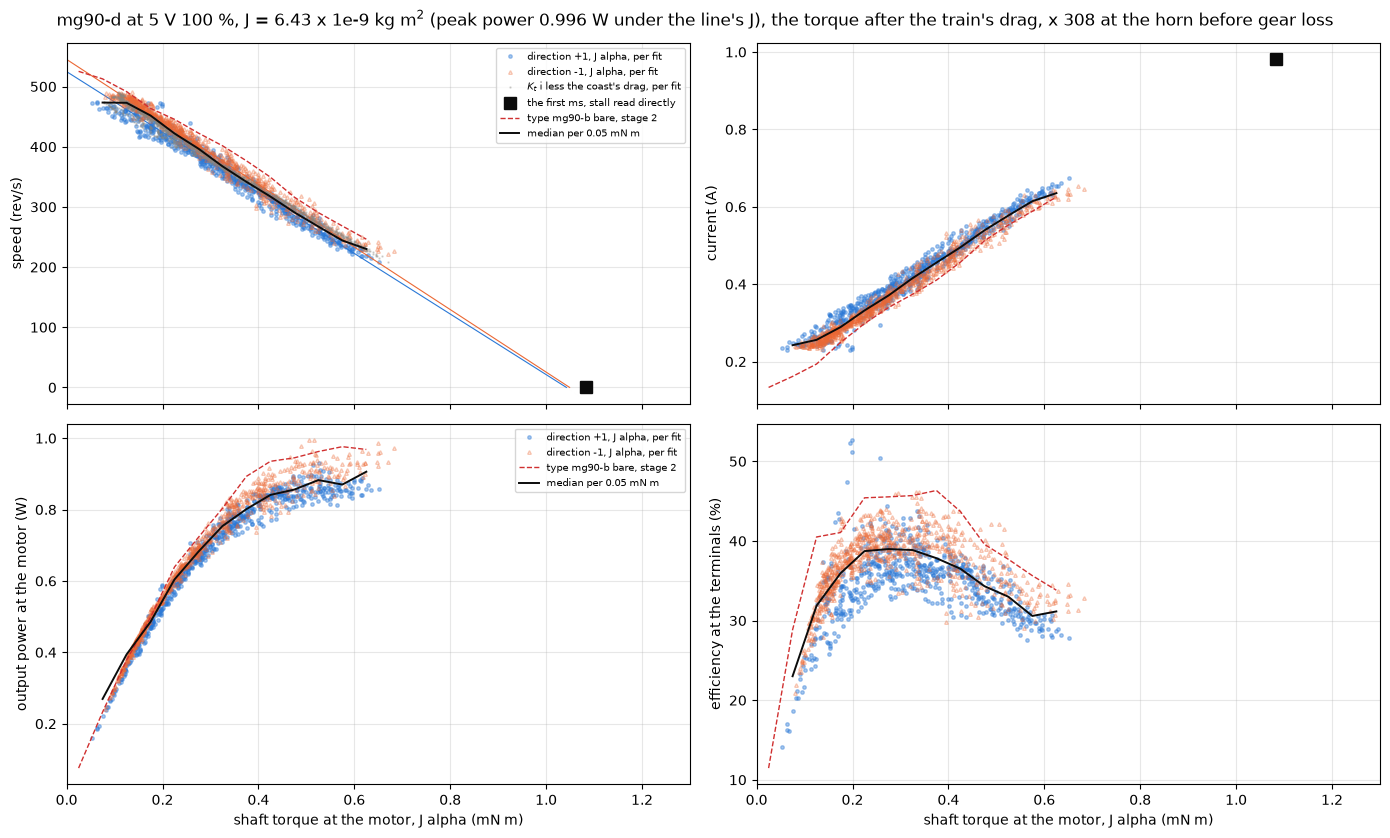

In [57]:
PANELS = (("rev_s", 1, "speed (rev/s)"), ("i", 1, "current (A)"),
          ("p_out", 1, "output power at the motor (W)"),
          ("eff", 100, "efficiency at the terminals (%)"))
TYPE_CURVE = pd.DataFrame(ST_TYPE["curve"])
TYPE_COLS = ("speed_rev_s", "current_a", "power_w", "efficiency")
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
for d in (1, -1):
    h = PTS[PTS["dir"] == d]
    style = figures.direction_style(d, DIR_COLOR[d])
    for a, (col, scale, _) in zip(ax.flat, PANELS):
        a.plot(h["torque"] * 1e3, h[col] * scale, ms=2.5, alpha=0.4,
               **style, label=f"direction {d:+d}, J alpha, per fit")
    torque = np.linspace(0, KEY[d]["stall_line_mnm"] * 1e-3, 20)
    p = np.polyfit(h["w"], h["torque"], 1)   # torque on speed, inverted
    ax[0, 0].plot(torque * 1e3, ((torque - p[1]) / p[0]) / TWO_PI, "-",
                  color=DIR_COLOR[d], lw=0.8)
ax[0, 0].plot(PTS["torque_i"] * 1e3, PTS["rev_s"], ".", ms=1.5,
              color=MUTED, alpha=0.3,
              label="$K_t$ i less the coast's drag, per fit")
ax[0, 0].plot(T_STALL_DIRECT * 1e3, 0, "s", ms=9, color=INK,
              label="the first ms, stall read directly")
ax[0, 1].plot(T_STALL_DIRECT * 1e3, I_STALL.mean(), "s", ms=9, color=INK)
for a, (col, scale, y_label), tcol in zip(ax.flat, PANELS, TYPE_COLS):
    a.plot(TYPE_CURVE["torque_mnm"], TYPE_CURVE[tcol] * scale, "--",
           color=RED, lw=1, label="type mg90-b bare, stage 2")
    a.plot(BIN.index, BIN[col] * scale, "-", color=INK, lw=1.4,
           label="median per 0.05 mN m")
    a.set_xlim(0, 1.3)
    figures.label(a, y=y_label)
for a in ax[1]:
    figures.label(a, x="shaft torque at the motor, J alpha (mN m)")
ax[0, 0].legend(fontsize=7)
ax[1, 0].legend(fontsize=7)
fig.suptitle(f"mg90-d at 5 V 100 %, J = {J_ORIGIN * 1e9:.2f} x 1e-9 kg m$^2$"
             f" (peak power {P_LINE_J:.3f} W under the line's J), the "
             f"torque after the train's drag, x {GEAR:.0f} at the horn "
             f"before gear loss")
figures.finish(fig)

The speed falls along a line with the torque. The torque regressed on the speed per direction reaches zero speed at 1.042 mN m in direction +1 and 1.049 in -1, and zero torque at 525 and 545 rev/s, the latter an extrapolation past the cut like the rise's asymptote. The stall end read directly, $K_t$ times 0.981 A less the coast's 46 to 47 mA under 60 rev/s, is 1.083 mN m. The current rises from 0.24 A at the light end to 0.64 A at 0.63 mN m and 0.98 A at stall.

The output power peaks at 0.906 W in the pooled bins, at 0.625 mN m and 230 rev/s, 0.864 and 0.931 W by direction, and the per-run peaks are 0.885 sd 0.041 W. The efficiency at the terminals peaks at 0.39 at 0.275 mN m, 0.37 and 0.40 by direction. The torque axis carries $J$'s bracket. Under the line's $J$ every torque and power is 1.10 times these, and the peak power is 0.996 W.

Against the type's bare motor, 0.976 W at 0.575 mN m, a stall torque of 1.13 mN m by its lines and 1.19 in its first millisecond, and an efficiency peak of 0.46, the servo at the motor delivers 0.07 W, 7 %, less at the peak and 0.08 to 0.11 mN m less at stall with $J$ = 6.43. That is the size of the train's drag, 70 to 75 mA at speed and 46 to 47 mA near the stop, 0.05 to 0.09 mN m through $K_t$, consistent, moderate confidence, with $J$'s bracket as the bound. The light end of the curve, under 0.1 mN m and over 480 rev/s, is not reached in 52 ms. The torque from the acceleration and the torque from the current less the coast's drag agree by the construction of the origin fit.

## The dropouts

The dropout rows per run-up in the 52 ms drive, pooled by set and direction with Poisson bars, over the whole drive and over its last 20 ms, and by sitting.

In [58]:
drop = RUNS[KEYS + ["sitting", "dropouts", "dropouts_per_s",
                    "dropouts_last20ms", "dropouts_last20ms_per_s",
                    "dropouts_10_30ms", "drive_s"]].copy()
DROP = drop.groupby(["set", "dir"]).agg(
    n=("dropouts", "sum"), s=("drive_s", "sum"),
    n_last=("dropouts_last20ms", "sum"))
DROP["rate_per_s"] = DROP["n"] / DROP["s"]
DROP["rate_se"] = np.sqrt(DROP["n"].clip(lower=1)) / DROP["s"]
DROP["rate_last20_per_s"] = DROP["n_last"] / 0.06     # three 20 ms tails
DROP["rate_last20_se"] = np.sqrt(DROP["n_last"].clip(lower=1)) / 0.06
DROP = DROP.reset_index()
DROP["sitting"] = DROP["set"].map(SITTING_OF)
show(DROP, n=None)
BY_SIT = drop.groupby(["sitting", "dir"]).agg(
    n=("dropouts", "sum"), s=("drive_s", "sum")).reset_index()
BY_SIT["rate"] = BY_SIT["n"] / BY_SIT["s"]
BY_SIT["se"] = np.sqrt(BY_SIT["n"].clip(lower=1)) / BY_SIT["s"]
show(BY_SIT, n=None)
n1 = drop[(drop.sitting == 1) & (drop.dir == 1)]["dropouts"].sum()
n6 = drop[(drop.sitting == 6) & (drop.dir == 1)]["dropouts"].sum()
SIT_SIGMA = (n6 - n1) / np.sqrt(n1 + n6)   # Poisson, equal drive times
print(f"direction +1: sitting 1 {n1} rows, sitting 6 {n6} rows, "
      f"{SIT_SIGMA:.1f} sigma")

,set,dir,n,s,n_last,rate_per_s,rate_se,rate_last20_per_s,rate_last20_se,sitting
0,runup-close-1,-1,1,0.155,1,6.439,6.439,16.667,16.667,1
1,runup-close-1,1,6,0.155,6,38.635,15.773,100.000,40.825,1
2,runup-close-6,-1,0,0.156,0,0.000,6.429,0.000,16.667,6
3,runup-close-6,1,12,0.155,12,77.270,22.306,200.000,57.735,6
4,runup-open-1,-1,1,0.155,1,6.441,6.441,16.667,16.667,1
5,runup-open-1,1,2,0.155,2,12.891,9.115,33.333,23.570,1
6,runup-open-6,-1,0,0.155,0,0.000,6.456,0.000,16.667,6
7,runup-open-6,1,10,0.155,8,64.454,20.382,133.333,47.140,6


,sitting,dir,n,s,rate,se
0,1,-1,2,0.311,6.440,4.554
1,1,1,8,0.310,25.769,9.111
2,6,-1,0,0.310,0.000,3.221
3,6,1,22,0.310,70.865,15.108


direction +1: sitting 1 8 rows, sitting 6 22 rows, 2.6 sigma


By speed, the rows per second of drive in 50 rev/s bands of the count's speed, per direction and sitting, the bands with over 400 rows. The whole-drive rate depends on how much of the 52 ms sits at high speed, so the per-band rates are the comparable numbers.

In [59]:
sp_rows = []
for tag, s in STORE.items():
    w = s["speed"] / TWO_PI             # rev/s, the count's speed per row
    for lo in np.arange(0, 550, 50.0):
        band = (w >= lo) & (w < lo + 50)
        sp_rows.append({"tag": tag, "dir": s["dir"],
                        "sitting": SITTING_OF[s["set"]], "set": s["set"],
                        "rev_s": lo + 25, "rows": int(band.sum()),
                        "dropouts": int(s["open"][band].sum())})
SP = pd.DataFrame(sp_rows)
SPB = SP.groupby(["dir", "sitting", "rev_s"]).agg(
    rows=("rows", "sum"), dropouts=("dropouts", "sum")).reset_index()
SPB["rate_per_s"] = SPB["dropouts"] / (SPB["rows"] / FS)
SPB["rate_se"] = np.sqrt(SPB["dropouts"].clip(lower=1)) / (SPB["rows"] / FS)
SPB = SPB[SPB["rows"] > 400]
show(SPB, n=None)
# the type's dropouts in its first 40 ms, quoted from the text of stage 2
# speed-torque (mg90-b at 5 V 100 %), not a result key; rows per second
TYPE_EARLY_DROPOUTS = {1: 125, -1: 8}

,dir,sitting,rev_s,rows,dropouts,rate_per_s,rate_se
5,-1,1,275.000,492,0,0.000,40.650
6,-1,1,325.000,746,0,0.000,26.810
7,-1,1,375.000,753,0,0.000,26.560
8,-1,1,425.000,1055,0,0.000,18.957
9,-1,1,475.000,1866,2,21.436,15.158
16,-1,6,275.000,446,0,0.000,44.843
17,-1,6,325.000,755,0,0.000,26.490
18,-1,6,375.000,735,0,0.000,27.211
19,-1,6,425.000,1039,0,0.000,19.249
20,-1,6,475.000,1947,0,0.000,10.272


The rates by set and direction, whole drive and last 20 ms, and the rate against speed by direction and sitting with the type's early-window rates. The thing to see is that direction -1 almost never drops out, and that direction +1 drops out only above 350 rev/s and more in sitting 6.

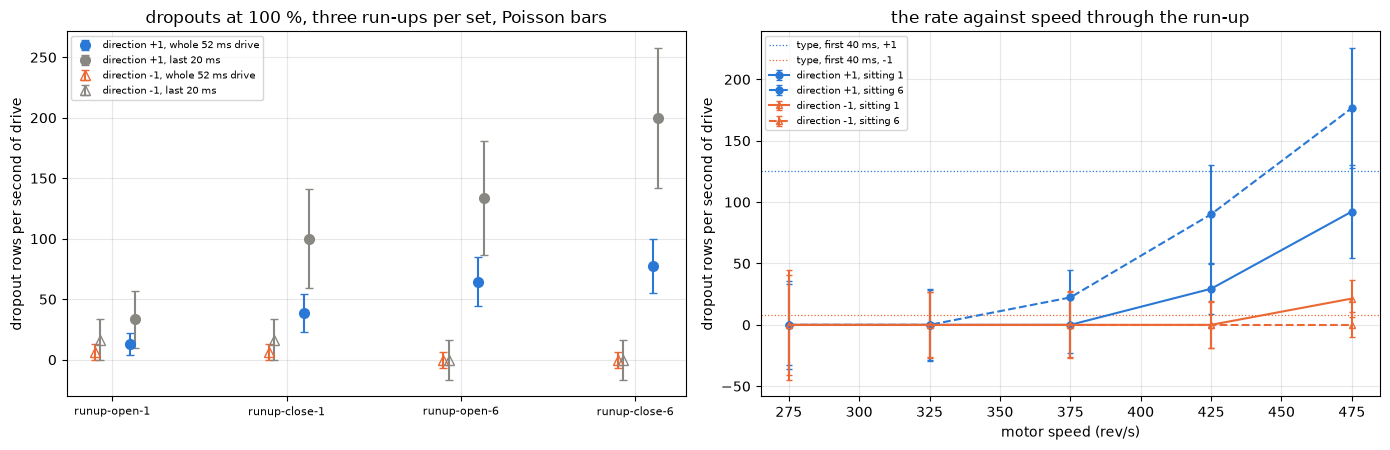

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for d in (1, -1):
    h = DROP[DROP.dir == d]
    xpos = np.array([SETS.index(s_) + (0.1 if d == 1 else -0.1)
                     for s_ in h["set"]])
    ax[0].errorbar(xpos, h["rate_per_s"], yerr=h["rate_se"],
                   fmt=figures.DIRECTION_MARKER[d], color=DIR_COLOR[d],
                   mfc=DIR_COLOR[d] if d == 1 else "none", ms=7, capsize=3,
                   label=f"direction {d:+d}, whole 52 ms drive")
    ax[0].errorbar(xpos + 0.03, h["rate_last20_per_s"],
                   yerr=h["rate_last20_se"], fmt=figures.DIRECTION_MARKER[d],
                   color=MUTED, mfc=MUTED if d == 1 else "none", ms=7,
                   capsize=3, label=f"direction {d:+d}, last 20 ms")
    for sit, ls in ((1, "-"), (6, "--")):
        g = SPB[(SPB.dir == d) & (SPB.sitting == sit)]
        ax[1].errorbar(g["rev_s"], g["rate_per_s"], yerr=g["rate_se"],
                       ls=ls, marker=figures.DIRECTION_MARKER[d],
                       color=DIR_COLOR[d],
                       mfc=DIR_COLOR[d] if d == 1 else "none", ms=5,
                       capsize=2, label=f"direction {d:+d}, sitting {sit}")
    ax[1].axhline(TYPE_EARLY_DROPOUTS[d], color=DIR_COLOR[d], ls=":",
                  lw=0.9, label=f"type, first 40 ms, {d:+d}")
ax[0].set_xticks(range(4), SETS, fontsize=8)
ax[0].legend(fontsize=7)
figures.label(ax[0], y="dropout rows per second of drive",
              title="dropouts at 100 %, three run-ups per set, Poisson bars")
ax[1].legend(fontsize=7)
figures.label(ax[1], x="motor speed (rev/s)",
              y="dropout rows per second of drive",
              title="the rate against speed through the run-up")
figures.finish(fig)

Direction +1 dropped out 8 rows in sitting 1, 26 +/- 9 per second of drive, and 22 rows in sitting 6, 71 +/- 15 per second. The difference is 2.6 sigma by Poisson, so it is likely that direction +1's brushes dropped out more two days later, after the locked sittings. Within a sitting, close over open is under 2 sigma both times, 2 against 6 rows and 10 against 12, the same sign both days, a candidate. Direction -1 dropped out 2 rows in 24 run-ups, nothing to read.

No dropout falls under 350 rev/s in either direction or sitting. In direction +1 the rate is 29 per second at 400 to 450 rev/s in sitting 1 and 90 in sitting 6, and 92 and 177 per second at 450 to 500 rev/s, so the rate is a function of speed. The type, mg90-b at 5 V 100 %, dropped out 125 rows per second in direction +1 and 8 in direction -1 over its first 40 ms, from the stage 2 speed-torque notebook's text. This servo's +1 rates over the whole drive, 13 to 77 per second by set, and 29 to 177 per second in its fastest bands, sit around that early-window rate, and its -1 rates, 0 to 6, at or under the type's 8. The type's settled rate is not compared, since this data holds no settled speed. As the brush state of the sitting, direction +1 was quiet in sitting 1 and louder in sitting 6, and direction -1 silent throughout. The dropout rows are left out of the window means, and at a few rows in 52 ms they move nothing else.

## The 100 % check

### The current's zero

At 100 % nothing switches, so the crest sample is the period's mean and the only construction left in the current is its zero. The coast's last 100 ms, bridge open and rotor at rest, gives the awake zero over the sweep's torque-off zero, against stage 1's in-drive offset and the ladder's awake-zero line at 5 V, and the inductance result's crest less window mean at partial duty.

In [61]:
aw = RUNS["awake_step_counts"]          # counts over the rest zero
ZERO_DIFF_MA = (aw.mean() - I_DRIVE_OFFSET) * A_PER_COUNT * 1e3
print(f"awake zero over the rest zero: {aw.mean():.2f} sd {aw.std():.2f} "
      f"counts over {len(aw)} coasts; stage 1's in-drive offset "
      f"{I_DRIVE_OFFSET:.2f}; the ladder's line at 5 V "
      f"{AWAKE_PER_V * 5 + AWAKE_ICPT:.2f}")
print(f"the two zeros differ by {ZERO_DIFF_MA:.2f} mA, "
      f"{(aw.std()) * A_PER_COUNT * 1e3:.2f} mA sd, "
      f"{ZERO_DIFF_MA * R_LOCKED:.1f} mV at R")
print("inductance's crest less window mean: " + ", ".join(
    f"{k} % {v['value']:.2f} mA" for k, v in CREST_LESS_MEAN.items())
      + f"; g_hold_bound {IND['g_hold_bound_ms']['value']:.2f} ms "
      f"({IND['g_hold_bound_ms']['lo']:.2f} to "
      f"{IND['g_hold_bound_ms']['hi']:.2f})")

awake zero over the rest zero: 5.74 sd 0.56 counts over 24 coasts; stage 1's in-drive offset 5.26; the ladder's line at 5 V 5.26
the two zeros differ by 0.42 mA, 0.49 mA sd, 1.8 mV at R
inductance's crest less window mean: 25 % 0.56 mA, 40 % 0.46 mA; g_hold_bound 0.42 ms (-0.66 to 1.50)


The coast's last 100 ms reads 5.74 sd 0.56 counts over the sweep's rest zero over the 24 coasts. Stage 1's in-drive offset at 100 % is 5.26 counts, and the ladder's awake-zero line gives 5.26 at 5 V. So the crest over the coast's zero and the crest over stage 1's offset differ by 0.42 mA, sd 0.5, 1.8 mV through $R$. The inductance result's crest less window mean at 25 and 40 % is 0.46 to 0.56 mA. The 100 % run-up's current needs no window model, and the 0.4 mA the two zeros differ by is the same size as the partial-duty term that result read, so nothing here contradicts it. Nothing here measures it either, since the check at 100 % is that the term is absent, and it is, to 0.5 mA. High confidence.

### The balance along the run-up

$X$ at every kept fit, with the bounds of $R$, the sag's $K_e$ and the awake-zero current as alternatives.

In [62]:
FIT["didt"] = np.nan
for (s_, k, d), g in FIT.groupby(KEYS):  # di/dt along each run-up's fits
    FIT.loc[g.index, "didt"] = np.gradient(g["i"].to_numpy(),
                                           g["t"].to_numpy())


def balance(i, r_ohm=R_LOCKED, ke=KE):
    # X in mV at every fit for one current, R and Ke
    return (FIT["u"] - r_ohm * FIT[i] - L_H * FIT["didt"]
            - ke * FIT["w"]) * 1e3


FIT["x_mv"] = balance("i")
FIT["x_awake_mv"] = balance("i_awake")
FIT["x_sag_mv"] = balance("i", ke=KE_SAG)
FIT["x_rlo_mv"] = balance("i", r_ohm=R_LOCKED_LO)
FIT["x_rhi_mv"] = balance("i", r_ohm=R_LOCKED_HI)
OK_FITS = FIT[FIT["res_ok"] & FIT["win_ok"]]
print(f"{len(OK_FITS)} fits; L di/dt {(L_H * OK_FITS['didt']).min() * 1e3:.1f}"
      f" to {(L_H * OK_FITS['didt']).max() * 1e3:.1f} mV")

1404 fits; L di/dt -25.9 to -1.5 mV


The means at the ladder's knots, over the fits within 12.5 rev/s of each, with the sd over the run-ups there, the current, the alternatives, by sitting, and the ladder's tables A and B and the type's at the same knots.

In [63]:
def knot(tab, d, w):
    # a table's value at one direction and knot, NaN where it has none
    v = tab[f"{d:+d}"].get(f"{w:.0f} rev/s")
    return np.nan if v is None else v["value"]


krows = []
for d in (1, -1):
    for w in KNOTS:
        g = OK_FITS[(OK_FITS["dir"] == d) & (OK_FITS["rev_s"] >= w - 12.5)
                    & (OK_FITS["rev_s"] < w + 12.5)]
        per_run = g.groupby(["set", "k"])["x_mv"].mean()
        krows.append({
            "dir": d, "rev_s": w, "n_fits": len(g), "n_runs": len(per_run),
            "x_mv": g["x_mv"].mean(), "x_sd_runs_mv": per_run.std(),
            "x_se_mv": per_run.std() / np.sqrt(max(len(per_run), 1)),
            "i_a": g["i"].mean(), "u_v": g["u"].mean(),
            "x_awake_mv": g["x_awake_mv"].mean(),
            "x_ke_sag_mv": g["x_sag_mv"].mean(),
            "x_r_lo_mv": g["x_rlo_mv"].mean(),
            "x_r_hi_mv": g["x_rhi_mv"].mean(),
            "x_sitting1_mv": g[g["set"].str.endswith("-1")]["x_mv"].mean(),
            "x_sitting6_mv": g[g["set"].str.endswith("-6")]["x_mv"].mean(),
            "ladder_a_mv": knot(TABLE_A, d, w),
            "ladder_b_mv": knot(TABLE_B, d, w),
            "type_mv": knot(VB_TYPE, d, w)})
KN = pd.DataFrame(krows)
show(KN[["dir", "rev_s", "n_runs", "x_mv", "x_sd_runs_mv", "i_a",
         "ladder_a_mv", "ladder_b_mv", "type_mv"]], n=None)

,dir,rev_s,n_runs,x_mv,x_sd_runs_mv,i_a,ladder_a_mv,ladder_b_mv,type_mv
0,1,150.000,0,NaN,NaN,NaN,82.985,43.557,0.000
1,1,200.000,1,222.481,NaN,0.675,106.762,54.570,12.487
2,1,250.000,11,264.616,16.240,0.602,130.762,68.534,13.521
3,1,300.000,12,279.653,16.569,0.520,158.767,87.572,19.474
4,1,350.000,12,287.193,18.126,0.442,181.740,108.337,25.763
5,1,400.000,10,292.727,29.637,0.363,236.533,141.553,32.314
6,1,450.000,8,347.116,41.863,0.274,405.699,277.890,38.864
7,-1,150.000,0,NaN,NaN,NaN,75.482,36.446,0.000
8,-1,200.000,0,NaN,NaN,NaN,90.433,41.271,4.408
9,-1,250.000,9,229.241,11.243,0.608,114.576,56.109,5.805


In [64]:
alt = KN[KN["n_runs"] >= 3]
print(f"sitting 6 less sitting 1 at the knots: "
      f"{(alt['x_sitting6_mv'] - alt['x_sitting1_mv']).abs().max():.1f} mV "
      f"at most")
for col, name in (("x_r_lo_mv", "R lo"), ("x_r_hi_mv", "R hi"),
                  ("x_ke_sag_mv", "Ke sag"), ("x_awake_mv", "awake zero")):
    dx = alt[col] - alt["x_mv"]
    print(f"{name}: {dx.min():+.1f} to {dx.max():+.1f} mV")
ratio_a = alt["x_mv"] / alt["ladder_a_mv"]
ratio_b = alt["x_mv"] / alt["ladder_b_mv"]
mid = alt[(alt["rev_s"] >= 250) & (alt["rev_s"] <= 400)]
print(f"250 to 400 rev/s: X {mid['x_mv'].min():.0f} to "
      f"{mid['x_mv'].max():.0f} mV at {mid['i_a'].min():.2f} to "
      f"{mid['i_a'].max():.2f} A, over table A x "
      f"{(mid['x_mv'] / mid['ladder_a_mv']).min():.1f} to "
      f"{(mid['x_mv'] / mid['ladder_a_mv']).max():.1f}, over table B x "
      f"{(mid['x_mv'] / mid['ladder_b_mv']).min():.1f} to "
      f"{(mid['x_mv'] / mid['ladder_b_mv']).max():.1f}, over the type x "
      f"{(mid['x_mv'] / mid['type_mv']).min():.0f} to "
      f"{(mid['x_mv'] / mid['type_mv']).max():.0f}")

sitting 6 less sitting 1 at the knots: 17.9 mV at most
R lo: +3.4 to +7.5 mV
R hi: -6.8 to -3.1 mV
Ke sag: -19.8 to -11.0 mV
awake zero: +1.7 to +2.1 mV
250 to 400 rev/s: X 229 to 293 mV at 0.36 to 0.61 A, over table A x 1.2 to 2.0, over table B x 2.1 to 4.6, over the type x 9 to 39


### Three points off the run-up's line

The ladder's 3.7 V 100 % rungs, the one state the two experiments share with nothing switching, under the same balance from the ladder's own steady numbers, and the run-up's fits within 10 rev/s of each rung's speed. The rung carries no $L\,di/dt$, its current being steady.

In [65]:
lad = []
for name, rg in LADDER["rungs"].items():
    if "100 %" in name:
        w = rg["speed_rev_s"]["value"]  # rev/s
        i = rg["i_crest_ma"]["value"] * 1e-3
        v = rg["v_a_v"]["value"]        # V, D x V_on with D = 1
        lad.append({"rung": name, "rev_s": w, "i_a": i, "v": v,
                    "x_mv": (v - R_LOCKED * i - KE_LADDER_MV * 1e-3 * w)
                    * 1e3})
LAD = pd.DataFrame(lad)
xi = []
for _, rung in LAD.iterrows():
    d = 1 if rung["rung"].endswith("+1") else -1
    g = OK_FITS[(OK_FITS["dir"] == d)
                & (np.abs(OK_FITS["rev_s"] - rung["rev_s"]) < 10)]
    xi.append({"dir": d, "rev_s": rung["rev_s"], "ladder_i_a": rung["i_a"],
               "ladder_x_mv": rung["x_mv"], "runup_i_a": g["i"].mean(),
               "runup_x_mv": g["x_mv"].mean(),
               "runup_x_sd_mv": g.groupby(["set", "k"])["x_mv"].mean().std(),
               "n_runs": g.groupby(["set", "k"]).ngroups})
XI = pd.DataFrame(xi)
XI["dx_over_di_ohm"] = ((XI["runup_x_mv"] - XI["ladder_x_mv"]) * 1e-3
                       / (XI["runup_i_a"] - XI["ladder_i_a"]))
# read as an EMF Ke w (1 - k i), the k per A the two loci would ask
XI["k_emf_per_a"] = XI["dx_over_di_ohm"] / (KE_LADDER_MV * 1e-3
                                            * XI["rev_s"])
show(XI, n=None)

,dir,rev_s,ladder_i_a,ladder_x_mv,runup_i_a,runup_x_mv,runup_x_sd_mv,n_runs,dx_over_di_ohm,k_emf_per_a
0,-1,386.508,0.143,133.451,0.389,264.594,9.266,12,0.533,0.189
1,1,372.656,0.160,153.638,0.406,288.812,21.745,11,0.549,0.202


At the cut, $X$ free of $K_e$ over the drive's last 5 ms, $u - R\,i - E_0$, and by the count. At the stall end, 0.8 to 1.5 ms, with the speed from the current's integral.

In [66]:
CUT = RUNS[KEYS + ["sitting", "u_end_v", "i_end_a", "i_end_awake_a", "e0_v",
                   "w_cut_emf_rev_s", "w_end_count_rev_s"]].copy()
CUT["x_cut_mv"] = (CUT["u_end_v"] - R_LOCKED * CUT["i_end_a"]
                   - CUT["e0_v"]) * 1e3
CUT["x_cut_count_mv"] = (CUT["u_end_v"] - R_LOCKED * CUT["i_end_a"]
                         - KE_LADDER_MV * 1e-3 * CUT["w_end_count_rev_s"]
                         ) * 1e3
for d in (1, -1):
    h = CUT[CUT.dir == d]
    print(f"direction {d:+d}: X at the cut {h['x_cut_mv'].mean():.0f} mV sd "
          f"{h['x_cut_mv'].std():.0f} (Ke-free), "
          f"{h['x_cut_count_mv'].mean():.0f} by the count, at "
          f"{h['w_cut_emf_rev_s'].mean():.0f} rev/s and "
          f"{h['i_end_a'].mean() * 1e3:.0f} mA")
st_rows = []
for tag, s in STORE.items():
    i, u, w = (s[k][STALL_ROWS].mean() for k in ("i", "u", "speed"))
    st_rows.append({"tag": tag, "dir": s["dir"], "set": s["set"], "i": i,
                    "u": u, "w": w, "w_rev_s": w / TWO_PI,
                    "x_mv": (u - R_LOCKED * i - KE * w) * 1e3})
ST = pd.DataFrame(st_rows)
print(f"the stall end: i {ST.i.mean():.3f} A, u {ST.u.mean():.3f} V, rotor "
      f"{ST.w_rev_s.mean():.0f} rev/s by the integral, X {ST.x_mv.mean():.0f}"
      f" mV sd {ST.x_mv.std():.0f}; the matched-speed slope "
      f"{XI['dx_over_di_ohm'].mean():.2f} ohm there would be "
      f"{XI['dx_over_di_ohm'].mean() * ST.i.mean() * 1e3:.0f} mV")

direction +1: X at the cut 370 mV sd 100 (Ke-free), 400 by the count, at 482 rev/s and 220 mA
direction -1: X at the cut 166 mV sd 35 (Ke-free), 250 by the count, at 505 rev/s and 226 mA
the stall end: i 0.981 A, u 4.407 V, rotor 28 rev/s by the integral, X 67 mV sd 59; the matched-speed slope 0.54 ohm there would be 530 mV


How flat $X$ runs along the run-up against speed alone. A speed table, $X = c_0 + c_\mathrm{dir} + c_\omega\,\omega$, with $c_0$ ("c naught") the intercept, $c_\mathrm{dir}$ ("c dir") a step for direction +1 and $c_\omega$ ("c omega") the slope on speed, over the kept fits with and without the 24 stall ends. This is the ladder's reading of $X$, a function of speed only. It is fitted for its slope and rms, and the current is kept out of it.

In [67]:
pts = OK_FITS[["dir", "w", "i", "x_mv", "set"]].copy()
pts["where"] = "run-up fit"
stall = ST[["dir", "w", "i", "set", "x_mv"]].assign(where="stall end")
BAL = pd.concat([pts, stall], ignore_index=True)
BAL["rev_s"] = BAL["w"] / TWO_PI
BAL["plus"] = (BAL["dir"] == 1).astype(float)   # the +1 step's column
BAL["wi"] = BAL["w"] * BAL["i"]
SPEED_TABLE = {}
for subset, sel in (("fits + stall", np.ones(len(BAL), bool)),
                    ("fits only", (BAL["where"] == "run-up fit").to_numpy())):
    X = np.column_stack([np.ones(sel.sum())]
                        + [BAL.loc[sel, c].to_numpy() for c in ("plus", "w")])
    y = BAL.loc[sel, "x_mv"].to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    fitted = X @ beta
    n, p = X.shape
    cov = (np.linalg.inv(X.T @ X)
           * ((y - fitted) ** 2).sum() / (n - p))
    se = np.sqrt(np.diag(cov))
    SPEED_TABLE[subset] = {"n": n, "rms_mv": np.std(y - fitted),
                           "c0_mv": beta[0], "c_plus": beta[1],
                           "c_w": beta[2], "c_w_se": se[2]}
    print(f"{subset}: c_w {beta[2]:.4f} +/- {se[2]:.4f} mV per rad/s, "
          f"{beta[2] / KE / 1e3 * 100:.2f} % of Ke; c_dir {beta[1]:+.1f} mV;"
          f" rms {np.std(y - fitted):.1f} mV over {n}")

fits + stall: c_w 0.0441 +/- 0.0016 mV per rad/s, 3.80 % of Ke; c_dir +52.5 mV; rms 30.6 mV over 1428
fits only: c_w 0.0225 +/- 0.0015 mV per rad/s, 1.94 % of Ke; c_dir +47.7 mV; rms 24.8 mV over 1404


$X$ against speed along every run-up, the knot means with their sd over run-ups, the ladder's tables A and B and the type's, the ladder's 3.7 V 100 % rungs as stars with their current, the stall ends as squares and $X$ at the cut free of $K_e$ as diamonds, then the same against the current. The thing to see is that the run-up's $X$ sits well over both ladder tables at every speed, that the ladder's own 100 % rungs sit under the run-up at the same speed, and that the stall end, at the highest current, sits lowest of all.

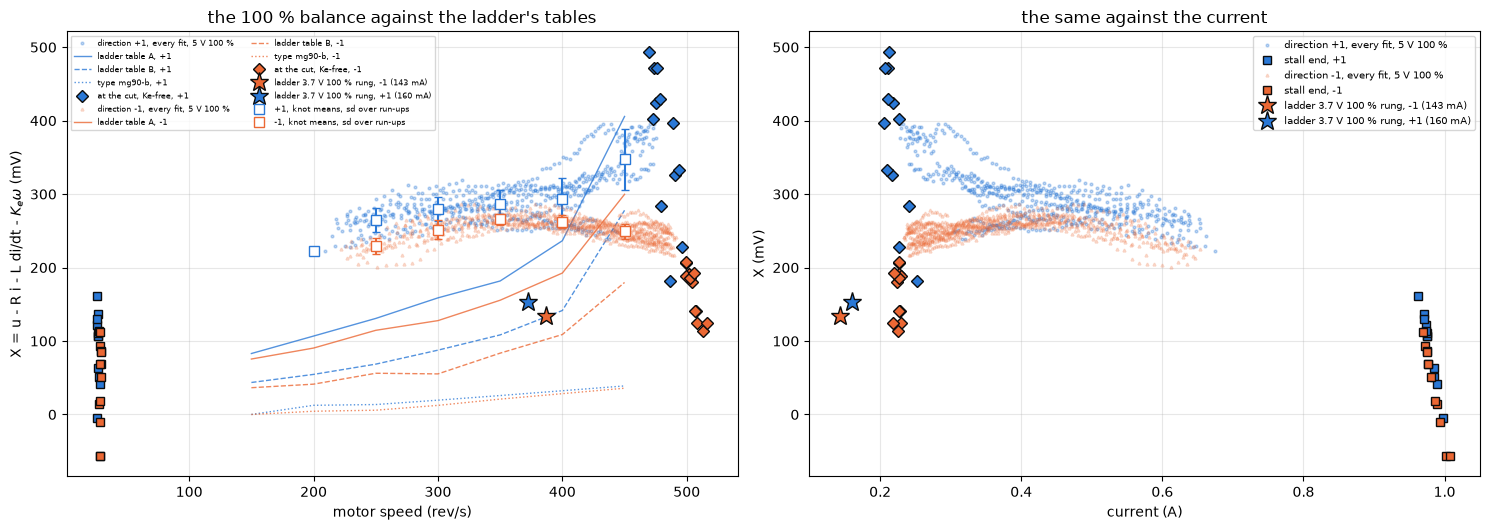

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4))
for d in (1, -1):
    c, g = DIR_COLOR[d], OK_FITS[OK_FITS["dir"] == d]
    for a, xcol in zip(ax, ("rev_s", "i")):
        a.plot(g[xcol], g["x_mv"], ms=2, alpha=0.3,
               **figures.direction_style(d, c),
               label=f"direction {d:+d}, every fit, 5 V 100 %")
    kn = KN[KN.dir == d]
    ax[0].errorbar(kn["rev_s"], kn["x_mv"], yerr=kn["x_sd_runs_mv"], fmt="s",
                   color=c, mfc="white", ms=7, capsize=3,
                   label=f"{d:+d}, knot means, sd over run-ups")
    for col, ls, name in (("ladder_a_mv", "-", "ladder table A"),
                          ("ladder_b_mv", "--", "ladder table B"),
                          ("type_mv", ":", "type mg90-b")):
        ax[0].plot(kn["rev_s"], kn[col], ls, color=c, lw=1, alpha=0.8,
                   label=f"{name}, {d:+d}")
    h, s = CUT[CUT.dir == d], ST[ST.dir == d]
    ax[0].plot(h["w_cut_emf_rev_s"], h["x_cut_mv"], "D", ms=6, color=c,
               mec=INK, label=f"at the cut, Ke-free, {d:+d}")
    ax[1].plot(h["i_end_a"], h["x_cut_mv"], "D", ms=6, color=c, mec=INK)
    for a, xcol in zip(ax, ("w_rev_s", "i")):
        a.plot(s[xcol], s["x_mv"], "s", ms=6, color=c, mec=INK,
               label=f"stall end, {d:+d}" if xcol == "i" else None)
for _, rung in LAD.iterrows():
    d = 1 if rung["rung"].endswith("+1") else -1
    for a, x in zip(ax, (rung["rev_s"], rung["i_a"])):
        a.plot(x, rung["x_mv"], "*", ms=14, color=DIR_COLOR[d], mec=INK,
               label=f"ladder 3.7 V 100 % rung, {d:+d} "
                     f"({rung['i_a'] * 1e3:.0f} mA)")
ax[0].legend(fontsize=6, ncol=2)
ax[1].legend(fontsize=7)
figures.label(ax[0], x="motor speed (rev/s)",
              y="X = u - R i - L di/dt - $K_e \\omega$ (mV)",
              title="the 100 % balance against the ladder's tables")
figures.label(ax[1], x="current (A)", y="X (mV)",
              title="the same against the current")
figures.finish(fig)

The same points colored by their current, and against the product of speed and current. The thing to see is that at one speed the higher current sits higher, and that no single curve in speed alone or in the product runs through the stall ends, the run-up and the ladder's rungs together.

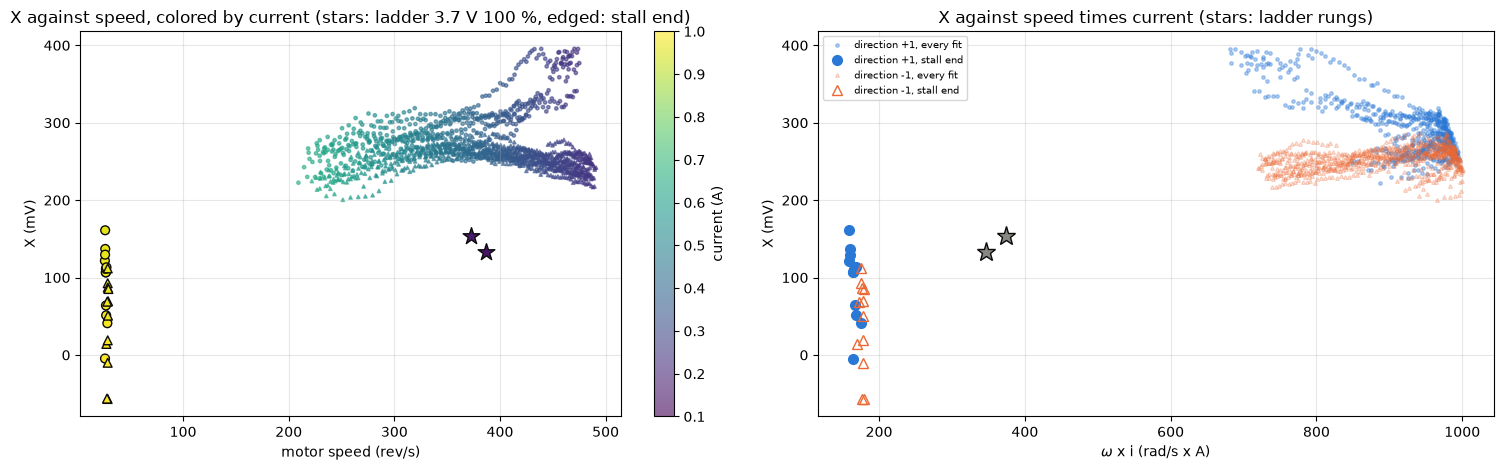

In [69]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for d in (1, -1):
    h = BAL[(BAL.dir == d) & (BAL["where"] == "run-up fit")]
    hs = BAL[(BAL.dir == d) & (BAL["where"] == "stall end")]
    sc = ax[0].scatter(h["rev_s"], h["x_mv"], c=h["i"], cmap="viridis", s=6,
                       alpha=0.6, marker=figures.DIRECTION_MARKER[d],
                       vmin=0.1, vmax=1.0)
    ax[0].scatter(hs["rev_s"], hs["x_mv"], c=hs["i"], cmap="viridis", s=40,
                  marker=figures.DIRECTION_MARKER[d], edgecolors=INK,
                  vmin=0.1, vmax=1.0)
    ax[1].plot(h["wi"], h["x_mv"], ms=2.5, alpha=0.35,
               **figures.direction_style(d, DIR_COLOR[d]),
               label=f"direction {d:+d}, every fit")
    ax[1].plot(hs["wi"], hs["x_mv"], ms=7,
               **figures.direction_style(d, DIR_COLOR[d]),
               label=f"direction {d:+d}, stall end")
for _, rung in LAD.iterrows():
    w_rad = rung["rev_s"] * TWO_PI
    ax[0].scatter([rung["rev_s"]], [rung["x_mv"]], c=[rung["i_a"]],
                  cmap="viridis", s=160, marker="*", edgecolors=INK,
                  vmin=0.1, vmax=1.0)
    ax[1].plot(w_rad * rung["i_a"], rung["x_mv"], "*", ms=14, color=MUTED,
               mec=INK)
fig.colorbar(sc, ax=ax[0], label="current (A)")
figures.label(ax[0], x="motor speed (rev/s)", y="X (mV)",
              title="X against speed, colored by current (stars: ladder "
                    "3.7 V 100 %, edged: stall end)")
ax[1].legend(fontsize=7)
figures.label(ax[1], x="$\\omega$ x i (rad/s x A)", y="X (mV)",
              title="X against speed times current (stars: ladder rungs)")
figures.finish(fig)

### What the balance shows

At 250 to 400 rev/s the run-up's $X$ is 229 to 293 mV at 0.36 to 0.61 A, 1.2 to 2.0 times the ladder's table A and 2.1 to 4.6 times table B at the same speeds, in both directions, and 9 to 39 times the type's. Sitting 1 and sitting 6 agree within 18 mV at every knot. $R$'s bounds move $X$ by 3 to 8 mV, the sag's $K_e$ by -11 to -20 mV and the awake zero by +2 mV.

The ladder's own 100 % rungs on 3.7 V, the one state the two experiments share with nothing switching, read $X$ = 133 mV in direction -1 and 154 in +1 at 387 and 373 rev/s and 0.143 and 0.160 A. The run-up at the same speeds reads 265 sd 9 and 289 sd 22 mV at 0.389 and 0.406 A. Same $R$, same $K_e$, same zero rule, both switching-free, so the 130 mV between them is not a construction of the applied volts. At a matched speed $X$ grows with the current, 0.53 ohm in -1 and 0.55 in +1 over 0.15 to 0.40 A, high confidence that $X$ is not a function of speed alone.

Read as a series resistance, 0.54 ohm would put 530 mV at the stall end, where the rotor turns at about 28 rev/s at 0.98 A and $X$ is 67 sd 59 mV. So $X$ is not a series resistance either. Along the run-up $X$ runs nearly flat against speed, $c_\omega$ 0.044 mV per rad/s, 3.8 % of $K_e$, with the stall ends in and 1.9 % without, while the current falls from 0.68 to 0.23 A. In direction +1 it rises above 420 rev/s, to 347 mV at 450 rev/s and 400 mV by the count at the cut, where that direction drops out. In direction -1 it falls a little, 250 mV at 450 rev/s and 166 mV free of $K_e$ at the cut.

The readings of $X$, with two or more alive.

- (a) A brush contact drop set by speed and current together, larger at mid current than at 1 A or at 0.15 A. It is consistent with every point here and has no independent test in this data. Leading, low to moderate.
- (b) An EMF under drive that falls with the current, $K_e\,\omega\,(1 - k\,i)$, the flux weakened by the armature's own field. The two 100 % loci at 373 and 387 rev/s ask $k$ of 0.19 and 0.20 per A, and the stall end asks next to nothing, its EMF being 0.2 V. The mechanical form $i\,(1 - k\,i)$ returns $k$ = 0.22 per A pooled, but it is not separable from a constant drag, see the inertia, so the mechanical side neither confirms nor kills it. Alive, low.
- (c) The -1 tach 2.3 % low, see the count, accounts for about 80 mV of the -1 $X$ near the cut, the 84 mV between $X$ at the cut by the count and free of $K_e$, and nothing of the +1 side or of the comparison at 380 rev/s. A partial term.
- (d) $R$ under rotation over the locked 4.219 ohm. +0.2 ohm would take 80 to 130 mV out of the run-up's $X$ at 0.4 to 0.65 A, 30 mV out of the ladder's rung and 200 mV out of the stall end, which would then go negative. Alive only as a partial term, candidate.

Two readings are out. $X$ as a speed table alone, the ladder's reading under either construction, fails the matched-speed comparison. A reading-term artifact fails since nothing switches at 100 % and the two zeros agree to 0.4 mA. Regressing $X$ on speed and current together along the run-up would return $u$ itself, since the two move together, and only the stall end, the cut and the ladder's rungs sit off the run-up's line.

### What it says about the ladder's tables A and B

Both tables were read from steady rungs at 0.08 to 0.30 A, and both fall under the 100 % balance at 0.3 to 0.65 A by the current-dependent part above. The 100 % data does not choose between A and B. A's per-volt crest term, 2.6 mS of $V_\mathrm{on}$, would be a 12 mA current at 100 % that makes no torque. The torque balance's intercept runs the other way, -43 mA, so the run-up gives A's 12 mA no support, but that intercept is not separable from the drag ambiguity, a candidate against A. The firmware form $V_b(\omega, \mathrm{dir})$ read at the ladder's currents would under-correct a 100 % run-up by 100 to 150 mV, 14 to 20 rev/s, at 250 to 400 rev/s. The speed estimator needs $X$ as a function of speed and current, or a $K_e$ that depends on the current, before the brush table is settled. The 3.7 V and 5 V 100 % run-ups give two currents at one speed already. A third current at the same speed comes from the load sitting, the arm's gravity load at 100 % or 5 V run-ups with the arm on, about 0.3 A more at every speed, and the locked laps at 24 and 36 % on three rails read $R$ under current with no speed in it.

## Results

The result file's quantities, $J$ and its routes first. `j_kg_m2` is the origin form with the concave and the line forms as its bounds.

In [70]:
q = results.quantity
m = results.mean_sd
mean_se = results.mean_se


def by_dir(df, d):
    # one direction's rows
    return df[df["dir"] == d]


j_origin, j_line = J["j_origin"], J["j"]
j_conc = TM_RUN["j_concave"]            # per run-up, the concave form
OUT = {
    "j_kg_m2": q(j_origin.mean(), j_conc.mean(), j_line.mean(), "kg m^2"),
    "j_origin_kg_m2": mean_se(j_origin, "kg m^2"),
    "j_origin_by_direction": {f"{d:+d}": m(by_dir(J, d)["j_origin"],
                                           "kg m^2") for d in (1, -1)},
    "j_origin_by_set": {s: m(J[J.set == s]["j_origin"], "kg m^2")
                        for s in SETS},
    "j_line_kg_m2": mean_se(j_line, "kg m^2"),
    "j_line_by_direction": {f"{d:+d}": m(by_dir(J, d)["j"], "kg m^2")
                            for d in (1, -1)},
    "j_line_by_set": {s: m(J[J.set == s]["j"], "kg m^2") for s in SETS},
    "j_line_extra_drag_a": m(J["extra_a"], "A"),
    "j_ratio_kg_m2": mean_se(J["j_ratio"], "kg m^2"),
    "j_concave_kg_m2": q(j_conc.mean(), j_conc.mean() - j_conc.std(),
                         j_conc.mean() + j_conc.std(), "kg m^2"),
    "j_concave_k_per_a": q(BOTH["k_mech_per_a"],
                           BOTH["k_mech_per_a"] - BOTH["k_mech_se"],
                           BOTH["k_mech_per_a"] + BOTH["k_mech_se"], "1/A"),
    "j_pooled_fit_rms_rad_s2": {
        "line": q(BOTH["rms_line"], unit="rad/s^2"),
        "origin": q(BOTH["rms_origin"], unit="rad/s^2"),
        "concave": q(BOTH["rms_concave"], unit="rad/s^2")}}

In [71]:
kept = FIT[FIT.res_ok & FIT.win_ok]
OUT.update({
    "j_pooled_coast_kg_m2": mean_se(J["j_pool"], "kg m^2"),
    "j_awake_zero_kg_m2": mean_se(J["j_awake"], "kg m^2"),
    "j_ke_sag_kg_m2": mean_se(J["j_ke_sag"], "kg m^2"),
    "j_type_drag_curve_kg_m2": mean_se(J["j_type_drag"], "kg m^2"),
    "j_over_type": {
        "origin": q(j_origin.mean() / J_TYPE["value"], unit="ratio"),
        "line": q(j_line.mean() / J_TYPE["value"], unit="ratio")},
    "j_windows": q(int(J["n"].sum()), float(kept.t.min()),
                   float(kept.t.max()),
                   "fits, from lo to hi s into the run-up"),
    "coast_drag_current_ma_by_speed": {f"{d:+d}": {
        f"{int(r.rev_s)} rev/s": q(r.drag_current_ma, unit="mA, -J alpha_c "
                                   "/ Kt with j_kg_m2")
        for r in by_dir(DRAG, d).itertuples()} for d in (1, -1)},
    "coast_decel_by_speed_rad_s2": {f"{d:+d}": {
        f"{int(r.rev_s)} rev/s": q(r.alpha_c, r.alpha_c - r.alpha_c_sd,
                                   r.alpha_c + r.alpha_c_sd, "rad/s^2")
        for r in by_dir(DRAG, d).itertuples()} for d in (1, -1)},
    "coast_stop_ms": results.median_range(RUNS["coast_stop_ms"], "ms")})

The rise and the cut. Every "no load" key is the first-order fit's asymptote, an extrapolation past the 52 ms cut.

In [72]:
OUT.update({
    "measured_rise_63_ms": {f"{d:+d}": m(by_dir(RISE, d)["t63_ms"], "ms, "
                                         "to 63 % of the fit's asymptote")
                            for d in (1, -1)},
    "rise_63_of_cut_speed_ms": {f"{d:+d}": m(by_dir(RISE, d)["t63_of_cut_ms"],
                                             "ms") for d in (1, -1)},
    "rise_tau_ms": m(RISE["tau_ms"], "ms"),
    "rise_fit_rms_rev_s": m(RISE["rise_rms_rev_s"], "rev/s"),
    "no_load_speed_rev_s": q(
        RISE["w_inf_rev_s"].mean(), by_dir(RISE, 1)["w_inf_rev_s"].mean(),
        by_dir(RISE, -1)["w_inf_rev_s"].mean(), "rev/s, the first-order "
        "fit's asymptote, extrapolated past the 52 ms cut"),
    "no_load_speed_by_direction": {f"{d:+d}": m(
        by_dir(RISE, d)["w_inf_rev_s"], "rev/s, extrapolated")
        for d in (1, -1)},
    "speed_at_cut_rev_s": {f"{d:+d}": m(by_dir(RISE, d)["w_cut_rev_s"],
                                        "rev/s") for d in (1, -1)},
    "speed_at_cut_coast_e0_rev_s": {f"{d:+d}": m(
        by_dir(RUNS, d)["w_cut_emf_rev_s"], "rev/s") for d in (1, -1)},
    "cut_over_no_load": m(RISE["cut_over_inf"], "ratio")})

The curve through the gears, its ends and peaks, the terminal source line, and the comparison at the horn.

In [73]:
stalls = [KEY[d]["stall_line_mnm"] * 1e-3 for d in (1, -1)]
best_p, best_e = BIN["p_out"].idxmax(), BIN["eff"].idxmax()   # mN m bins
p_src = np.polyfit(kept["i"], kept["u"], 1)   # u = v_s - r_s i
OUT.update({
    "stall_current_a": m(RUNS["i_stall_a"], "A"),
    "stall_terminal_v": m(RUNS["u_stall_v"], "V"),
    "stall_torque_n_m": q(np.mean(stalls), min(stalls), max(stalls), "N m"),
    "stall_torque_first_ms_n_m": q(T_STALL_DIRECT, unit="N m"),
    "peak_power_w": q(BIN["p_out"].max(),
                      min(KEY[d]["p_max_w"] for d in (1, -1)),
                      max(KEY[d]["p_max_w"] for d in (1, -1)), "W"),
    "peak_power_per_run_w": m(PEAK["p_max_w"], "W"),
    "peak_power_line_j_w": q(P_LINE_J, unit="W"),
    "peak_power_torque_n_m": q(best_p * 1e-3, unit="N m"),
    "peak_power_rev_s": q(BIN.loc[best_p, "rev_s"], unit="rev/s"),
    "peak_efficiency": q(BIN["eff"].max(),
                         min(KEY[d]["eff_max"] for d in (1, -1)),
                         max(KEY[d]["eff_max"] for d in (1, -1)), ""),
    "peak_efficiency_torque_n_m": q(best_e * 1e-3, unit="N m"),
    "key_numbers_by_direction": {f"{d:+d}": {k: float(v) for k, v in
                                             KEY[d].items()}
                                 for d in (1, -1)},
    "curve": [{"torque_mnm": round(float(t), 3), "n": int(r.n),
               "speed_rev_s": round(float(r.rev_s), 2),
               "current_a": round(float(r.i), 5),
               "terminal_v": round(float(r.u), 4),
               "power_w": round(float(r.p_out), 5),
               "efficiency": round(float(r.eff), 4)}
              for t, r in BIN.iterrows()],
    "terminal_source": {"form": "u = v_s - r_s i at the motor's terminals "
                        "over the acceleration fits",
                        "v_s": q(p_src[1], unit="V"),
                        "r_s": q(-p_src[0], unit="ohm")},
    "output_side_lossless": {
        "stall_torque_n_m": q(np.mean(stalls) * GEAR,
                              unit="N m at the horn before gear loss"),
        "no_load_speed_deg_s": q(RISE["w_inf_rev_s"].mean() / GEAR * 360,
                                 unit="deg/s at the horn, extrapolated")}})

The count, the dropouts and the balance.

In [74]:
n_fits, n_out = int(RUNS["fits"].sum()), len(FIT) - len(kept)
OUT.update({
    "speed_count_start_ms": q(RUNS["first_window_ms"].mean(),
                              RUNS["first_window_ms"].min(),
                              RUNS["first_window_ms"].max(), "ms"),
    "speed_count_start_rev_s": q(RUNS["first_window_rev_s"].mean(),
                                 RUNS["first_window_rev_s"].min(),
                                 RUNS["first_window_rev_s"].max(), "rev/s"),
    "crossings_total": q(int(RUNS["crossings"].sum()), unit="count"),
    "crossings_repaired": q(int(RUNS["added"].sum() + RUNS["removed"].sum()),
                            unit="count"),
    "windows_flagged": q(int(RUNS["windows_flagged_all"].sum()),
                         unit=f"of {int(RUNS['windows'].sum())} turn windows"),
    "fits_flagged": q(int(RUNS["fits_win_flagged"].sum()
                          + RUNS["fits_flagged"].sum()),
                      unit=f"of {n_fits} fits, the two flags' counts added, "
                           f"a fit failing both counted twice; {n_out} "
                           f"left out"),
    "count_over_cut_emf_by_direction": {f"{d:+d}": m(
        by_dir(RUNS, d)["w_end_count_rev_s"]
        / by_dir(RUNS, d)["w_cut_emf_rev_s"], "ratio") for d in (1, -1)},
    "oscnb_count_over_order_count": {f"{d:+d}": m(
        by_dir(TC, d)["oscnb_count_rev_s"]
        / by_dir(TC, d)["order_count_rev_s"], "ratio") for d in (1, -1)},
    "pot_over_count_15_45ms": m(RUNS["pot_over_count_15_45ms"], "ratio, "
                                "nominal pot slope x gear over the count"),
    "emf_seed_count_maxdiff_pct": results.median_range(
        RUNS["emf_seed_speed_maxdiff_pct"], "%")})

In [75]:
OUT.update({
    "dropouts_per_s_by_direction_and_set": {
        f"{int(r.dir):+d} {r.set}": results.pm(r.rate_per_s, r.rate_se, "1/s")
        for r in DROP.itertuples()},
    "dropouts_last20ms_per_s_by_direction_and_set": {
        f"{int(r.dir):+d} {r.set}": results.pm(r.rate_last20_per_s,
                                               r.rate_last20_se, "1/s")
        for r in DROP.itertuples()},
    "dropouts_per_s_by_direction_and_sitting": {
        f"{int(r.dir):+d} sitting {int(r.sitting)}": results.pm(
            r.rate, r.se, "1/s") for r in BY_SIT.itertuples()},
    "dropouts_plus_sitting6_over_1_sigma": q(SIT_SIGMA,
                                             unit="sigma, Poisson"),
    "dropouts_per_s_by_speed": {
        f"{int(r.dir):+d} sitting {int(r.sitting)} {int(r.rev_s)} rev/s":
            results.pm(r.rate_per_s, r.rate_se, "1/s")
        for r in SPB.itertuples()},
    "dropout_rows_per_run": {r.tag: q(r.dropouts, unit="rows in 52 ms")
                             for r in RUNS.itertuples()}})

In [76]:
OUT.update({
    "x_100pct_mv_by_knot": {
        f"{int(r.dir):+d} {int(r.rev_s)} rev/s": q(
            r.x_mv, r.x_mv - r.x_sd_runs_mv, r.x_mv + r.x_sd_runs_mv,
            f"mV, +/- sd over {int(r.n_runs)} runs, at {r.i_a:.3f} A")
        for r in KN.itertuples() if r.n_runs >= 3},
    "x_100pct_ladder_a_mv_by_knot": {
        f"{int(r.dir):+d} {int(r.rev_s)} rev/s": q(r.ladder_a_mv,
                                                  unit="mV, quoted")
        for r in KN.itertuples() if np.isfinite(r.ladder_a_mv)},
    "x_100pct_ladder_b_mv_by_knot": {
        f"{int(r.dir):+d} {int(r.rev_s)} rev/s": q(r.ladder_b_mv,
                                                  unit="mV, quoted")
        for r in KN.itertuples() if np.isfinite(r.ladder_b_mv)},
    "x_cut_e0_mv_by_direction": {f"{d:+d}": m(
        by_dir(CUT, d)["x_cut_mv"], "mV, Ke-free, E0 from the coast")
        for d in (1, -1)},
    "x_cut_count_mv_by_direction": {f"{d:+d}": m(
        by_dir(CUT, d)["x_cut_count_mv"], "mV, by the count")
        for d in (1, -1)},
    "x_stall_end_mv": q(ST.x_mv.mean(), ST.x_mv.mean() - ST.x_mv.std(),
                        ST.x_mv.mean() + ST.x_mv.std(),
                        "mV, 0.8 to 1.5 ms, +/- sd"),
    "x_vs_ladder_100_dx_di_ohm": {f"{int(r.dir):+d}": q(
        r.dx_over_di_ohm, unit=f"ohm, from {r.ladder_i_a:.3f} to "
        f"{r.runup_i_a:.3f} A at {r.rev_s:.0f} rev/s")
        for r in XI.itertuples()},
    "awake_zero_step_counts": m(RUNS["awake_step_counts"], "counts over the"
                                " rest zero, the coast's last 100 ms"),
    "crest_less_coast_zero_minus_stage1_ma": q(
        (RUNS["awake_step_counts"].mean() - I_DRIVE_OFFSET) * A_PER_COUNT
        * 1e3, unit="mA, the two zeros' difference at 100 %"),
    "x_speed_table_fit_rms_mv": q(
        SPEED_TABLE["fits + stall"]["rms_mv"],
        unit="mV, X = c0 + c_dir + c_w w over fits + stall")})

The checks, the conditions and the constants quoted.

In [77]:
OUT.update({
    "rows_missing": q(int(RUNS["missing"].sum()), unit="rows"),
    "rows_dropped": q(int(RUNS["rows_dropped"].sum()), unit="rows"),
    "current_raw_max": q(int(RUNS["raw_max"].max()), unit="counts"),
    "spin_ms": q(int(RUNS["spin_ms"].iloc[0]),
                 unit="ms, the runway's cut of the 200 ms asked"),
    "rail_v": results.median_range(RUNS["rail_v"], "V, manifest probe "
                                   "before each sweep"),
    "board_ntc_c_by_sitting": {f"{s}": results.median_range(
        RUNS[RUNS.sitting == s]["ntc_c"], "C") for s in (1, 6)},
    "ke_used_mv_per_rev_s": q(KE_LADDER_MV, unit="mV per rev/s, the ladder "
                              "result, quoted"),
    "r_used_ohm": q(R_LOCKED, R_LOCKED_LO, R_LOCKED_HI,
                    "ohm, the resistance result's r_term_ohm, quoted"),
    "l_used_mh": q(L_H * 1e3, unit="mH, the inductance result, quoted"),
    "j_type_kg_m2": q(J_TYPE["value"], J_TYPE["lo"], J_TYPE["hi"],
                      "kg m^2, mg90-b stage 2, quoted")})
print(f"{len(OUT)} keys")

81 keys


### The result file

The notes that define every key. Report-only keys describe this capture and set no firmware number. Candidate keys rest on one route or under 2 sigma. Extrapolated keys come from the first-order fit's asymptote past the 52 ms cut, or from the curve's line past its counted part.

In [78]:
NOTES = (
    "stage 3 run-up of mg90-d on dev-v006-2A-D, horn free, DPS-150 over the"
    " feed diode, experiment image: runup-open-1, runup-close-1, "
    "runup-open-6 and runup-close-6, three cycles each of a 5 V 100 % spin "
    "from rest at the near guard and a 500 ms coast with the bridge open, "
    "both directions, at the open and the close of sittings 1 and 6; the "
    "runway cut the 200 ms spin to 52 ms (1031 to 1040 driven rows). "
    "Current through stage 1 current-scale over each sweep's torque-off "
    "zero with the in-drive offset out, the crest sample, which at 100 % is"
    " the period mean; volts through terminal-chain; rail and board NTC "
    "from the manifest probe before each sweep. R the resistance result's "
    "r_term_ohm, L the inductance result's l_mh, Ke the ladder result's "
    "ke_mv_per_rev_s, Kt = Ke untested. Speed by the ripple tach, stage 2 "
    "speed-torque's order tracking (6 events per rev, band-pass +/- 25 %, "
    "five passes, the current's integral before the tenth crossing), its "
    "rough speed the EMF u - R i - L di/dt over Ke scaled to the pot's slope"
    " over 15 to 45 ms; the pot seeds only. Acceleration a_d from a "
    "quadratic of the counted angle over +/- 5 ms every 0.5 ms; fits kept "
    "when the angle residual is under twice the run's median and no turn "
    "window inside them is flagged (local quadratic at 5 %, cross-run "
    "median at 6 %). Coast a_c(w) from a quadratic of the bridged coast EMF"
    " over +/- 5 ms, interpolated on speed per run-up. "
    "j_kg_m2: J of the rotor plus the reflected train, J (a_d - a_c(w)) = "
    "Kt i through the origin, the mean over 24 run-ups; lo the concave form"
    " i (1 - k i) per run-up mean, hi the line with an intercept per run-up "
    "mean; the bounds are the method's ambiguity between three forms that "
    "fit to the same residual, not noise. j_origin_kg_m2 the same +/- se; "
    "*_by_direction and *_by_set mean +/- sd; j_line_* stage 2's line, "
    "j_line_extra_drag_a its intercept as a current (negative: the drive "
    "carries less drag than the coast), a fit-form property and not a "
    "measured drag; j_ratio the median of Kt i / (a_d - a_c) per run-up, "
    "+/- se; j_concave_kg_m2 the concave form per run-up, mean +/- sd over "
    f"the {len(TM_RUN)} run-ups whose fit converged ({', '.join(failed)} "
    "did not); "
    "j_concave_k_per_a its k pooled, +/- se; j_pooled_fit_rms_rad_s2 the "
    "three pooled forms' rms. ")

In [79]:
NOTES += (
    "j_pooled_coast, j_awake_zero, j_ke_sag, j_type_drag_curve: the line's J"
    " under the direction's pooled coast, the awake-zero current, the sag's"
    " Ke, and the type's bare drag curve in place of the coast, +/- se, "
    "alternatives. j_over_type over mg90-b's j_kg_m2 (j_type_kg_m2, quoted)."
    " j_windows the kept fits, lo and hi their first and last center in s. "
    "coast_drag_current_ma_by_speed: -J a_c / Kt with j_kg_m2 in 25 rev/s "
    "bins per direction, the train's drag as a current, scale tied to J; "
    "coast_decel_by_speed_rad_s2 the bins' median a_c +/- sd; coast_stop_ms"
    " median and range. measured_rise_63_ms: t0 + tau of a first-order fit "
    "through the turn windows, to 63 % of its asymptote, mean +/- sd per "
    "direction (the type's was to a measured settled speed); "
    "rise_63_of_cut_speed_ms to 63 % of the speed at the cut, model free; "
    "rise_tau_ms, rise_fit_rms_rev_s mean +/- sd. no_load_speed_rev_s and "
    "no_load_speed_by_direction: the fit's asymptote, EXTRAPOLATED about 10 "
    "% past the 52 ms cut, a candidate no-load speed at 5 V; value the mean,"
    " lo and hi the +1 and -1 means. speed_at_cut_rev_s the count's last "
    "5 ms; speed_at_cut_coast_e0_rev_s the coast's E0 (line over 1 to 6 ms "
    "back to the cut) over Ke; cut_over_no_load the cut over the asymptote. "
    "stall_current_a and stall_terminal_v: 0.8 to 1.5 ms, mean +/- sd. "
    "stall_torque_n_m: the torque-on-speed line per direction at zero "
    "speed, mean with the two directions as bounds; "
    "stall_torque_first_ms_n_m Kt (stall current - the coast's drag under "
    "60 rev/s). peak_power_w: the pooled 0.05 mN m bins' median J a_d w, "
    "bounds the per-direction peaks; peak_power_per_run_w per run-up "
    "+/- sd; peak_power_line_j_w the same under the line's J (x 1.10); "
    "peak_power_torque_n_m and peak_power_rev_s the peak's bin. "
    "peak_efficiency the bins' median J a_d w / (u i) at the terminals, "
    "bounds by direction, peak_efficiency_torque_n_m its bin. Every torque "
    "and power scales with J and carries its bracket. ")

In [80]:
NOTES += (
    "key_numbers_by_direction: per direction the line's stall and zero-"
    "torque ends (w0 extrapolated past the counted part), the peaks of "
    "power and efficiency, the cut and the asymptote, report only. curve: "
    "the pooled bins with at least 10 fits. terminal_source the line of u "
    "on i over the fits, report only. output_side_lossless the stall torque"
    " x the gear ratio and the asymptote at the horn, before gear loss, "
    "comparison only, the no-load speed extrapolated. "
    "speed_count_start_ms and _rev_s the first turn window, mean with "
    "range; crossings_total, crossings_repaired (added + removed), "
    "windows_flagged (either window flag), fits_flagged (the residual "
    "flag's count plus the window flag's), report only. "
    "count_over_cut_emf_by_direction: the count's last 5 ms over E0 / Ke, "
    "mean +/- sd; the -1 count ends about 2.3 % under (the last row 2.4 %),"
    " the -1 tach undercounting the leading reading, moderate. "
    "oscnb_count_over_order_count ripple.count_cycles over the order count "
    "on the last 10 ms, mean +/- sd. pot_over_count_15_45ms the nominal pot"
    " slope over the count, the pot's local gain, a seed only. "
    "emf_seed_count_maxdiff_pct the EMF-only seed's count against the pot "
    "seed's, worst speed difference past 10 ms per run-up, median and "
    "range; one run-up fails at 28.5 %. "
    "dropouts_*: tel.dropout_rows (quarter of a running mean) over the "
    "drive, its first 2 ms and last 1 ms left out, rows per second +/- "
    "Poisson (one row as an empty count's floor); by direction and set, "
    "over the last 20 ms, by sitting, by 50 rev/s band of the count's speed"
    " (bands over 400 rows); dropouts_plus_sitting6_over_1_sigma the +1 "
    "rise from sitting 1 to 6 in Poisson sigma, likely; dropout_rows_per_run"
    " the rows per run-up. The settled rate is not measured. ")

In [81]:
NOTES += (
    "x_100pct_mv_by_knot: X = u - R i - L di/dt - Ke w over the kept fits "
    "within 12.5 rev/s of each knot, mean +/- sd over the run-ups there (3 "
    "or more), the current in the unit; x_100pct_ladder_a and _b the "
    "ladder's tables 'A - g V_on' and 'B - g (1-D) V_on' at the knots, "
    "quoted. x_cut_e0_mv_by_direction u - R i - E0 over the drive's last "
    "5 ms, Ke-free, mean +/- sd; x_cut_count_mv by the count's speed. "
    "x_stall_end_mv X at 0.8 to 1.5 ms with the speed from the current's "
    "integral, +/- sd. x_vs_ladder_100_dx_di_ohm the run-up's X less the "
    "ladder's 3.7 V 100 % rung's at matched speed over the current "
    "difference, X's growth with current at one speed, high confidence that"
    " X is not a speed table alone; not a series resistance (the stall end "
    "reads 67 mV). Readings alive: a brush drop set by speed and current "
    "(leading, low to moderate), an EMF falling with current (low), the -1"
    " tach and a running R (partial). The 100 % data does not choose "
    "between the ladder's tables A and B. awake_zero_step_counts the coast"
    "'s last 100 ms over the rest zero, mean +/- sd; "
    "crest_less_coast_zero_minus_stage1_ma that zero less stage 1's in-"
    "drive offset as a current, the 100 % check of the inductance result's"
    " reading term (absent at 100 % to 0.5 mA). x_speed_table_fit_rms_mv "
    "the rms of X = c0 + c_dir + c_w w over the fits and the stall ends, "
    "report only. rows_missing, rows_dropped, current_raw_max, spin_ms, "
    "rail_v (median, range), board_ntc_c_by_sitting: the capture's checks "
    "and conditions, report only. ke_used, r_used, l_used, j_type: quoted.")

The result file, then every numeric key as written.

In [82]:
CAPTURE = ", ".join(str(results.rel(RUNUP / name)) for name in SETS)
path = results.write("3-servo", "run-up", CAPTURE, pair=PAIR, notes=NOTES,
                     **OUT)
written = results.read("3-servo", "run-up", pair=PAIR)
print("wrote", path, "with", len(written), "top-level keys, capture",
      written["capture"])


def flatten(prefix, value, rows):
    # every quantity in the file, nested keys joined with dots
    if isinstance(value, dict) and "value" in value:
        rows.append({"key": prefix, **value})
    elif isinstance(value, dict):
        for k, v in value.items():
            flatten(f"{prefix}.{k}" if prefix else k, v, rows)


flat = []
for k, v in written.items():
    if k not in ("curve", "key_numbers_by_direction"):
        flatten(k, v, flat)
FLAT = pd.DataFrame(flat)
print(f"{len(FLAT)} numeric rows")
with pd.option_context("display.max_rows", None,
                       "display.max_colwidth", 60):
    show(FLAT, n=None)

wrote stages/3-servo/run-up/results/mg90-d__dev-v006-2A-D.json with 83 top-level keys, capture telemetry/mg90-d__dev-v006-2A-D/run-up/runup-open-1, telemetry/mg90-d__dev-v006-2A-D/run-up/runup-close-1, telemetry/mg90-d__dev-v006-2A-D/run-up/runup-open-6, telemetry/mg90-d__dev-v006-2A-D/run-up/runup-close-6
273 numeric rows


,key,value,lo,hi,unit
0,j_kg_m2,0.000,0.000,0.000,kg m^2
1,j_origin_kg_m2,0.000,0.000,0.000,kg m^2
2,j_origin_by_direction.+1,0.000,0.000,0.000,kg m^2
3,j_origin_by_direction.-1,0.000,0.000,0.000,kg m^2
4,j_origin_by_set.runup-open-1,0.000,0.000,0.000,kg m^2
5,j_origin_by_set.runup-close-1,0.000,0.000,0.000,kg m^2
6,j_origin_by_set.runup-open-6,0.000,0.000,0.000,kg m^2
7,j_origin_by_set.runup-close-6,0.000,0.000,0.000,kg m^2
8,j_line_kg_m2,0.000,0.000,0.000,kg m^2
9,j_line_by_direction.+1,0.000,0.000,0.000,kg m^2


The headline keys as written.

In [83]:
for key, scale, unit in (("j_kg_m2", 1e9, "x 1e-9 kg m^2"),
                         ("j_origin_kg_m2", 1e9, "x 1e-9 kg m^2"),
                         ("j_line_kg_m2", 1e9, "x 1e-9 kg m^2"),
                         ("j_concave_kg_m2", 1e9, "x 1e-9 kg m^2"),
                         ("j_line_extra_drag_a", 1e3, "mA"),
                         ("rise_tau_ms", 1, "ms"),
                         ("no_load_speed_rev_s", 1, "rev/s, extrapolated"),
                         ("stall_torque_n_m", 1e3, "mN m"),
                         ("stall_torque_first_ms_n_m", 1e3, "mN m"),
                         ("peak_power_w", 1, "W"),
                         ("peak_power_torque_n_m", 1e3, "mN m"),
                         ("peak_efficiency", 1, ""),
                         ("x_stall_end_mv", 1, "mV"),
                         ("dropouts_plus_sitting6_over_1_sigma", 1, "sigma")):
    r = written[key]
    span = ("" if r["lo"] is None
            else f" ({r['lo'] * scale:.4g} to {r['hi'] * scale:.4g})")
    print(f"{key}: {r['value'] * scale:.4g}{span} {unit}")
for key in ("measured_rise_63_ms", "count_over_cut_emf_by_direction",
            "x_cut_e0_mv_by_direction", "x_vs_ladder_100_dx_di_ohm"):
    print(key + ": " + ", ".join(f"{d} {v['value']:.4g}"
                                 for d, v in written[key].items()))

j_kg_m2: 6.433 (5.86 to 7.075) x 1e-9 kg m^2
j_origin_kg_m2: 6.433 (6.401 to 6.466) x 1e-9 kg m^2
j_line_kg_m2: 7.075 (6.988 to 7.161) x 1e-9 kg m^2
j_concave_kg_m2: 5.86 (5.525 to 6.195) x 1e-9 kg m^2
j_line_extra_drag_a: -42.82 (-70.46 to -15.18) mA
rise_tau_ms: 20.43 (19.63 to 21.24) ms
no_load_speed_rev_s: 533.7 (521.9 to 545.5) rev/s, extrapolated
stall_torque_n_m: 1.046 (1.042 to 1.049) mN m
stall_torque_first_ms_n_m: 1.083 mN m
peak_power_w: 0.9061 (0.864 to 0.9305) W
peak_power_torque_n_m: 0.625 mN m
peak_efficiency: 0.3898 (0.373 to 0.4003) 
x_stall_end_mv: 67.26 (8.562 to 126) mV
dropouts_plus_sitting6_over_1_sigma: 2.556 sigma
measured_rise_63_ms: +1 19.78, -1 20.21
count_over_cut_emf_by_direction: +1 0.9916, -1 0.9773
x_cut_e0_mv_by_direction: +1 370.1, -1 166.3
x_vs_ladder_100_dx_di_ohm: -1 0.5328, +1 0.5488


## Limitations

- One servo, one board, two sittings two days apart, 24 run-ups, all on 5 V. The spin is 52 ms, cut by the runway, so the run-up holds no settled speed, no settled current and no settled dropout rate.
- The speed has no outside ruler. It is the ripple counted at six events per revolution, a parts count, and the -1 count ends about 2.3 % under the coast's EMF at the cut.
- $K_t = K_e$ is assumed and not tested. $J$ is read with it, and every torque here scales with $K_t$.
- $J$ is open to the span of its three forms, 5.86 to 7.08 x $10^{-9}$ kg m$^2$, since along a 100 % run-up the current falls as the speed rises and a drag the coast misses is not separable from a torque per amp that falls with the current.
- Every current goes through current-scale's counts per amp, whose absolute class is 2 % of the reading. $J$ scales one for one with it.
- The coast's deceleration table starts 6 ms past the cut, so the drive's last 20 rev/s or so take the coast's top value.
- The count starts at 174 to 220 rev/s, so the stall end of the curve is read only in the first millisecond and the light end, under 0.1 mN m, not at all.
- The gear's efficiency is not measured, so the output-side numbers are lossless multiplications.
- Dropout counts are small, 0 to 12 rows per set and direction, so every rate carries a wide Poisson bar.
- $X$ is read at one current per speed along the run-up, so its dependence on speed and on current is separated only by the stall end, the cut and the ladder's 3.7 V rungs.

## Open questions

1. $J$ by form, 6.43 through the origin against 7.08 for the line with a -43 mA intercept and 5.86 for the concave form, with equal residuals. Candidates are a drag under drive that differs from the coast's at the same speed, from mesh load or iron loss under current, a torque per amp that falls with the current, and the collinearity of a run-up alone. Run-ups at a second current level at the same speeds separate them, the arm's load or 3.7 V 100 % run-ups, three cycles, at about 160 mA where this one has 400, since two currents at one speed break the collinearity. A scale-arm stall torque reads $K_t$.
2. $J$ through the origin splits by direction, +3.9 %, 6.8 sigma by the per-run spread. Candidates are the -1 tach undercounting by about 2.3 %, which moves the -1 $J$ by about as much, a real asymmetry in the coast's drag or in the brushes, +1 dropping out and -1 not, and the +1 count's flags, 37 of the 41 flagged windows. The tests of 1 and 3, and the per-direction read on the 3.7 V 100 % rung, separate them.
3. The -1 count ends about 2.3 % under the coast's $E_0$ while the two tach implementations agree to 0.1 % and +1 agrees with $E_0$ to 0.8 %. Candidates are the -1 tach undercounting at 450 to 500 rev/s, mg90-c's record, leading, moderate, and a -1 coast EMF 2 % high in its first 13 ms, with no mechanism, since the ladder's $K_e$ by direction agrees to 0.08 %. A settled -1 100 % spin with the pot read over whole turns, or the camera on a run-up, separates them.
4. $X$ at 100 % is 1.2 to 4.6 times the ladder's tables at the same speed and grows with the current at matched speed, 0.54 ohm over 0.15 to 0.40 A, but is only 67 mV at 0.98 A and 28 rev/s. Candidates are a brush drop set by speed and current together, leading, an EMF or $K_t$ that falls with current, a running $R$ over the locked one, partial, and the -1 tach, partial and -1 only. A third current at one speed separates them, the load sitting at 100 % or the 3.7 V against 5 V run-ups reduced with this notebook's code, with the resistance notebook's locked laps at 24 and 36 % on three rails for $R$ under current with no speed.
5. The rise to 63 %, 20.0 sd 0.5 ms against the type's 19.0 and 19.5, 2 sigma and measured against an extrapolated asymptote. Candidates are $J$ 3 % up with the train's drag, since a first-order fit's $\tau$ is $J R / (K_t K_e)$ only under a constant drag and a stiff source, and the extrapolation itself. A settled 100 % spin separates them. It does not fit inside the runway, so the pot-table sitting's camera clip of a 100 % run-up across the travel would do it once.
6. Dropouts in +1 rose from sitting 1 to 6, 26 to 71 per second, 2.6 sigma, with no change in $J$, the rise or $X$ between the sittings. Candidates are the brushes bedding after the locked sittings' 0.77 A laps and bursts, and a day's rest. The next sitting's open bracket against this one's close, and the ladder's reference rung, whose dropouts were zero at 5 V 30 % throughout, separate them.

The data does not settle the settled speed and current at 5 V 100 %, $J$ to better than the span of its three forms with $K_t = K_e$ assumed, $K_t$ itself, which of a drag under drive, a torque per amp falling with current and a brush drop set by current makes the line's intercept and the 100 % $X$, the ladder's construction A against B, the -1 tach's 2.3 % against the coast's EMF, the gear's efficiency, the light end of the curve, the dropout rate at a settled 100 %, or whether the +1 and -1 split in $J$ is the tach or the plant.

## Conclusion

mg90-d's rotor plus its reflected train reads $J$ = 6.43 +/- 0.03 x $10^{-9}$ kg m$^2$ through the origin, sd 2.5 % over 24 run-ups, 1.03 of the type's bare rotor, with no drift between the two sittings. The line with an intercept gives 7.08 with a -43 mA intercept and the concave form 5.86, to the same residual, and that span is the method's ambiguity, not noise. The two directions split by +3.9 %, its cause open. The rise to 63 % takes 20.0 sd 0.5 ms toward an asymptote of 534 sd 13 rev/s, the fit's extrapolation past the cut, and the rotor reaches 483 sd 9 rev/s at the 52 ms cut.

Through the gears at the motor the speed falls along a line to a stall torque of 1.046 mN m by the lines and 1.083 in the first millisecond, and the output power peaks at 0.906 W at 0.625 mN m, 7 % under the bare type, about the size of the train's drag. The coast's drag grows from 43 mA at the stop to 160 mA at 462 rev/s.

Direction +1 drops out above 350 rev/s, 26 rows per second over the drive in sitting 1 and 71 in sitting 6, 2.6 sigma, likely, and direction -1 hardly at all. At 100 % the two current zeros agree to 0.42 mA, so the reading term is absent where nothing switches. The voltage balance at 100 % reads 230 to 290 mV at 250 to 400 rev/s, over both of the ladder's tables, and grows with the current at a matched speed by 0.54 ohm while reading only 67 mV at the stall end, so it is neither a speed table alone nor a series resistance. A brush drop set by speed and current together is the leading reading, low to moderate, and the 100 % data does not choose between the ladder's tables A and B.